# Machine-Learning Prediction of Drug Concentration–Time Profiles in Skin after Microneedle (MN) Application

**Dataset:** `data.csv` (1,200 rows = 150 patches × 8 time points). **Target:** `Skin_Tissue_Conc_ug_cm3`.

## How to read this notebook

Three kinds of statements are kept separate throughout:

| Tag | Meaning |
|---|---|
| **[OBSERVED]** | A number or pattern computed directly from `data.csv`. |
| **[MODEL]** | A prediction or a statistic from a trained model, always on patches the model had not seen. |
| **[ASSUMPTION]** | A modelling choice or a scientific interpretation that the data alone cannot prove. |

## Validation principle (applies to everything below)

Each patch contributes 8 correlated rows. **Every split in this notebook is made on `Patch_ID`, never on rows**, so that a patch is either entirely in training or entirely in testing. Section 7 demonstrates how much a naïve row-wise split would inflate the scores.

## Contents
1. Imports & configuration · 2. Load data · 3. Data inspection · 4. Exploratory data analysis · 5. Pre-processing · 6. Feature engineering · 7. Group-aware splitting · 8. Baseline models · 9. Model comparison (two strategies) · 10. Hyper-parameter tuning · 11. Final model training · 12. Evaluation (incl. Cmax / Tmax / AUC) · 13. Human-skin analysis (Approach A vs B) · 14. Interpretation · 15. Concentration-time prediction function · 16. Prediction for a new formulation · 17. Saving artefacts

## 1. Imports and configuration

In [1]:
import os, sys, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.interpolate import PchipInterpolator
from scipy.integrate import trapezoid
from scipy.stats import loguniform, randint

import sklearn, joblib
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, GroupShuffleSplit, KFold, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor, HistGradientBoostingRegressor)
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.base import clone

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95)
plt.rcParams['figure.dpi'] = 100

# Optional libraries: used only if installed.
try:
    import xgboost; HAS_XGB = True
except Exception: HAS_XGB = False
try:
    import catboost; HAS_CAT = True
except Exception: HAS_CAT = False
try:
    import shap; HAS_SHAP = True
except Exception: HAS_SHAP = False

OUT = Path('mn_outputs'); (OUT / 'figures').mkdir(parents=True, exist_ok=True); (OUT / 'models').mkdir(exist_ok=True)
def savefig(name):
    plt.savefig(OUT / 'figures' / f'{name}.png', dpi=130, bbox_inches='tight')

print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| sklearn', sklearn.__version__)
print('Optional libraries -> XGBoost:', HAS_XGB, '| CatBoost:', HAS_CAT, '| SHAP:', HAS_SHAP)

python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | sklearn 1.8.0
Optional libraries -> XGBoost: False | CatBoost: False | SHAP: False

## 2. Load the dataset

In [2]:
CANDIDATES = ['data.csv', 'data_1.csv', '/mnt/user-data/uploads/data.csv']
DATA_PATH = next(p for p in CANDIDATES if Path(p).exists())
raw = pd.read_csv(DATA_PATH)
print('Loaded', DATA_PATH, '->', raw.shape)
raw.head(8)

Loaded /mnt/user-data/uploads/data.csv -> (1200, 17)

,Patch_ID,Drug_Name,Skin_Type,Skin_Thickness_mm,MN_Material,MN_Type,Patch_Area_cm2,Needle_Count,Needle_Height_um,Needle_Base_Width_um,Applied_Force_N,Initial_Drug_Loading_mg,Drug_MW_Da,Drug_logP,Time_Hours,Skin_Tissue_Conc_ug_cm3,Is_Large_Peptide
0,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,0.5,3.76,0
1,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,1.0,8.03,0
2,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,2.0,20.19,0
3,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,4.0,43.71,0
4,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,6.0,42.54,0
5,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,8.0,43.18,0
6,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,12.0,35.19,0
7,PATCH-101,Metformin,Porcine Skin,1.13,Hyaluronic Acid,Dissolving,1.39,196,719.6,289.8,17.0,5.13,129.16,-1.4,24.0,20.89,0


## 3. Data inspection

Before modelling we check the *structure* of the data: it determines which questions the data can answer.

In [3]:
TIMES = [0.5, 1, 2, 4, 6, 8, 12, 24]
TARGET = 'Skin_Tissue_Conc_ug_cm3'

print('Shape:', raw.shape, '| missing values:', int(raw.isna().sum().sum()), '| duplicated rows:', int(raw.duplicated().sum()))
print('Unique patches:', raw.Patch_ID.nunique(), '| rows per patch:', raw.groupby('Patch_ID').size().unique(), '| time points:', sorted(raw.Time_Hours.unique()))
display(raw.dtypes.to_frame('dtype').T)
display(raw.describe().T.round(3))

Shape: (1200, 17) | missing values: 0 | duplicated rows: 0
Unique patches: 150 | rows per patch: [8] | time points: [np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(6.0), np.float64(8.0), np.float64(12.0), np.float64(24.0)]

,Patch_ID,Drug_Name,Skin_Type,Skin_Thickness_mm,MN_Material,MN_Type,Patch_Area_cm2,Needle_Count,Needle_Height_um,Needle_Base_Width_um,Applied_Force_N,Initial_Drug_Loading_mg,Drug_MW_Da,Drug_logP,Time_Hours,Skin_Tissue_Conc_ug_cm3,Is_Large_Peptide
dtype,str,str,str,float64,str,str,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,count,mean,std,min,25%,50%,75%,max
Skin_Thickness_mm,1200.0,1.300,0.270,0.81,1.100,1.270,1.540,1.77
Patch_Area_cm2,1200.0,1.478,0.622,0.52,0.850,1.515,2.040,2.49
Needle_Count,1200.0,170.693,50.905,100.00,144.000,144.000,196.000,256.00
Needle_Height_um,1200.0,661.214,82.644,507.60,602.500,658.500,730.500,797.00
Needle_Base_Width_um,1200.0,277.531,40.814,211.70,237.900,279.350,310.300,349.50
Applied_Force_N,1200.0,24.371,5.761,15.30,18.900,24.200,29.600,34.80
Initial_Drug_Loading_mg,1200.0,5.507,2.460,1.03,3.600,5.695,7.450,9.76
Drug_MW_Da,1200.0,1304.641,2162.768,129.16,194.190,234.340,543.520,5808.00
Drug_logP,1200.0,0.219,1.646,-1.80,-1.400,-0.070,1.270,2.44
Time_Hours,1200.0,7.188,7.317,0.50,1.750,5.000,9.000,24.00


In [4]:
# --- structural checks -------------------------------------------------------------------------
patch_const_cols = [c for c in raw.columns if c not in ['Time_Hours', TARGET]]
n_varying = (raw.groupby('Patch_ID')[patch_const_cols].nunique() > 1).sum().sum()
print('Patch-level columns that vary within a patch:', int(n_varying), '(0 = every patch has a single set of design parameters)')

drug_tab = raw.groupby('Drug_Name')[['Drug_MW_Da', 'Drug_logP', 'Is_Large_Peptide']].agg(['nunique', 'first'])
print('\nDrug descriptors per drug (nunique = 1 means constant within a drug):')
display(drug_tab)
print('Is_Large_Peptide == (MW > 5000)?', bool(((raw.Drug_MW_Da > 5000).astype(int) == raw.Is_Large_Peptide).all()))

print('\nMN_Material vs MN_Type (patch counts):')
patch0 = raw.drop_duplicates('Patch_ID')
display(pd.crosstab(patch0.MN_Material, patch0.MN_Type))
print('Drug x Skin_Type (patch counts):')
display(pd.crosstab(patch0.Drug_Name, patch0.Skin_Type, margins=True))
print('Needle_Count levels:', patch0.Needle_Count.value_counts().sort_index().to_dict())
print('Rows with concentration == 0:', int((raw[TARGET] == 0).sum()), '| at times:', raw.loc[raw[TARGET] == 0, 'Time_Hours'].value_counts().to_dict())
print('Target skewness: %.2f (raw), %.2f (log1p)' % (raw[TARGET].skew(), np.log1p(raw[TARGET]).skew()))

Patch-level columns that vary within a patch: 0 (0 = every patch has a single set of design parameters)

Drug descriptors per drug (nunique = 1 means constant within a drug):
Is_Large_Peptide == (MW > 5000)? True

MN_Material vs MN_Type (patch counts):
Drug x Skin_Type (patch counts):
Needle_Count levels: {100: 25, 144: 58, 196: 40, 256: 27}
Rows with concentration == 0: 7 | at times: {24.0: 5, 0.5: 2}
Target skewness: 2.10 (raw), -0.42 (log1p)

Drug_MW_Da          Drug_logP       Is_Large_Peptide      
               nunique    first   nunique first          nunique first
Drug_Name                                                             
Caffeine             1   194.19         1 -0.07                1     0
Doxorubicin          1   543.52         1  1.27                1     0
Insulin              1  5808.00         1 -1.80                1     1
Lidocaine            1   234.34         1  2.44                1     0
Metformin            1   129.16         1 -1.40                1     0

MN_Type,Dissolving,Hydrogel-Forming,Solid Polymeric
MN_Material,,,
Gantrez S-97 / PEG,0,40,0
Hyaluronic Acid,33,0,0
PLGA 50:50,0,0,29
PVA / PVP,48,0,0


Skin_Type,Human Skin (Full Thickness),Porcine Skin,Rat Skin,Synthesised Polymeric Skin,All
Drug_Name,,,,,
Caffeine,7,7,6,8,28
Doxorubicin,3,8,6,11,28
Insulin,4,11,7,6,28
Lidocaine,8,11,9,9,37
Metformin,5,12,5,7,29
All,27,49,33,41,150


**[OBSERVED] Findings that shape the whole project**

1. **Drug descriptors are not independent features.** Each of the 5 drugs has exactly one `Drug_MW_Da`, one `Drug_logP` and one `Is_Large_Peptide` value. The data therefore contain only **five distinct (MW, logP) points**; the separate effects of molecular weight and logP **cannot be identified** (they are completely confounded with drug identity and with each other). Anything the model "learns" about MW or logP is really "which of the five drugs is this".
2. **`MN_Type` is a deterministic function of `MN_Material`** (Gantrez/PEG → hydrogel-forming, PLGA → solid polymeric, HA and PVA/PVP → dissolving). Material and type effects cannot be separated either, and `MN_Type` carries no extra information.
3. `Needle_Count` takes only four values (100, 144, 196, 256 – squares of 10, 12, 14 and 16), and all patch-level parameters are neat design-of-experiment style values. **[ASSUMPTION]** This is the pattern one would expect from a designed or simulated dataset; the provenance of the data is not stated. If it is simulated, everything learned below describes the simulator, not real skin.
4. Only **7 observations are exactly 0** (mostly at 24 h). **[ASSUMPTION]** They are most plausibly values below a detection limit / clipped at zero; they are kept (not removed) and the log1p transform handles them naturally.
5. The target is right-skewed (skewness above 2), which motivates testing a `log1p` transform later.
6. **Human skin has only 27 patches** (≈ 3–8 per drug), the animal and synthetic skins have 33–49 each.

In [5]:
# Patch-level table (one row per patch) and wide concentration matrix (patches x 8 time points)
patch = (raw.drop_duplicates('Patch_ID').drop(columns=['Time_Hours', TARGET]).set_index('Patch_ID').sort_index())
Y_wide = raw.pivot(index='Patch_ID', columns='Time_Hours', values=TARGET).loc[patch.index][TIMES]
assert Y_wide.shape == (150, 8) and not Y_wide.isna().any().any()

def trapz_auc(y, t=np.array(TIMES, dtype=float)):
    y = np.asarray(y, dtype=float)
    return trapezoid(y, t, axis=-1)

patch['Cmax_obs'] = Y_wide.max(axis=1)
patch['Tmax_obs'] = Y_wide.idxmax(axis=1).astype(float)
patch['AUC_obs'] = trapz_auc(Y_wide.values)          # AUC over 0.5-24 h (trapezoid, no t=0 sample available)
patch['logCmax'] = np.log(patch.Cmax_obs)
patch['Is_Human'] = patch.Skin_Type.str.startswith('Human')
print('Patch-level table:', patch.shape)
patch[['Drug_Name', 'Skin_Type', 'MN_Material', 'Initial_Drug_Loading_mg', 'Cmax_obs', 'Tmax_obs', 'AUC_obs']].head()

Patch-level table: (150, 19)

,Drug_Name,Skin_Type,MN_Material,Initial_Drug_Loading_mg,Cmax_obs,Tmax_obs,AUC_obs
Patch_ID,,,,,,,
PATCH-101,Metformin,Porcine Skin,Hyaluronic Acid,5.13,43.71,4.0,746.1475
PATCH-102,Lidocaine,Synthesised Polymeric Skin,Hyaluronic Acid,1.59,32.65,4.0,296.2250
PATCH-103,Metformin,Human Skin (Full Thickness),PVA / PVP,5.05,50.19,8.0,721.2600
PATCH-104,Caffeine,Rat Skin,Gantrez S-97 / PEG,1.13,20.83,4.0,194.0550
PATCH-105,Lidocaine,Rat Skin,Gantrez S-97 / PEG,7.94,116.17,4.0,1214.8400


## 4. Exploratory data analysis

Patch-level plots use one point per patch (150 points) so that the 8 repeated rows of a patch do not masquerade as independent observations.

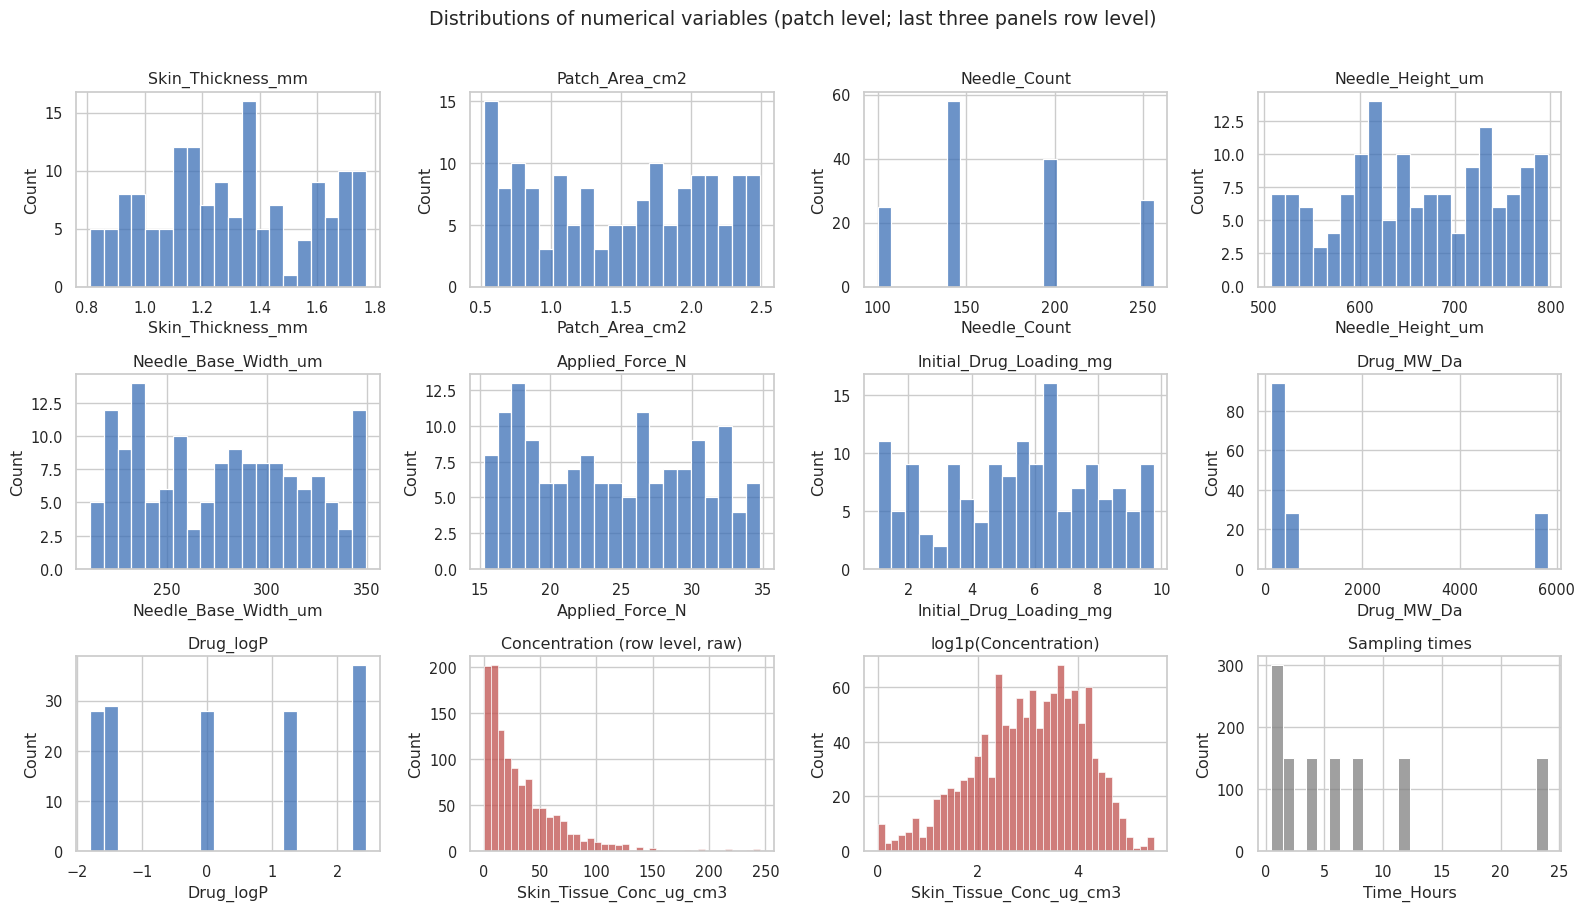

In [6]:
num_cols = ['Skin_Thickness_mm', 'Patch_Area_cm2', 'Needle_Count', 'Needle_Height_um', 'Needle_Base_Width_um',
            'Applied_Force_N', 'Initial_Drug_Loading_mg', 'Drug_MW_Da', 'Drug_logP']
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(patch[c], bins=20, ax=ax, color='#3b6fb6'); ax.set_title(c)
sns.histplot(raw[TARGET], bins=40, ax=axes.ravel()[9], color='#c0504d'); axes.ravel()[9].set_title('Concentration (row level, raw)')
sns.histplot(np.log1p(raw[TARGET]), bins=40, ax=axes.ravel()[10], color='#c0504d'); axes.ravel()[10].set_title('log1p(Concentration)')
sns.histplot(raw.Time_Hours, bins=24, ax=axes.ravel()[11], color='grey'); axes.ravel()[11].set_title('Sampling times')
plt.suptitle('Distributions of numerical variables (patch level; last three panels row level)', y=1.01); plt.tight_layout(); savefig('eda_numeric_distributions'); plt.show()

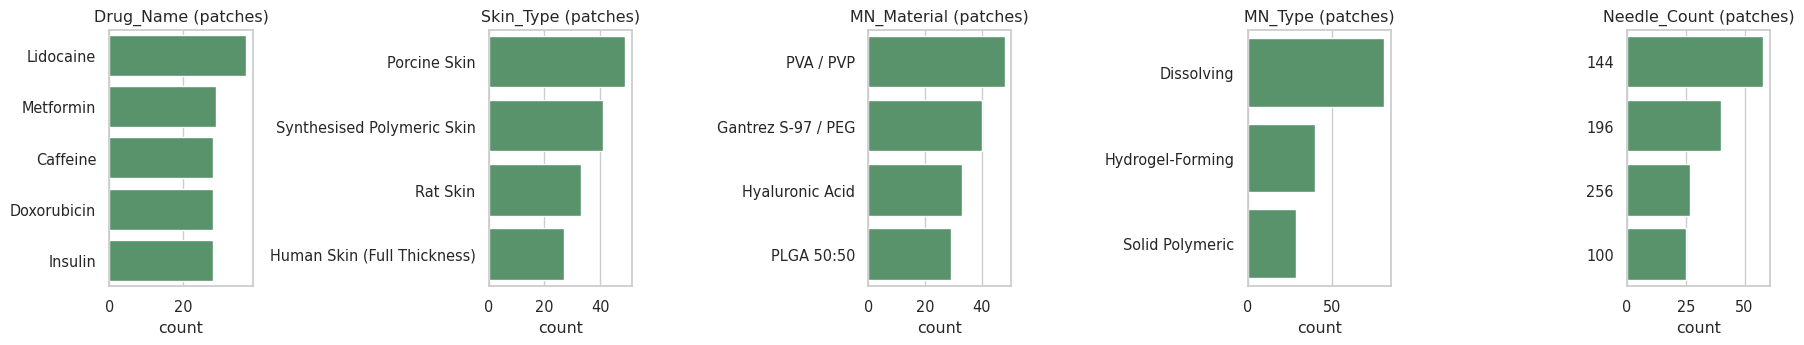

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, c in zip(axes, ['Drug_Name', 'Skin_Type', 'MN_Material', 'MN_Type', 'Needle_Count']):
    order = patch[c].value_counts().index
    sns.countplot(y=patch[c].astype(str), order=order.astype(str), ax=ax, color='#4f9d69'); ax.set_title(c + ' (patches)'); ax.set_ylabel('')
plt.tight_layout(); savefig('eda_categorical_counts'); plt.show()

Strongest |rho| with Cmax_obs:

,AUC_obs,Initial_Drug_Loading_mg,Patch_Area_cm2,Skin_Thickness_mm,Applied_Force_N,Drug_logP,Drug_MW_Da,Tmax_obs,Needle_Count,Needle_Height_um,Needle_Base_Width_um
abs rho,0.931,0.805,0.284,0.15,0.135,0.129,0.09,0.039,0.031,0.024,0.022


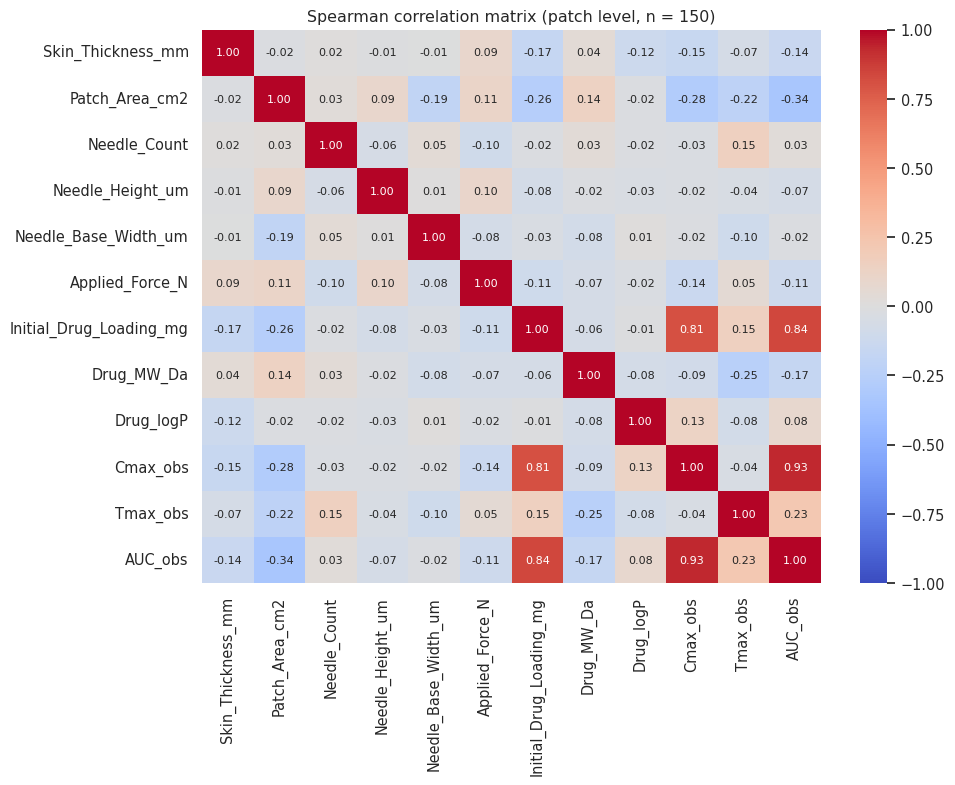

In [8]:
# Correlations (Spearman, patch level) incl. curve summaries
corr_cols = num_cols + ['Cmax_obs', 'Tmax_obs', 'AUC_obs']
corr = patch[corr_cols].corr(method='spearman')
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Spearman correlation matrix (patch level, n = 150)'); plt.tight_layout(); savefig('eda_correlation'); plt.show()
print('Strongest |rho| with Cmax_obs:'); display(corr['Cmax_obs'].drop('Cmax_obs').abs().sort_values(ascending=False).round(3).to_frame('abs rho').T)

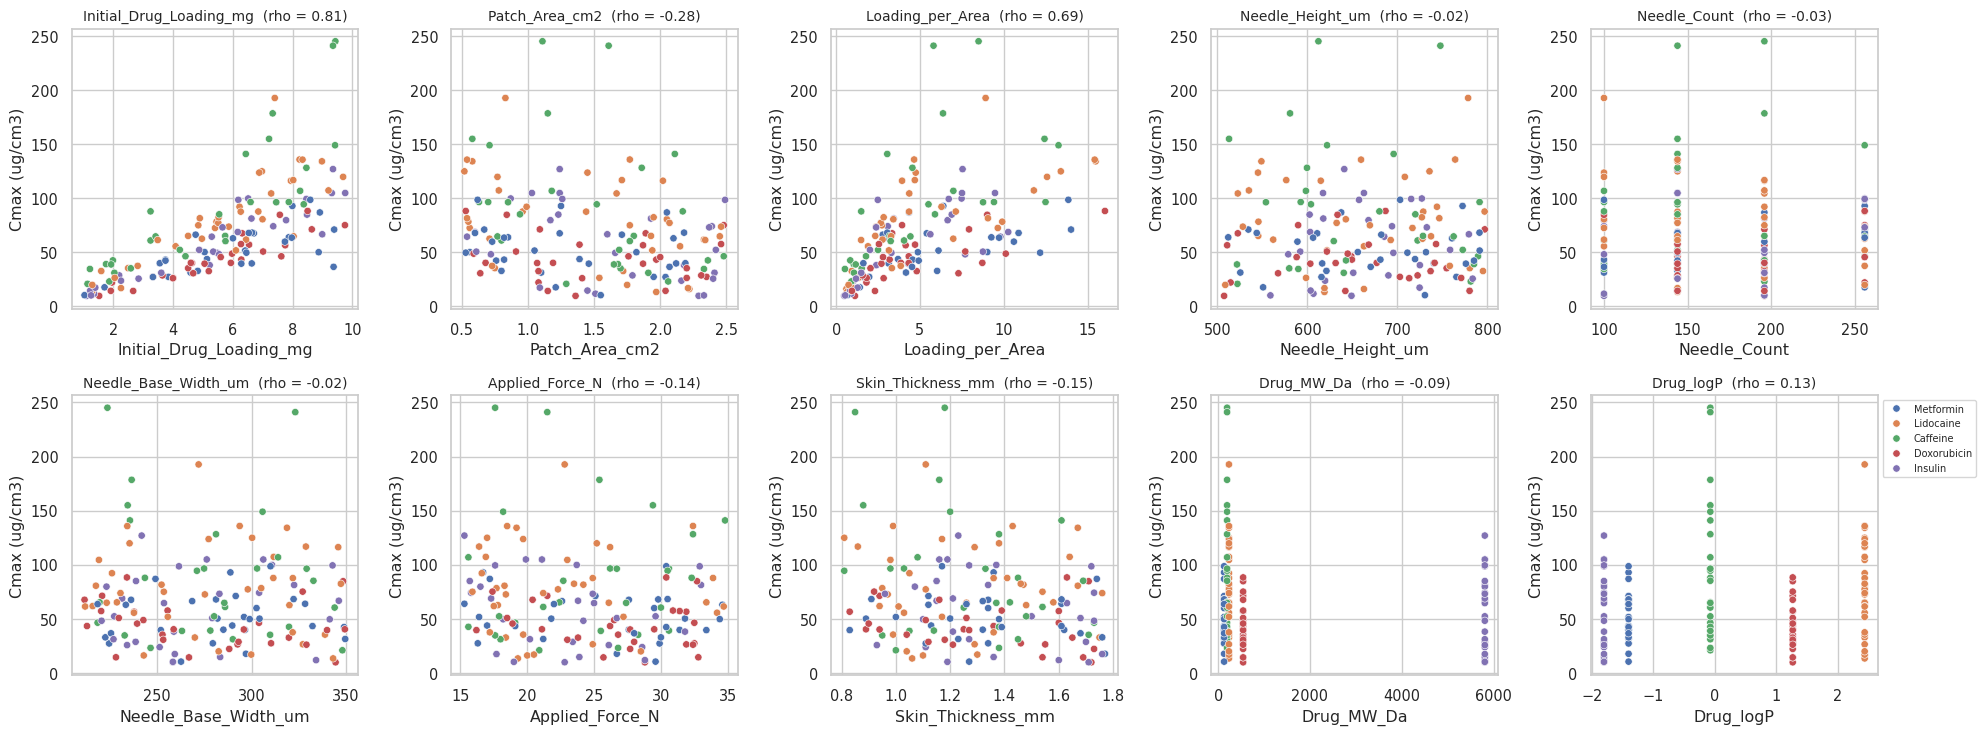

In [9]:
# Relationship of each design parameter with Cmax (patch level)
patch['Loading_per_Area'] = patch.Initial_Drug_Loading_mg / patch.Patch_Area_cm2
xs = ['Initial_Drug_Loading_mg', 'Patch_Area_cm2', 'Loading_per_Area', 'Needle_Height_um', 'Needle_Count',
      'Needle_Base_Width_um', 'Applied_Force_N', 'Skin_Thickness_mm', 'Drug_MW_Da', 'Drug_logP']
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, c in zip(axes.ravel(), xs):
    sns.scatterplot(data=patch, x=c, y='Cmax_obs', hue='Drug_Name', ax=ax, s=28, legend=(c == xs[-1]))
    rho = stats.spearmanr(patch[c], patch.Cmax_obs)[0]
    ax.set_title(f'{c}  (rho = {rho:.2f})', fontsize=10); ax.set_ylabel('Cmax (ug/cm3)')
axes.ravel()[-1].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); savefig('eda_cmax_vs_features'); plt.show()

**[OBSERVED]** Initial drug loading is by far the strongest univariate correlate of Cmax; patch area correlates negatively (larger patch → lower concentration at equal loading). Needle height, count, base width and applied force show almost no marginal relationship with Cmax. **[ASSUMPTION]** The weak marginal effect of geometry does not prove geometry is physically irrelevant: it may act through interactions, or the dataset may simply not vary it enough. The MW and logP panels show vertical stripes (5 drugs only) – see finding 1 in Section 3.

Kruskal-Wallis tests on patch-level values (p-values; small n, interpret cautiously):

metric,AUC_obs,Cmax_obs,Cmax_per_mg,Tmax_obs
grouping,,,,
Drug_Name,0.0919,0.0004,0.0000,0.0000
MN_Material,0.0002,0.0042,0.0053,0.0283
Skin_Type,0.9645,0.8361,0.6511,0.2457


,Cmax_obs,Cmax_per_mg,Tmax_obs,AUC_obs,Skin_Thickness_mm
Skin_Type,,,,,
Human Skin (Full Thickness),51.59,10.24,6.0,686.76,1.23
Porcine Skin,60.34,11.31,4.0,643.85,1.34
Rat Skin,66.65,12.37,4.0,649.71,1.43
Synthesised Polymeric Skin,59.84,11.74,4.0,713.80,1.19


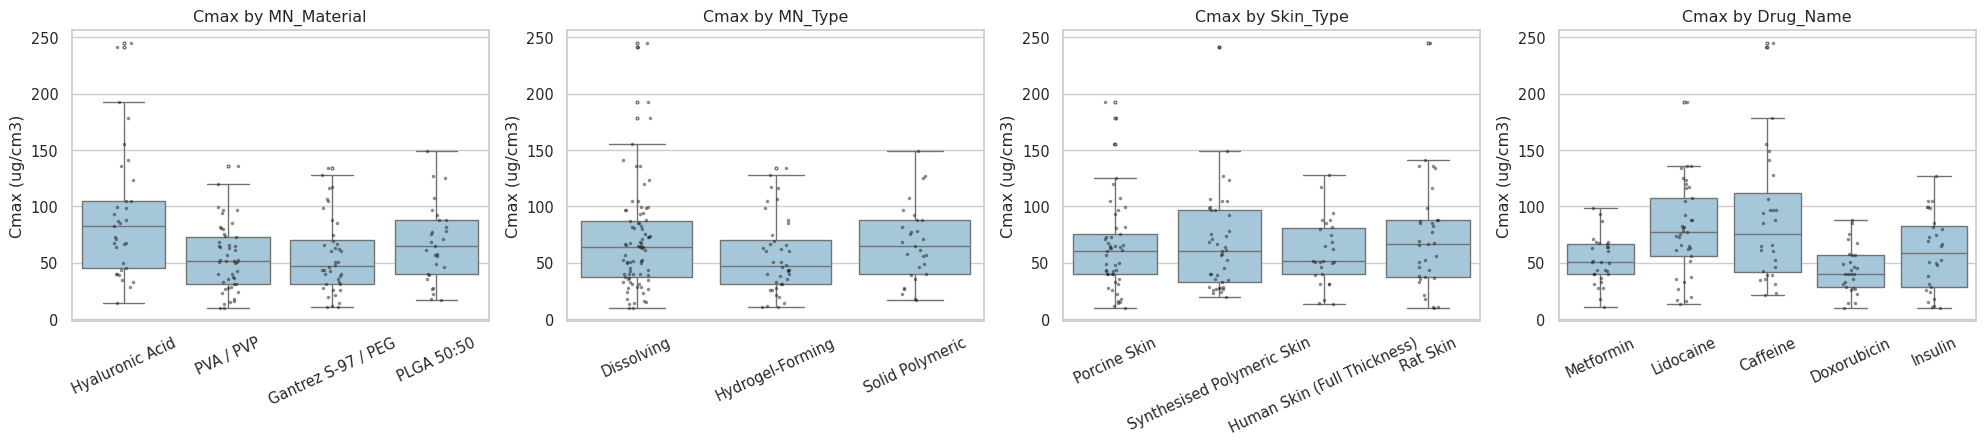

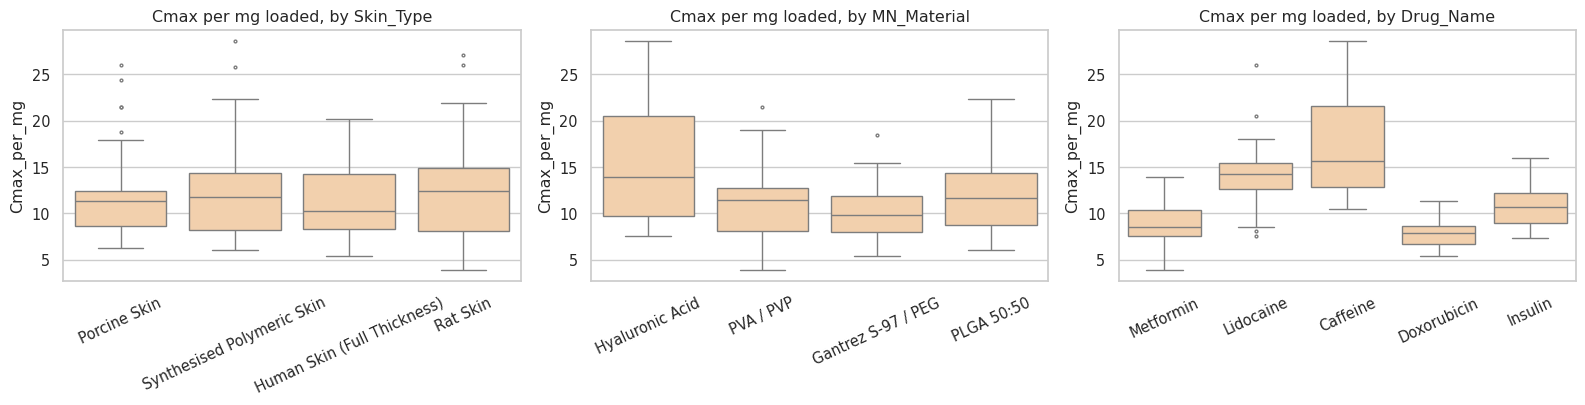

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, c in zip(axes, ['MN_Material', 'MN_Type', 'Skin_Type', 'Drug_Name']):
    sns.boxplot(data=patch, x=c, y='Cmax_obs', ax=ax, color='#9ecae1', fliersize=2); sns.stripplot(data=patch, x=c, y='Cmax_obs', ax=ax, color='k', size=2.5, alpha=.5)
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25); ax.set_title(f'Cmax by {c}'); ax.set_ylabel('Cmax (ug/cm3)')
plt.tight_layout(); savefig('eda_cmax_by_category'); plt.show()

patch['Cmax_per_mg'] = patch.Cmax_obs / patch.Initial_Drug_Loading_mg
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ['Skin_Type', 'MN_Material', 'Drug_Name']):
    sns.boxplot(data=patch, x=c, y='Cmax_per_mg', ax=ax, color='#fdd0a2', fliersize=2); ax.tick_params(axis='x', rotation=25)
    ax.set_title(f'Cmax per mg loaded, by {c}'); ax.set_xlabel('')
plt.tight_layout(); savefig('eda_cmax_per_mg'); plt.show()

print('Kruskal-Wallis tests on patch-level values (p-values; small n, interpret cautiously):')
rows = []
for var in ['Skin_Type', 'MN_Material', 'Drug_Name']:
    for m in ['Cmax_obs', 'Cmax_per_mg', 'Tmax_obs', 'AUC_obs']:
        groups = [g[m].values for _, g in patch.groupby(var)]
        rows.append({'grouping': var, 'metric': m, 'p_value': stats.kruskal(*groups).pvalue})
display(pd.DataFrame(rows).pivot(index='grouping', columns='metric', values='p_value').round(4))
display(patch.groupby('Skin_Type')[['Cmax_obs', 'Cmax_per_mg', 'Tmax_obs', 'AUC_obs', 'Skin_Thickness_mm']].median().round(2))

**[OBSERVED]** The skin types overlap strongly in Cmax, Tmax and AUC; the table above lists the test p-values. Drug and material differ more clearly. **[ASSUMPTION]** Because only 27–49 patches per skin type exist and drug/material/loading are not balanced across skin types, these marginal tests cannot say whether human skin truly behaves like the other skins – this is tested through modelling in Section 13.

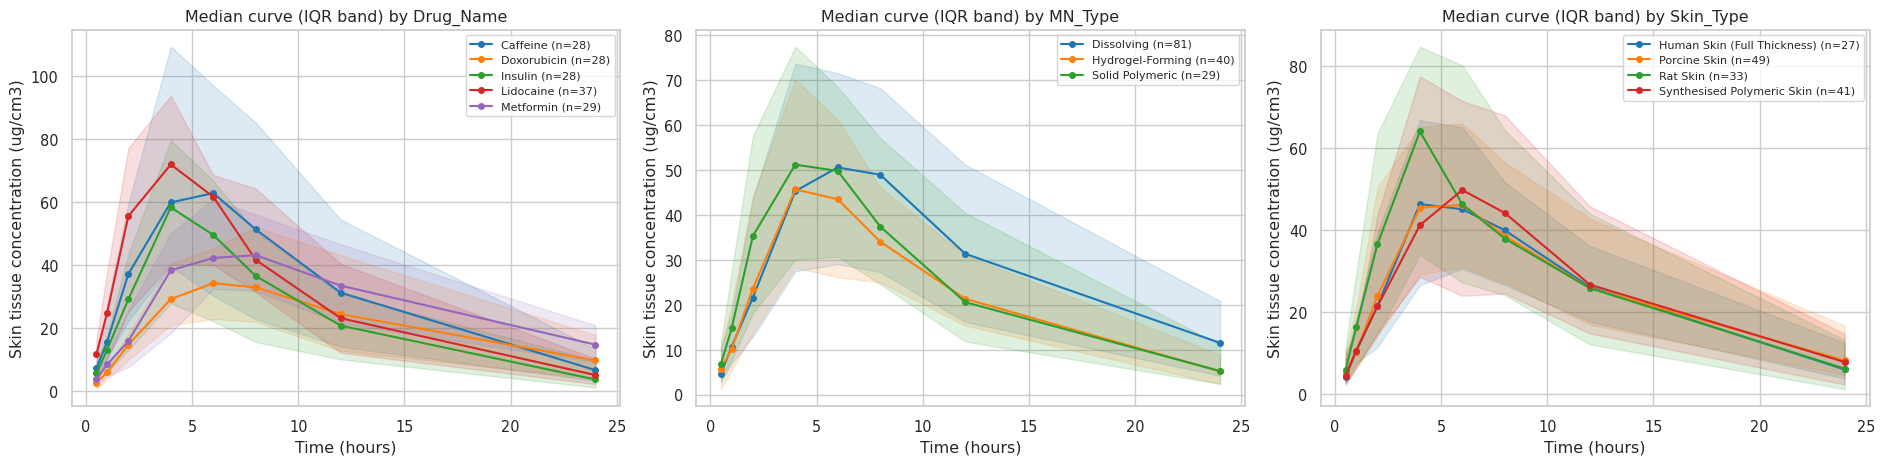

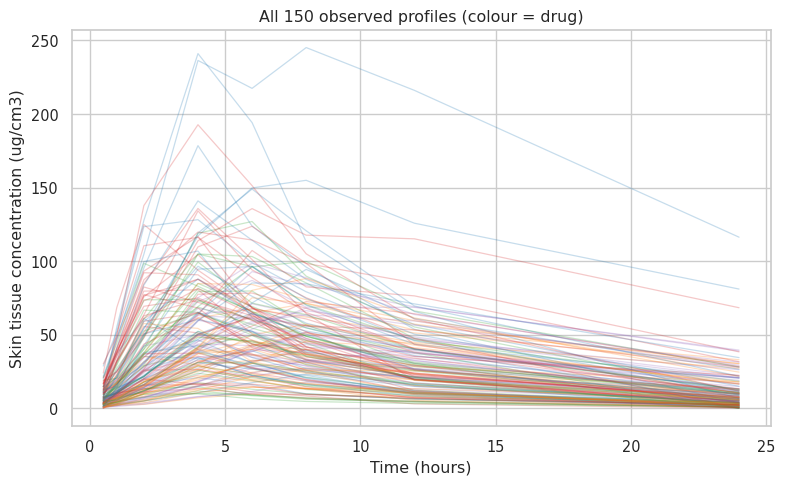

In [11]:
# Concentration-time curves: median and inter-quartile band per group
def curves_by(ax, col, palette):
    for lvl, col_ in zip(sorted(patch[col].unique()), palette):
        ids = patch.index[patch[col] == lvl]
        M = Y_wide.loc[ids]
        ax.plot(TIMES, M.median(), '-o', color=col_, label=f'{lvl} (n={len(ids)})', ms=4)
        ax.fill_between(TIMES, M.quantile(.25), M.quantile(.75), color=col_, alpha=.15)
    ax.set_xlabel('Time (hours)'); ax.set_ylabel('Skin tissue concentration (ug/cm3)'); ax.set_title(f'Median curve (IQR band) by {col}'); ax.legend(fontsize=8)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
pal = sns.color_palette('tab10')
curves_by(axes[0], 'Drug_Name', pal); curves_by(axes[1], 'MN_Type', pal); curves_by(axes[2], 'Skin_Type', pal)
plt.tight_layout(); savefig('eda_curves_by_group'); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for pid, row in Y_wide.iterrows():
    ax.plot(TIMES, row.values, color=pal[sorted(patch.Drug_Name.unique()).index(patch.loc[pid, 'Drug_Name'])], alpha=.25, lw=.9)
ax.set_xlabel('Time (hours)'); ax.set_ylabel('Skin tissue concentration (ug/cm3)'); ax.set_title('All 150 observed profiles (colour = drug)')
plt.tight_layout(); savefig('eda_all_curves'); plt.show()

Observed Tmax (h, among the 8 sampled times) by drug (patch counts):
MN_Type   Dissolving  Hydrogel-Forming  Solid Polymeric
Tmax_obs                                               
2.0                2                 3                7
4.0               40                25               10
6.0               17                10                9
8.0               21                 2                3
12.0               1                 0                0

Skin_Type  Human Skin (Full Thickness)  Porcine Skin  Rat Skin  Synthesised Polymeric Skin
Tmax_obs                                                                                  
2.0                                  0             2         6                           4
4.0                                 13            29        15                          18
6.0                                  7            10         8                          11
8.0                                  7             7         4                     

Drug_Name,Caffeine,Doxorubicin,Insulin,Lidocaine,Metformin
Tmax_obs,,,,,
2.0,2,2,2,6,0
4.0,16,7,22,23,7
6.0,6,10,3,6,11
8.0,4,9,1,2,10
12.0,0,0,0,0,1


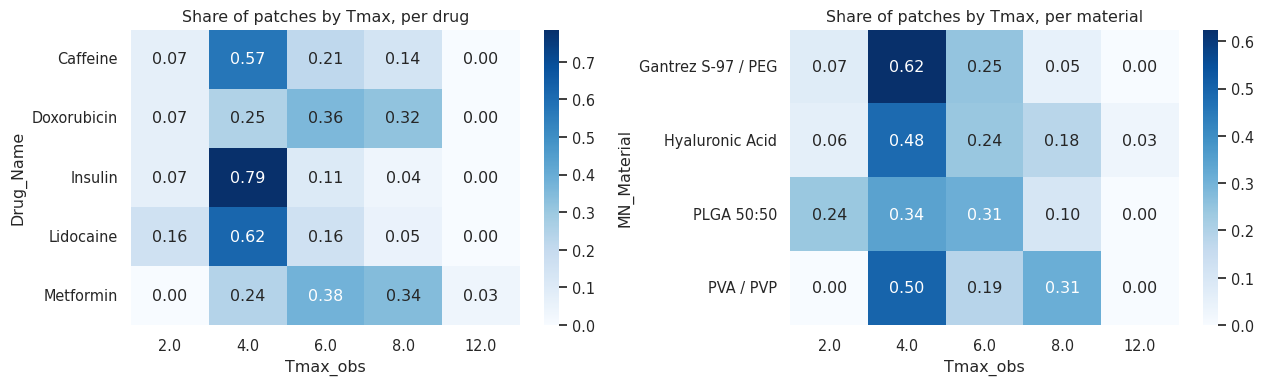

In [12]:
# Shape of the profiles: rise-then-fall? how variable is Tmax?
tm = pd.crosstab(patch.Tmax_obs, patch.Drug_Name); print('Observed Tmax (h, among the 8 sampled times) by drug (patch counts):'); display(tm)
print(pd.crosstab(patch.Tmax_obs, patch.MN_Type).to_string()); print()
print(pd.crosstab(patch.Tmax_obs, patch.Skin_Type).to_string())
print('\nPatches whose maximum is at the first/last sampled time:', int((patch.Tmax_obs == 0.5).sum()), '/', int((patch.Tmax_obs == 24).sum()))
print('Median C(24h)/Cmax = %.2f ; fraction of patches with C(24h) < 0.5*Cmax: %.2f' % ((Y_wide[24] / patch.Cmax_obs).median(), ((Y_wide[24] / patch.Cmax_obs) < .5).mean()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(pd.crosstab(patch.Drug_Name, patch.Tmax_obs, normalize='index'), annot=True, fmt='.2f', cmap='Blues', ax=axes[0]); axes[0].set_title('Share of patches by Tmax, per drug')
sns.heatmap(pd.crosstab(patch.MN_Material, patch.Tmax_obs, normalize='index'), annot=True, fmt='.2f', cmap='Blues', ax=axes[1]); axes[1].set_title('Share of patches by Tmax, per material')
plt.tight_layout(); savefig('eda_tmax'); plt.show()

**[OBSERVED]** Concentration generally **rises, peaks at 2–12 h (usually 4–8 h) and then declines**; no patch peaks at the first or last sample, so the 0.5–24 h window captures the peak for every patch. Peak time **differs between formulations** (e.g. Metformin and Doxorubicin patches peak later than Insulin or Lidocaine patches). Note that Tmax is only resolved to the sampling grid and the curves are noisy near the plateau, so single-patch Tmax values are uncertain.

Row-level IQR outliers on log1p scale: 9 rows | patch-level Cmax outliers: 0 patches | patches with a zero: 7 | non-unimodal profiles: 0
Row-level outliers (log1p scale):
Patches with a zero value:

,Patch_ID,Drug_Name,Skin_Type,Time_Hours,Skin_Tissue_Conc_ug_cm3
96,PATCH-113,Doxorubicin,Synthesised Polymeric Skin,0.5,0.00
111,PATCH-114,Lidocaine,Porcine Skin,24.0,0.00
304,PATCH-139,Metformin,Human Skin (Full Thickness),0.5,0.00
335,PATCH-142,Insulin,Rat Skin,24.0,0.00
503,PATCH-163,Insulin,Rat Skin,24.0,0.00
720,PATCH-191,Doxorubicin,Synthesised Polymeric Skin,0.5,0.05
735,PATCH-192,Lidocaine,Rat Skin,24.0,0.00
847,PATCH-206,Insulin,Human Skin (Full Thickness),24.0,0.00
1184,PATCH-249,Metformin,Synthesised Polymeric Skin,0.5,0.07


,Patch_ID,Drug_Name,Skin_Type,Time_Hours,Skin_Tissue_Conc_ug_cm3
96,PATCH-113,Doxorubicin,Synthesised Polymeric Skin,0.5,0.0
111,PATCH-114,Lidocaine,Porcine Skin,24.0,0.0
304,PATCH-139,Metformin,Human Skin (Full Thickness),0.5,0.0
335,PATCH-142,Insulin,Rat Skin,24.0,0.0
503,PATCH-163,Insulin,Rat Skin,24.0,0.0
735,PATCH-192,Lidocaine,Rat Skin,24.0,0.0
847,PATCH-206,Insulin,Human Skin (Full Thickness),24.0,0.0


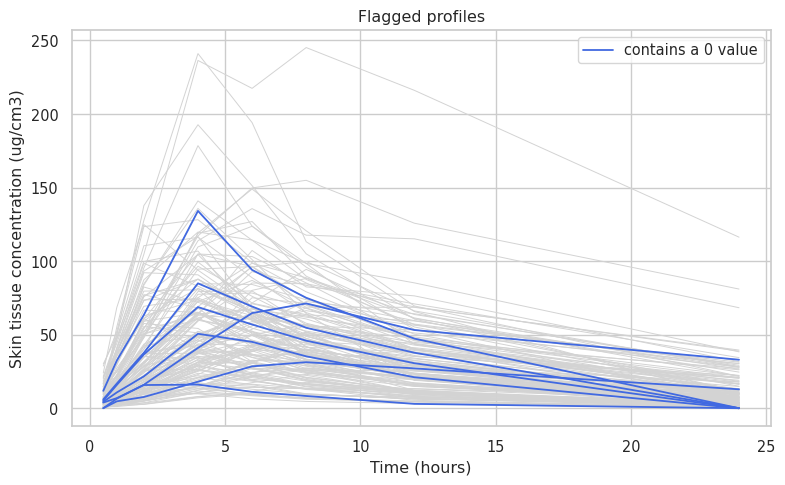

In [13]:
# --- unusual observations -----------------------------------------------------------------------
lc = np.log1p(raw[TARGET]); q1, q3 = lc.quantile([.25, .75]); iqr = q3 - q1
row_out = raw[(lc > q3 + 1.5 * iqr) | (lc < q1 - 1.5 * iqr)]
lcm = patch.logCmax; q1c, q3c = lcm.quantile([.25, .75]); out_cmax = patch[(lcm > q3c + 1.5 * (q3c - q1c)) | (lcm < q1c - 1.5 * (q3c - q1c))]
zero_p = Y_wide.index[(Y_wide == 0).any(axis=1)]
# 'rebound': a later sample exceeding an earlier post-peak sample by >25% (non-unimodal profile)
def has_rebound(v):
    k = int(np.argmax(v)); post = v[k:]
    return any(post[j] > 1.25 * post[:j].min() for j in range(1, len(post))) if len(post) > 2 else False
rebound = Y_wide.index[[has_rebound(r) for r in Y_wide.values]]
print(f'Row-level IQR outliers on log1p scale: {len(row_out)} rows | patch-level Cmax outliers: {len(out_cmax)} patches | patches with a zero: {len(zero_p)} | non-unimodal profiles: {len(rebound)}')
print('Row-level outliers (log1p scale):'); display(row_out[['Patch_ID', 'Drug_Name', 'Skin_Type', 'Time_Hours', TARGET]])
print('Patches with a zero value:'); display(raw[raw.Patch_ID.isin(zero_p) & (raw[TARGET] == 0)][['Patch_ID', 'Drug_Name', 'Skin_Type', 'Time_Hours', TARGET]])
fig, ax = plt.subplots(figsize=(8, 5))
for pid, row in Y_wide.iterrows(): ax.plot(TIMES, row.values, color='lightgrey', lw=.7)
for ids, col, lab in [(out_cmax.index, 'crimson', 'extreme Cmax'), (zero_p, 'royalblue', 'contains a 0 value'), (rebound, 'darkorange', 'non-unimodal')]:
    for k, pid in enumerate(ids): ax.plot(TIMES, Y_wide.loc[pid].values, color=col, lw=1.3, label=lab if k == 0 else None)
ax.set_xlabel('Time (hours)'); ax.set_ylabel('Skin tissue concentration (ug/cm3)'); ax.legend(); ax.set_title('Flagged profiles'); plt.tight_layout(); savefig('eda_flagged_profiles'); plt.show()

**[OBSERVED]** No patch is an outlier in Cmax on the log scale, and **no profile is non-unimodal** (every curve rises to a single peak and then declines). The 9 rows flagged on the log1p scale are exactly the near-zero values (the 7 exact zeros – 5 at 24 h, 2 at 0.5 h – plus values of 0.05 and 0.07), i.e. points at the tails of otherwise ordinary curves. **[ASSUMPTION]** The zeros look like values below a detection limit rather than genuine absence of drug.

**Decision:** no observation is deleted. Only 150 patches exist, the flagged rows sit on curves that are otherwise regular, and removing high concentrations would remove exactly the formulations of most interest. Robustness to the skewed target is handled with the `log1p` transform (tested in Section 9) and with tree-based models, which are insensitive to input outliers.

## 5. Pre-processing

* **Categorical variables** (`Skin_Type`, `MN_Material`) → one-hot encoding, `handle_unknown='ignore'`.
* **Numerical variables** → `StandardScaler` (needed for Ridge/Lasso, harmless for trees).
* **Time** → for linear models a cubic spline basis (so a linear model can represent a rise-and-fall curve); for tree models the raw value.
* **Not used as inputs:** `Patch_ID` (group label only). `MN_Type` (redundant with material) and `Drug_Name` (redundant with the numeric descriptors) are *candidate* inputs: the ablation in Section 9a measures whether adding them helps.
* All fitted transformations (scaler, encoder, spline) live **inside** scikit-learn `Pipeline`s, so they are re-fitted on the training patches of each fold only – no leakage from validation/test patches.

## 6. Feature engineering

Candidate derived features with a physical rationale (all are deterministic arithmetic on one row, so computing them before the pipeline cannot leak information):

| Feature | Rationale |
|---|---|
| `Loading_per_Area` | dose per unit patch area (mg/cm²) |
| `Needle_Density` | needles per cm² |
| `Loading_per_Needle` | dose carried by each needle |
| `Force_per_Needle` | insertion force per needle (insertion depth depends on force *per tip*) |
| `Aspect_Ratio` | height / base width – needle slenderness |
| `Needle_Volume_um3` | ≈ ⅓·base²·height (square pyramid) – drug reservoir volume per needle |
| `Penetration_Ratio` | needle height / skin thickness (skin ↔ geometry interaction) |
| `LogMW_x_Height` | drug size ↔ needle length interaction |
| `LogP_x_LoadingArea` | drug lipophilicity ↔ dose density interaction |

Whether they help is decided by a group-CV ablation in Section 9 – they are kept only if they improve generalisation.

In [14]:
FEATURE_SRC = '''
import numpy as np
def add_engineered_features(df):
    d = df.copy()
    d['Loading_per_Area'] = d['Initial_Drug_Loading_mg'] / d['Patch_Area_cm2']
    d['Needle_Density'] = d['Needle_Count'] / d['Patch_Area_cm2']
    d['Loading_per_Needle'] = d['Initial_Drug_Loading_mg'] / d['Needle_Count']
    d['Force_per_Needle'] = d['Applied_Force_N'] / d['Needle_Count']
    d['Aspect_Ratio'] = d['Needle_Height_um'] / d['Needle_Base_Width_um']
    d['Needle_Volume_um3'] = d['Needle_Base_Width_um'] ** 2 * d['Needle_Height_um'] / 3.0
    d['Penetration_Ratio'] = d['Needle_Height_um'] / (d['Skin_Thickness_mm'] * 1000.0)
    d['LogMW_x_Height'] = np.log(d['Drug_MW_Da']) * d['Needle_Height_um']
    d['LogP_x_LoadingArea'] = d['Drug_logP'] * d['Loading_per_Area']
    return d
'''
exec(FEATURE_SRC)

RAW_NUM = ['Skin_Thickness_mm', 'Patch_Area_cm2', 'Needle_Count', 'Needle_Height_um', 'Needle_Base_Width_um',
           'Applied_Force_N', 'Initial_Drug_Loading_mg', 'Drug_MW_Da', 'Drug_logP', 'Is_Large_Peptide']
ENG_RATIO = ['Loading_per_Area', 'Needle_Density', 'Loading_per_Needle', 'Force_per_Needle', 'Aspect_Ratio', 'Needle_Volume_um3', 'Penetration_Ratio']
ENG_INTER = ['LogMW_x_Height', 'LogP_x_LoadingArea']
CAT_FEATURES = ['Skin_Type', 'MN_Material']

# patch-level modelling table (150 rows): inputs only + Patch_ID index
P = add_engineered_features(patch[['Drug_Name', 'Skin_Type', 'MN_Material', 'MN_Type'] + RAW_NUM]).copy()
Y = Y_wide.values.copy()                                    # (150, 8) observed concentrations, aligned with P
IDS = P.index.values
print('Modelling table:', P.shape, '| targets:', Y.shape)

# redundancy of the engineered features with their parents (Spearman, patch level)
eng_all = ENG_RATIO + ENG_INTER
rho_tab = pd.DataFrame({'rho_with_logCmax': [stats.spearmanr(P[c], patch.logCmax)[0] for c in eng_all + ['Initial_Drug_Loading_mg', 'Patch_Area_cm2']]},
                       index=eng_all + ['Initial_Drug_Loading_mg', 'Patch_Area_cm2']).round(3)
display(rho_tab.T)
cm = P[RAW_NUM + eng_all].corr(method='spearman').abs(); cm = cm.mask(np.eye(len(cm), dtype=bool), 0.0)
pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print('Feature pairs with |Spearman| > 0.9 (redundant information):'); display(pairs[pairs > .9].round(3).to_frame('|rho|'))

Modelling table: (150, 23) | targets: (150, 8)
Feature pairs with |Spearman| > 0.9 (redundant information):

,Loading_per_Area,Needle_Density,Loading_per_Needle,Force_per_Needle,Aspect_Ratio,Needle_Volume_um3,Penetration_Ratio,LogMW_x_Height,LogP_x_LoadingArea,Initial_Drug_Loading_mg,Patch_Area_cm2
rho_with_logCmax,0.688,0.25,0.701,-0.064,-0.012,-0.023,0.114,-0.107,0.093,0.805,-0.284


,,|rho|
Needle_Base_Width_um,Needle_Volume_um3,0.916


## 7. Group-aware train / test splitting

* **Final test set:** 30 patches (20 %), chosen with `StratifiedGroupKFold` (a `GroupKFold` variant that additionally balances `Skin_Type`) with `Patch_ID` as the group. All 8 rows of a patch go to the same side. These patches are **not touched** until the final evaluation (Section 11/12).
* **Development set:** the remaining 120 patches, used for model comparison and tuning with repeated 5-fold group cross-validation (again grouped by `Patch_ID`, stratified on skin type).
* `Patch_ID` is used only as the grouping variable and is never a model input.

In [15]:
TIMES_ARR = np.array(TIMES, dtype=float)

def group_folds(ids, n_splits=5, seed=0):
    """Group-aware folds on the long (row-level) data: groups = Patch_ID, stratified by Skin_Type.
    Returns a list of (train_patch_ids, test_patch_ids)."""
    sub = raw[raw.Patch_ID.isin(ids)]
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    folds = []
    for tr, te in sgkf.split(sub, sub.Skin_Type, groups=sub.Patch_ID):
        tr_ids, te_ids = np.unique(sub.Patch_ID.values[tr]), np.unique(sub.Patch_ID.values[te])
        assert not (set(tr_ids) & set(te_ids)), 'leakage: a patch appears on both sides'
        folds.append((tr_ids, te_ids))
    return folds

_, TEST_IDS = group_folds(IDS, n_splits=5, seed=SEED)[0]
DEV_IDS = np.array([i for i in IDS if i not in set(TEST_IDS)])
assert not (set(DEV_IDS) & set(TEST_IDS)) and len(DEV_IDS) + len(TEST_IDS) == 150
print(f'Development patches: {len(DEV_IDS)} ({len(DEV_IDS)*8} rows) | test patches: {len(TEST_IDS)} ({len(TEST_IDS)*8} rows)')
split_tab = pd.DataFrame({'dev': P.loc[DEV_IDS].Skin_Type.value_counts(), 'test': P.loc[TEST_IDS].Skin_Type.value_counts()})
display(split_tab)
display(pd.DataFrame({'dev': P.loc[DEV_IDS].Drug_Name.value_counts(), 'test': P.loc[TEST_IDS].Drug_Name.value_counts()}))

Development patches: 120 (960 rows) | test patches: 30 (240 rows)

,dev,test
Skin_Type,,
Porcine Skin,39,10
Synthesised Polymeric Skin,33,8
Rat Skin,26,7
Human Skin (Full Thickness),22,5


,dev,test
Drug_Name,,
Caffeine,19,9
Doxorubicin,25,3
Insulin,22,6
Lidocaine,29,8
Metformin,25,4


### Pipeline / evaluation machinery

Two modelling strategies are implemented behind one interface, so they are trained and scored on exactly the same patches:

* **Strategy 1 (S1) – time-dependent regression:** one row per (patch, time); `Time_Hours` is an input feature; trained on 8 × n_patches rows.
* **Strategy 2 (S2) – multi-output regression:** one row per patch; the 8 concentrations are 8 simultaneous outputs.

Either can be trained on the raw or the `log1p`-transformed target (`TransformedTargetRegressor`; predictions are back-transformed and clipped at 0 because concentrations cannot be negative). Scores are always computed on the **original** µg/cm³ scale.

In [16]:
FEATURE_SETS = {
    'raw':                      (RAW_NUM, CAT_FEATURES),
    'raw+ratios':               (RAW_NUM + ENG_RATIO, CAT_FEATURES),
    'raw+ratios+interactions':  (RAW_NUM + ENG_RATIO + ENG_INTER, CAT_FEATURES),
    'raw+DrugName+MN_Type':     (RAW_NUM, CAT_FEATURES + ['Drug_Name', 'MN_Type']),
}
Ydf = pd.DataFrame(Y, index=P.index, columns=TIMES)
LINEAR = ('LinearRegression', 'Ridge', 'Lasso')
NEEDS_WRAP = ('GradientBoosting', 'HistGradientBoosting', 'XGBoost', 'CatBoost')   # not natively multi-output

def base_estimator(name):
    est = {
        'LinearRegression': lambda: LinearRegression(),
        'Ridge': lambda: Ridge(alpha=1.0),
        'Lasso': lambda: Lasso(alpha=0.01, max_iter=50000),
        'RandomForest': lambda: RandomForestRegressor(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        'ExtraTrees': lambda: ExtraTreesRegressor(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        'GradientBoosting': lambda: GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED),
        'HistGradientBoosting': lambda: HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=5, random_state=SEED),
    }
    if HAS_XGB:
        from xgboost import XGBRegressor
        est['XGBoost'] = lambda: XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1)
    if HAS_CAT:
        from catboost import CatBoostRegressor
        est['CatBoost'] = lambda: CatBoostRegressor(iterations=200, depth=4, learning_rate=0.05, random_seed=SEED, verbose=0, thread_count=1)
    return est[name]()

MODEL_NAMES = ['LinearRegression', 'Ridge', 'Lasso', 'RandomForest', 'ExtraTrees', 'GradientBoosting', 'HistGradientBoosting'] \
              + (['XGBoost'] if HAS_XGB else []) + (['CatBoost'] if HAS_CAT else [])

def make_preprocessor(num_cols, cat_cols, strategy, linear):
    tr = [('num', StandardScaler(), list(num_cols)),
          ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(cat_cols))]
    if strategy == 'S1':
        tr.append(('time', SplineTransformer(n_knots=5, degree=3, knots='quantile', extrapolation='constant'), ['Time_Hours'])
                  if linear else ('time', 'passthrough', ['Time_Hours']))
    return ColumnTransformer(tr)

def build_model(strategy, name, feature_set='raw', log_target=True, params=None):
    num, cat = FEATURE_SETS[feature_set]
    est = base_estimator(name)
    if params: est.set_params(**params)
    if strategy == 'S2' and name in NEEDS_WRAP: est = MultiOutputRegressor(est)
    pipe = Pipeline([('pre', make_preprocessor(num, cat, strategy, name in LINEAR)), ('model', est)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    return pipe

def long_frame(Xp):
    L = Xp.loc[Xp.index.repeat(8)].copy(); L['Time_Hours'] = np.tile(TIMES_ARR, len(Xp)); return L

def fit_model(strategy, model, ids):
    Xp = P.loc[ids]; Yt = Ydf.loc[ids].values
    return model.fit(long_frame(Xp), Yt.ravel()) if strategy == 'S1' else model.fit(Xp, Yt)

def predict_profiles(strategy, model, Xp):
    out = model.predict(long_frame(Xp)).reshape(len(Xp), 8) if strategy == 'S1' else model.predict(Xp)
    return np.clip(out, 0, None)

def cv_oof(spec, ids, seed, n_splits=5):
    oof = np.full((len(ids), 8), np.nan); pos = {p: k for k, p in enumerate(ids)}
    for tr, te in group_folds(ids, n_splits, seed):
        m = fit_model(spec['strategy'], build_model(spec['strategy'], spec['name'], spec.get('fs', 'raw'), spec.get('log', True), spec.get('params')), tr)
        oof[[pos[p] for p in te]] = predict_profiles(spec['strategy'], m, P.loc[te])
    return oof

# ---------- metrics -----------------------------------------------------------------------------
def curve_table(Yt, Yp, ids=None):
    """Per-patch curve descriptors. Cmax/Tmax are taken over the 8 sampled times; AUC = trapezoid over 0.5-24 h."""
    t = pd.DataFrame({'Cmax_obs': Yt.max(1), 'Cmax_pred': Yp.max(1),
                      'Tmax_obs': TIMES_ARR[Yt.argmax(1)], 'Tmax_pred': TIMES_ARR[Yp.argmax(1)],
                      'AUC_obs': trapezoid(Yt, TIMES_ARR, axis=1), 'AUC_pred': trapezoid(Yp, TIMES_ARR, axis=1),
                      'curve_RMSE': np.sqrt(((Yt - Yp) ** 2).mean(1)),
                      'curve_MAE': np.abs(Yt - Yp).mean(1)})
    t['Cmax_err_%'] = 100 * (t.Cmax_pred - t.Cmax_obs) / t.Cmax_obs
    t['AUC_err_%'] = 100 * (t.AUC_pred - t.AUC_obs) / t.AUC_obs
    t['Tmax_err_h'] = t.Tmax_pred - t.Tmax_obs
    t['Tmax_step_diff'] = Yp.argmax(1) - Yt.argmax(1)
    if ids is not None: t.index = ids
    return t

def evaluate(Yt, Yp):
    yt, yp = Yt.ravel(), Yp.ravel(); ct = curve_table(Yt, Yp)
    return {'R2': r2_score(yt, yp), 'MAE': mean_absolute_error(yt, yp), 'RMSE': mean_squared_error(yt, yp) ** .5,
            'R2_log1p': r2_score(np.log1p(yt), np.log1p(yp)),
            'Cmax_MAE': ct['Cmax_pred'].sub(ct['Cmax_obs']).abs().mean(), 'Cmax_medAPE_%': ct['Cmax_err_%'].abs().median(),
            'Tmax_MAE_h': ct['Tmax_err_h'].abs().mean(), 'Tmax_within1step_%': 100 * (ct['Tmax_step_diff'].abs() <= 1).mean(),
            'AUC_medAPE_%': ct['AUC_err_%'].abs().median(), 'AUC_R2': r2_score(ct.AUC_obs, ct.AUC_pred)}

def cv_eval(spec, ids, seeds=(0, 1, 2)):
    """Repeated group-CV. Returns (metrics per repeat as DataFrame, list of out-of-fold prediction matrices)."""
    Yt = Ydf.loc[ids].values; oofs = [cv_oof(spec, ids, s) for s in seeds]
    return pd.DataFrame([evaluate(Yt, o) for o in oofs]), oofs

SEEDS = (0, 1, 2)

# Small disk cache for the slow cross-validation runs (so an interrupted run resumes where it stopped).
# Delete the folder mn_outputs/cache to force full recomputation.
CACHE = OUT / 'cache'; CACHE.mkdir(exist_ok=True)
def cached(name, fn):
    path = CACHE / (name.replace('/', '_').replace(' ', '_') + '.joblib')
    if path.exists(): return joblib.load(path)
    result = fn(); joblib.dump(result, path); return result
print('machinery ready; models:', MODEL_NAMES)

machinery ready; models: ['LinearRegression', 'Ridge', 'Lasso', 'RandomForest', 'ExtraTrees', 'GradientBoosting', 'HistGradientBoosting']

### Why group-aware splitting matters – a demonstration

Same model, same development data, two validation schemes. Random row-wise K-fold lets rows of the *same patch* sit on both sides of the split, so the model can "recognise" a patch from its other 7 rows.

ExtraTrees (S1, log1p target) – row-wise random KFold R2 = 0.748   vs   patch-grouped CV R2 = 0.576

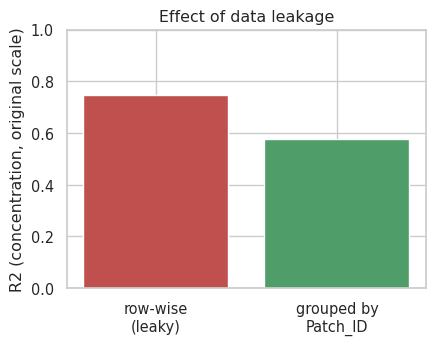

In [17]:
Xl = long_frame(P.loc[DEV_IDS]); yl = Ydf.loc[DEV_IDS].values.ravel()
def row_wise_r2(strategy_name='ExtraTrees'):
    pred = np.zeros_like(yl)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(Xl):
        m = build_model('S1', strategy_name, 'raw', True).fit(Xl.iloc[tr], yl[tr]); pred[te] = np.clip(m.predict(Xl.iloc[te]), 0, None)
    return r2_score(yl, pred)
r2_row = row_wise_r2()
m_grp, _ = cv_eval({'strategy': 'S1', 'name': 'ExtraTrees', 'fs': 'raw', 'log': True}, DEV_IDS, seeds=(0,))
print(f'ExtraTrees (S1, log1p target) – row-wise random KFold R2 = {r2_row:.3f}   vs   patch-grouped CV R2 = {m_grp.R2.iloc[0]:.3f}')
fig, ax = plt.subplots(figsize=(4.5, 3.6)); ax.bar(['row-wise\n(leaky)', 'grouped by\nPatch_ID'], [r2_row, m_grp.R2.iloc[0]], color=['#c0504d', '#4f9d69'])
ax.set_ylabel('R2 (concentration, original scale)'); ax.set_ylim(0, 1); ax.set_title('Effect of data leakage'); plt.tight_layout(); savefig('leakage_demo'); plt.show()

**[MODEL]** The row-wise score is far higher than the grouped score. The gap is pure leakage: it measures how well the model interpolates between rows of patches it has already seen, not how well it predicts a *new* patch. **Only grouped scores are reported from here on.**

## 8. Baseline models

Linear regression is the reference for every other model. For Strategy 1 it gets a cubic spline basis of time (otherwise a straight line in time could not represent a rise-and-fall curve); features are the raw inputs plus skin type and material.

In [18]:
t0 = time.time(); base_rows = []
for strat in ['S1', 'S2']:
    for log in [False, True]:
        m, _ = cv_eval({'strategy': strat, 'name': 'LinearRegression', 'fs': 'raw', 'log': log}, DEV_IDS, SEEDS)
        base_rows.append({'strategy': strat, 'model': 'LinearRegression', 'log1p_target': log, **m.mean().round(3).to_dict()})
baseline_tab = pd.DataFrame(base_rows)
print(f'Baseline (development set, repeated 5-fold group CV x {len(SEEDS)}); {time.time()-t0:.0f}s'); baseline_tab[['strategy', 'model', 'log1p_target', 'R2', 'MAE', 'RMSE', 'R2_log1p', 'Cmax_MAE', 'Tmax_MAE_h', 'AUC_medAPE_%']]

Baseline (development set, repeated 5-fold group CV x 3); 1s

,strategy,model,log1p_target,R2,MAE,RMSE,R2_log1p,Cmax_MAE,Tmax_MAE_h,AUC_medAPE_%
0,S1,LinearRegression,False,0.565,13.806,20.828,0.350,18.280,1.667,22.638
1,S1,LinearRegression,True,0.639,11.844,18.966,0.707,18.375,1.772,23.771
2,S2,LinearRegression,False,0.642,11.809,18.892,0.535,16.414,1.499,24.554
3,S2,LinearRegression,True,0.664,10.983,18.285,0.762,17.380,1.250,20.818


## 9. Model comparison

### 9a. Which feature set? (group-CV ablation)
Fast models (Ridge, ExtraTrees; plus GradientBoosting for S2) × both strategies, `log1p` target. A richer feature set is adopted **only if it lowers the cross-validated RMSE by at least 2 %** relative to the raw inputs; otherwise the simpler set is kept (parsimony on a 150-patch dataset).

In [19]:
ABL_SETS = ['raw', 'raw+ratios', 'raw+ratios+interactions', 'raw+DrugName+MN_Type']
def _abl_one(fs, strat, name):
    m, _ = cv_eval({'strategy': strat, 'name': name, 'fs': fs, 'log': True}, DEV_IDS, SEEDS)
    return {'feature_set': fs, 'strategy': strat, 'model': name, 'RMSE': m.RMSE.mean(), 'R2': m.R2.mean()}
t0 = time.time(); abl = []
for fs in ABL_SETS:
    for strat in ['S1', 'S2']:
        for name in (['Ridge', 'ExtraTrees'] if strat == 'S1' else ['Ridge', 'ExtraTrees', 'GradientBoosting']):
            abl.append(cached(f'abl_{fs}_{strat}_{name}', lambda: _abl_one(fs, strat, name)))
abl = pd.DataFrame(abl)
abl_piv = abl.pivot_table(index=['strategy', 'model'], columns='feature_set', values='RMSE')[ABL_SETS]
display(abl_piv.round(2))
mean_rmse = abl.groupby('feature_set').RMSE.mean()
rel = (mean_rmse / mean_rmse['raw'] - 1) * 100
display(pd.DataFrame({'mean RMSE': mean_rmse, 'change vs raw (%)': rel}).round(2))
cand = rel[rel <= -2.0]
FEATURE_SET = cand.idxmin() if len(cand) else 'raw'
print(f'-> selected feature set: {FEATURE_SET}   ({time.time()-t0:.0f}s)')

-> selected feature set: raw+DrugName+MN_Type   (71s)

feature_set                  raw  ...  raw+DrugName+MN_Type
strategy model                    ...                      
S1       ExtraTrees        20.75  ...                 18.53
         Ridge             19.25  ...                 16.98
S2       ExtraTrees        20.76  ...                 18.81
         GradientBoosting  19.67  ...                 18.80
         Ridge             19.29  ...                 15.91

[5 rows x 4 columns]

,mean RMSE,change vs raw (%)
feature_set,,
raw,19.94,0.00
raw+DrugName+MN_Type,17.81,-10.71
raw+ratios,20.48,2.69
raw+ratios+interactions,20.29,1.75


**Reading the table.** Column *`raw+DrugName+MN_Type`* adds the one-hot drug name and microneedle type to the raw inputs. They carry no *new* information (the three numeric drug descriptors already identify the drug), yet they can still help a model because five drugs placed on three numeric axes (MW, logP, peptide flag) form an irregular pattern that a linear model cannot represent, and that trees can only isolate with several splits on a 120-patch sample; a one-hot drug indicator gives each drug its own offset directly. The engineered ratios and interactions are judged by the 2 % rule; the selected set is printed above. **[ASSUMPTION]** A feature set that is not clearly better is not proven useless – it is simply not supported by this dataset size.

**Consequence for later sections:** the selected model knows the five drugs by name, so it can predict only for drugs seen in training (Section 13 quantifies how badly it does on an unseen drug).

### 9b. All candidate models, both strategies, raw vs log1p target
Default (untuned) hyper-parameters, 5-fold group CV repeated with 3 different fold assignments on the 120 development patches.

In [20]:
def _cmp_one(strat, name, log):
    m, _ = cv_eval({'strategy': strat, 'name': name, 'fs': FEATURE_SET, 'log': log}, DEV_IDS, SEEDS)
    return {'strategy': strat, 'model': name, 'log1p_target': log, **m.mean().to_dict(), 'R2_sd_over_repeats': m.R2.std()}
t0 = time.time(); cmp_rows = []
for strat in ['S1', 'S2']:
    for name in MODEL_NAMES:
        for log in [False, True]:
            cmp_rows.append(cached(f'cmp_{FEATURE_SET}_{strat}_{name}_{log}', lambda: _cmp_one(strat, name, log)))
    print(strat, 'done', f'{time.time()-t0:.0f}s', flush=True)
cmp_tab = pd.DataFrame(cmp_rows).sort_values('RMSE').reset_index(drop=True)
show_cols = ['strategy', 'model', 'log1p_target', 'R2', 'MAE', 'RMSE', 'R2_log1p', 'Cmax_MAE', 'Cmax_medAPE_%', 'Tmax_MAE_h', 'Tmax_within1step_%', 'AUC_medAPE_%', 'AUC_R2']
cmp_tab[show_cols].round(3)

S1 done 35s
S2 done 74s

,strategy,model,log1p_target,R2,MAE,RMSE,R2_log1p,Cmax_MAE,Cmax_medAPE_%,Tmax_MAE_h,Tmax_within1step_%,AUC_medAPE_%,AUC_R2
0,S2,Ridge,True,0.746,10.007,15.908,0.786,14.566,21.720,1.161,90.833,20.948,0.659
1,S2,LinearRegression,True,0.744,10.059,15.967,0.785,14.556,22.676,1.156,90.833,20.924,0.660
2,S2,Lasso,True,0.742,9.936,16.043,0.789,14.485,20.328,1.144,91.389,20.497,0.649
3,S1,LinearRegression,True,0.711,11.007,16.952,0.724,16.202,25.271,1.772,85.556,23.214,0.662
4,S1,Ridge,True,0.710,11.000,16.984,0.720,15.651,23.931,1.433,81.667,23.304,0.660
5,S2,Ridge,False,0.693,11.264,17.496,0.517,14.754,18.697,1.399,89.722,25.312,0.573
6,S2,Lasso,False,0.691,11.371,17.544,0.482,14.903,19.166,1.426,88.889,25.703,0.570
7,S2,LinearRegression,False,0.691,11.390,17.553,0.477,14.917,19.206,1.438,88.889,25.772,0.569
8,S1,Lasso,True,0.679,11.192,17.890,0.701,16.190,23.690,1.433,81.667,21.746,0.606
9,S2,HistGradientBoosting,True,0.656,10.689,18.504,0.769,16.489,23.120,1.217,91.944,16.822,0.571


Best RMSE by strategy and target transform:
Mean RMSE over all models: 

log1p_target,False,True
strategy,,
S1,18.55,16.95
S2,17.50,15.91


log1p_target,False,True
strategy,,
S1,20.08,18.58
S2,18.94,17.79


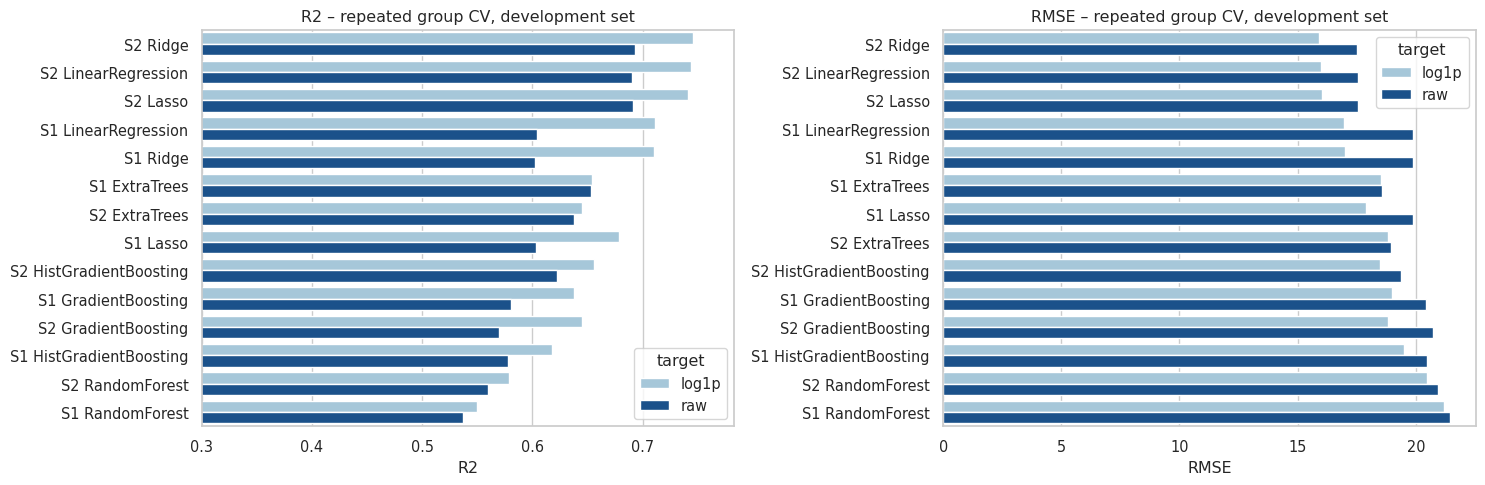

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tmp = cmp_tab.assign(target=np.where(cmp_tab.log1p_target, 'log1p', 'raw'), label=cmp_tab.strategy + ' ' + cmp_tab.model)
for ax, metric in zip(axes, ['R2', 'RMSE']):
    sns.barplot(data=tmp, y='label', x=metric, hue='target', ax=ax, palette=['#9ecae1', '#08519c'], order=tmp.groupby('label')[metric].mean().sort_values(ascending=(metric == 'RMSE')).index)
    ax.set_title(f'{metric} – repeated group CV, development set'); ax.set_ylabel('')
axes[0].set_xlim(0.3, None)
plt.tight_layout(); savefig('model_comparison'); plt.show()
best_by = cmp_tab.groupby(['strategy', 'log1p_target']).RMSE.min().unstack()
print('Best RMSE by strategy and target transform:'); display(best_by.round(2))
print('Mean RMSE over all models: '); display(cmp_tab.groupby(['strategy', 'log1p_target']).RMSE.mean().unstack().round(2))

In [22]:
# choose log vs raw target per (strategy, model) by CV RMSE
LOG_CHOICE = {(r.strategy, r.model): bool(r.log1p_target) for r in cmp_tab.sort_values('RMSE').drop_duplicates(['strategy', 'model']).itertuples()}
print('Target transform chosen per model:', {f'{k[0]} {k[1]}': ('log1p' if v else 'raw') for k, v in LOG_CHOICE.items()})
print('log1p chosen for %d of %d (strategy, model) pairs' % (sum(LOG_CHOICE.values()), len(LOG_CHOICE)))

Target transform chosen per model: {'S2 Ridge': 'log1p', 'S2 LinearRegression': 'log1p', 'S2 Lasso': 'log1p', 'S1 LinearRegression': 'log1p', 'S1 Ridge': 'log1p', 'S1 Lasso': 'log1p', 'S2 HistGradientBoosting': 'log1p', 'S1 ExtraTrees': 'log1p', 'S2 GradientBoosting': 'log1p', 'S2 ExtraTrees': 'log1p', 'S1 GradientBoosting': 'log1p', 'S1 HistGradientBoosting': 'log1p', 'S2 RandomForest': 'log1p', 'S1 RandomForest': 'log1p'}
log1p chosen for 14 of 14 (strategy, model) pairs

## 10. Hyper-parameter tuning

Random search (`ParameterSampler`) for each (strategy, model) with the target transform chosen above. Every candidate is scored by **5-fold patch-grouped CV on the 120 development patches** (fold assignment seed 100, different from the seeds used for the comparison); the criterion is the pooled out-of-fold RMSE in µg/cm³. The best setting is then re-evaluated with the 3 standard repeats. The 30 test patches play no role here.

In [23]:
SPACES = {
    'Ridge': {'alpha': loguniform(1e-2, 1e3)},
    'Lasso': {'alpha': loguniform(1e-4, 3e-1)},
    'RandomForest': {'max_depth': [None, 4, 6, 8, 12], 'min_samples_leaf': [1, 2, 3, 5, 8], 'max_features': [0.3, 0.5, 0.7, 1.0]},
    'ExtraTrees': {'max_depth': [None, 4, 6, 8, 12], 'min_samples_leaf': [1, 2, 3, 5, 8], 'max_features': [0.3, 0.5, 0.7, 1.0]},
    'GradientBoosting': {'n_estimators': randint(80, 300), 'learning_rate': loguniform(0.01, 0.15), 'max_depth': [2, 3, 4],
                         'subsample': [0.6, 0.8, 1.0], 'min_samples_leaf': [1, 3, 5, 10], 'max_features': [0.5, 0.8, 1.0]},
    'HistGradientBoosting': {'max_iter': randint(60, 250), 'learning_rate': loguniform(0.02, 0.2), 'max_depth': [2, 3, 4],
                             'min_samples_leaf': [3, 5, 10, 20], 'l2_regularization': loguniform(1e-3, 10)},
}
if HAS_XGB: SPACES['XGBoost'] = {'n_estimators': randint(80, 300), 'learning_rate': loguniform(0.01, 0.15), 'max_depth': [2, 3, 4], 'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.5, 0.8, 1.0], 'reg_lambda': loguniform(0.1, 10)}
if HAS_CAT: SPACES['CatBoost'] = {'iterations': randint(100, 300), 'learning_rate': loguniform(0.02, 0.15), 'depth': [3, 4, 5], 'l2_leaf_reg': loguniform(1, 10)}
N_ITER = {'Ridge': 12, 'Lasso': 12}; DEFAULT_ITER = 10

def tune(strategy, name, log):
    folds = group_folds(DEV_IDS, 5, seed=100); pos = {p: k for k, p in enumerate(DEV_IDS)}; Yt = Ydf.loc[DEV_IDS].values
    results = []
    for params in ParameterSampler(SPACES[name], N_ITER.get(name, DEFAULT_ITER), random_state=SEED):
        oof = np.full((len(DEV_IDS), 8), np.nan)
        for tr, te in folds:
            m = fit_model(strategy, build_model(strategy, name, FEATURE_SET, log, params), tr)
            oof[[pos[p] for p in te]] = predict_profiles(strategy, m, P.loc[te])
        results.append((mean_squared_error(Yt.ravel(), oof.ravel()) ** .5, params))
    results.sort(key=lambda r: r[0]); return results[0][1], results[0][0]

def _tune_one(strat, name, log):
    best_params, search_rmse = tune(strat, name, log)
    spec = {'strategy': strat, 'name': name, 'fs': FEATURE_SET, 'log': log, 'params': best_params}
    m, _ = cv_eval(spec, DEV_IDS, SEEDS)
    row = {'strategy': strat, 'model': name, 'log1p': log, 'search_RMSE': search_rmse, **m.mean().to_dict(),
           'best_params': {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()}}
    return spec, row

t0 = time.time(); TUNED = {}; tuned_rows = []
for strat in ['S1', 'S2']:
    for name in MODEL_NAMES:
        if name == 'LinearRegression': continue          # no hyper-parameters
        spec, row = cached(f'tune_{FEATURE_SET}_{strat}_{name}', lambda: _tune_one(strat, name, LOG_CHOICE[(strat, name)]))
        TUNED[(strat, name)] = spec; tuned_rows.append(row)
        print(f'{strat} {name:22s} tuned  RMSE={row["RMSE"]:.2f}  R2={row["R2"]:.3f}   ({time.time()-t0:.0f}s)', flush=True)
for strat in ['S1', 'S2']:                            # untuned linear baseline joins the candidate list
    TUNED[(strat, 'LinearRegression')] = {'strategy': strat, 'name': 'LinearRegression', 'fs': FEATURE_SET, 'log': LOG_CHOICE[(strat, 'LinearRegression')]}
tuned_tab = pd.DataFrame(tuned_rows).sort_values('RMSE').reset_index(drop=True)
display(tuned_tab[['strategy', 'model', 'log1p', 'R2', 'MAE', 'RMSE', 'Cmax_MAE', 'Tmax_MAE_h', 'AUC_medAPE_%', 'best_params']].round(3))

S1 Ridge                  tuned  RMSE=16.95  R2=0.712   (1s)
S1 Lasso                  tuned  RMSE=16.95  R2=0.711   (3s)
S1 RandomForest           tuned  RMSE=20.79  R2=0.566   (22s)
S1 ExtraTrees             tuned  RMSE=18.59  R2=0.652   (38s)
S1 GradientBoosting       tuned  RMSE=18.43  R2=0.659   (50s)
S1 HistGradientBoosting   tuned  RMSE=18.92  R2=0.640   (58s)
S2 Ridge                  tuned  RMSE=15.91  R2=0.746   (59s)
S2 Lasso                  tuned  RMSE=15.89  R2=0.747   (60s)
S2 RandomForest           tuned  RMSE=20.54  R2=0.576   (69s)
S2 ExtraTrees             tuned  RMSE=18.60  R2=0.652   (75s)
S2 GradientBoosting       tuned  RMSE=17.92  R2=0.677   (116s)
S2 HistGradientBoosting   tuned  RMSE=17.95  R2=0.676   (144s)

,strategy,model,log1p,R2,MAE,RMSE,Cmax_MAE,Tmax_MAE_h,AUC_medAPE_%,best_params
0,S2,Lasso,True,0.747,9.991,15.885,14.515,1.150,20.647,{'alpha': 0.002}
1,S2,Ridge,True,0.746,10.018,15.914,14.561,1.161,20.761,{'alpha': 0.7459}
2,S1,Ridge,True,0.712,11.004,16.950,16.326,1.689,23.222,{'alpha': 0.0603}
3,S1,Lasso,True,0.711,11.005,16.954,16.348,1.722,23.175,{'alpha': 0.0001}
4,S2,GradientBoosting,True,0.677,10.463,17.921,15.691,1.328,15.833,"{'learning_rate': 0.0636, 'max_depth': 2, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 285, 'subsample': 0.6}"
5,S2,HistGradientBoosting,True,0.676,10.395,17.954,15.714,1.328,16.213,"{'l2_regularization': 0.2975, 'learning_rate': 0.0482, 'max_depth': 2, 'max_iter': 190, 'min_samples_leaf': 3}"
6,S1,GradientBoosting,True,0.659,10.845,18.432,17.421,1.272,17.484,"{'learning_rate': 0.0636, 'max_depth': 2, 'max_features': 1.0, 'min_samples_leaf': 5, 'n_estimators': 285, 'subsample': 0.6}"
7,S1,ExtraTrees,True,0.652,10.584,18.587,17.376,1.183,19.581,"{'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': None}"
8,S2,ExtraTrees,True,0.652,10.638,18.602,16.230,1.111,21.140,"{'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': None}"
9,S1,HistGradientBoosting,True,0.640,10.885,18.923,17.350,1.422,16.640,"{'l2_regularization': 0.0534, 'learning_rate': 0.0391, 'max_depth': 4, 'max_iter': 229, 'min_samples_leaf': 20}"


In [24]:
# Candidate selection rule (fixed in advance): lowest cross-validated RMSE on the development set.
cand = tuned_tab.copy()
lin_rows = []
for strat in ['S1', 'S2']:
    m, _ = cv_eval(TUNED[(strat, 'LinearRegression')], DEV_IDS, SEEDS); lin_rows.append({'strategy': strat, 'model': 'LinearRegression', 'log1p': TUNED[(strat, 'LinearRegression')]['log'], **m.mean().to_dict()})
cand = pd.concat([cand, pd.DataFrame(lin_rows)], ignore_index=True).sort_values('RMSE').reset_index(drop=True)
BEST = {s: cand[cand.strategy == s].iloc[0] for s in ['S1', 'S2']}
for s, r in BEST.items(): print(f'Best {s}: {r.model:22s} CV R2={r.R2:.3f}  RMSE={r.RMSE:.2f}')
FINAL_KEY = (cand.iloc[0].strategy, cand.iloc[0].model); FINAL_SPEC = TUNED[FINAL_KEY]
print('\nSelected final model (lowest CV RMSE):', FINAL_KEY, '| log1p target:', FINAL_SPEC['log'], '| params:', FINAL_SPEC.get('params'))
cand[['strategy', 'model', 'R2', 'MAE', 'RMSE', 'Cmax_MAE', 'Tmax_MAE_h', 'AUC_medAPE_%']].round(3)

Best S1: Ridge                  CV R2=0.712  RMSE=16.95
Best S2: Lasso                  CV R2=0.747  RMSE=15.89

Selected final model (lowest CV RMSE): ('S2', 'Lasso') | log1p target: True | params: {'alpha': np.float64(0.0020059560245279666)}

,strategy,model,R2,MAE,RMSE,Cmax_MAE,Tmax_MAE_h,AUC_medAPE_%
0,S2,Lasso,0.747,9.991,15.885,14.515,1.150,20.647
1,S2,Ridge,0.746,10.018,15.914,14.561,1.161,20.761
2,S2,LinearRegression,0.744,10.059,15.967,14.556,1.156,20.924
3,S1,Ridge,0.712,11.004,16.950,16.326,1.689,23.222
4,S1,LinearRegression,0.711,11.007,16.952,16.202,1.772,23.214
5,S1,Lasso,0.711,11.005,16.954,16.348,1.722,23.175
6,S2,GradientBoosting,0.677,10.463,17.921,15.691,1.328,15.833
7,S2,HistGradientBoosting,0.676,10.395,17.954,15.714,1.328,16.213
8,S1,GradientBoosting,0.659,10.845,18.432,17.421,1.272,17.484
9,S1,ExtraTrees,0.652,10.584,18.587,17.376,1.183,19.581


## 11. Final model training and untouched test evaluation

The selection rule (lowest development-CV RMSE) has already fixed the final model **without looking at the test patches**. Now every reported candidate is trained on the 120 development patches and scored once on the 30 held-out test patches:

* the two baselines (linear regression, both strategies),
* the best tuned model of each strategy,
* (the selected final model is one of these).

In [25]:
Yte = Ydf.loc[TEST_IDS].values
is_h_te = P.loc[TEST_IDS].Skin_Type.str.startswith('Human').values
def spec_label(spec): return f"{spec['strategy']} {spec['name']}"
eval_specs = {'Baseline: S1 LinearRegression': TUNED[('S1', 'LinearRegression')], 'Baseline: S2 LinearRegression': TUNED[('S2', 'LinearRegression')]}
eval_specs[f'Best S1: {BEST["S1"].model}'] = TUNED[('S1', BEST['S1'].model)]
eval_specs[f'Best S2: {BEST["S2"].model}'] = TUNED[('S2', BEST['S2'].model)]
test_preds, test_models, rows = {}, {}, []
for lab, spec in eval_specs.items():
    m = fit_model(spec['strategy'], build_model(spec['strategy'], spec['name'], spec['fs'], spec['log'], spec.get('params')), DEV_IDS)
    pr = predict_profiles(spec['strategy'], m, P.loc[TEST_IDS]); test_preds[lab] = pr; test_models[lab] = m
    rows.append({'model': lab + ('   <== SELECTED' if (spec['strategy'], spec['name']) == FINAL_KEY else ''), **evaluate(Yte, pr)})
test_tab = pd.DataFrame(rows).set_index('model')
print(f'TEST SET: {len(TEST_IDS)} unseen patches ({len(TEST_IDS)*8} observations)')
test_tab.round(3)

TEST SET: 30 unseen patches (240 observations)

,R2,MAE,RMSE,R2_log1p,Cmax_MAE,Cmax_medAPE_%,Tmax_MAE_h,Tmax_within1step_%,AUC_medAPE_%,AUC_R2
model,,,,,,,,,,
Baseline: S1 LinearRegression,0.802,10.595,16.670,0.797,18.914,22.887,1.600,96.667,17.132,0.806
Baseline: S2 LinearRegression,0.844,9.889,14.781,0.842,16.160,19.108,0.733,96.667,18.738,0.812
Best S1: Ridge,0.802,10.627,16.680,0.796,19.304,23.307,1.200,83.333,17.109,0.806
Best S2: Lasso <== SELECTED,0.841,9.865,14.928,0.844,16.699,20.524,0.667,96.667,19.798,0.808


In [26]:
FINAL_LABEL = [l for l, s in eval_specs.items() if (s['strategy'], s['name']) == FINAL_KEY and not l.startswith('Baseline')][0]
Yp_te = test_preds[FINAL_LABEL]; final_dev_model = test_models[FINAL_LABEL]

# bootstrap over TEST PATCHES (not rows) -> uncertainty of the test metrics
rng = np.random.default_rng(SEED); n = len(TEST_IDS); boots = []
for _ in range(1000):
    k = rng.integers(0, n, n); e = evaluate(Yte[k], Yp_te[k]); boots.append([e['R2'], e['MAE'], e['RMSE'], e['Cmax_MAE'], e['Tmax_MAE_h'], e['AUC_medAPE_%']])
ci = pd.DataFrame(np.percentile(boots, [2.5, 50, 97.5], axis=0).T, index=['R2', 'MAE', 'RMSE', 'Cmax_MAE', 'Tmax_MAE_h', 'AUC_medAPE_%'], columns=['2.5%', 'median', '97.5%'])
print('Selected final model:', FINAL_LABEL, '- bootstrap 95% intervals over the 30 test patches:'); display(ci.round(3))

# human-skin patches inside the test set (small n -> descriptive only)
print(f'Human-skin patches in the test set: {int(is_h_te.sum())}  (metrics below are descriptive only)')
if is_h_te.sum() > 1:
    display(pd.DataFrame({'human test patches': evaluate(Yte[is_h_te], Yp_te[is_h_te]), 'non-human test patches': evaluate(Yte[~is_h_te], Yp_te[~is_h_te])}).round(3).T)

Selected final model: Best S2: Lasso - bootstrap 95% intervals over the 30 test patches:
Human-skin patches in the test set: 5  (metrics below are descriptive only)

,2.5%,median,97.5%
R2,0.799,0.839,0.870
MAE,7.376,9.862,12.146
RMSE,11.424,14.805,17.822
Cmax_MAE,12.035,16.512,21.939
Tmax_MAE_h,0.333,0.667,1.067
AUC_medAPE_%,14.516,19.798,24.779


,R2,MAE,RMSE,R2_log1p,Cmax_MAE,Cmax_medAPE_%,Tmax_MAE_h,Tmax_within1step_%,AUC_medAPE_%,AUC_R2
human test patches,0.819,7.030,10.028,0.915,16.572,25.457,0.80,100.0,19.973,0.06
non-human test patches,0.842,10.432,15.725,0.834,16.725,19.439,0.64,96.0,19.623,0.82


### Cross-validated performance on **all 150 patches** (more patches, more reliable subgroup numbers)

Thirty test patches contain only a handful of human-skin patches. To report human-skin performance of the general model (Approach A) more reliably, the *same tuned configuration* is evaluated with repeated group-CV over all 150 patches. Every prediction below is for a patch that was **not** in the model's training fold.

In [27]:
t0 = time.time()
cv_all_metrics, cv_all_oofs = cv_eval(FINAL_SPEC, IDS, SEEDS)
Yall = Ydf.loc[IDS].values; skin_all = P.loc[IDS].Skin_Type.values
rows = [{'subset': 'all 150 patches', 'n_patches': 150, **cv_all_metrics.mean().to_dict()}]
for sk in sorted(set(skin_all)):
    msk = skin_all == sk
    m = pd.DataFrame([evaluate(Yall[msk], o[msk]) for o in cv_all_oofs]).mean().to_dict()
    rows.append({'subset': sk, 'n_patches': int(msk.sum()), **m})
cv_by_skin = pd.DataFrame(rows).set_index('subset')
print(f'Final configuration {FINAL_KEY}: repeated group-CV over all 150 patches ({time.time()-t0:.0f}s)')
cv_by_skin[['n_patches', 'R2', 'MAE', 'RMSE', 'R2_log1p', 'Cmax_MAE', 'Cmax_medAPE_%', 'Tmax_MAE_h', 'Tmax_within1step_%', 'AUC_medAPE_%']].round(3)

Final configuration ('S2', 'Lasso'): repeated group-CV over all 150 patches (0s)

,n_patches,R2,MAE,RMSE,R2_log1p,Cmax_MAE,Cmax_medAPE_%,Tmax_MAE_h,Tmax_within1step_%,AUC_medAPE_%
subset,,,,,,,,,,
all 150 patches,150,0.775,9.720,15.591,0.808,14.286,20.016,1.084,92.222,18.905
Human Skin (Full Thickness),27,0.725,8.757,13.543,0.805,12.527,21.521,0.815,95.062,19.603
Porcine Skin,49,0.732,10.104,16.108,0.805,15.652,22.840,1.252,89.116,23.265
Rat Skin,33,0.794,9.665,17.847,0.859,15.377,17.991,0.788,97.980,16.512
Synthesised Polymeric Skin,41,0.816,9.939,14.184,0.764,12.935,19.420,1.301,89.431,19.624


## 12. Evaluation on unseen patches – predicted vs actual

All plots in this section show **[MODEL]** predictions for patches that were not used for training (the 30 test patches unless stated).

Empirical coverage of the 80% band on the TEST patches, by time point: {0.5: np.float64(0.87), 1: np.float64(0.83), 2: np.float64(0.93), 4: np.float64(0.87), 6: np.float64(0.9), 8: np.float64(0.93), 12: np.float64(0.93), 24: np.float64(0.83)} | overall: 0.89

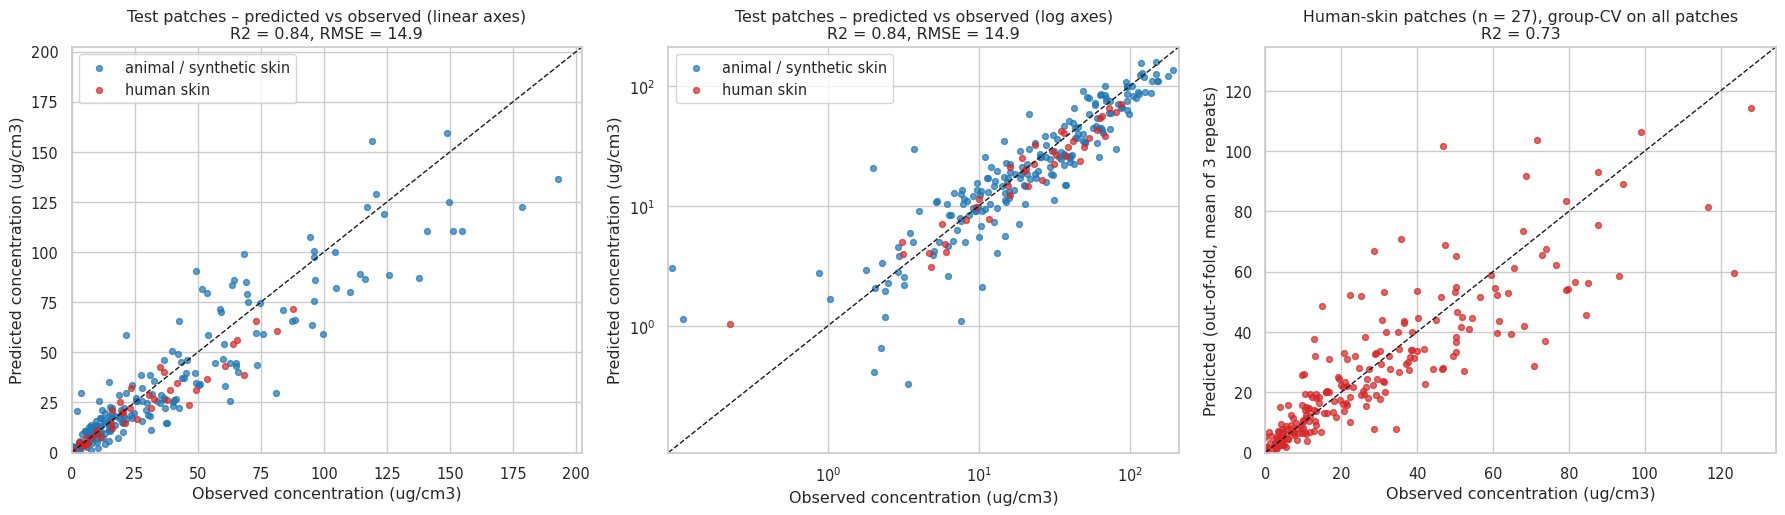

In [28]:
# --- band from development-set CV residuals (used for the prediction intervals in the plots) -------------------
_, dev_oofs = cv_eval(FINAL_SPEC, DEV_IDS, SEEDS)
Ydev = Ydf.loc[DEV_IDS].values
res_log = np.concatenate([np.log1p(o) - np.log1p(Ydev) for o in dev_oofs])           # (3*120, 8): prediction - observation (log1p scale)
RESID_Q = {'q10': np.quantile(res_log, 0.10, axis=0), 'q90': np.quantile(res_log, 0.90, axis=0)}
def band(pred8, q=RESID_Q):
    lo = np.expm1(np.log1p(pred8) - q['q90']); hi = np.expm1(np.log1p(pred8) - q['q10']); return np.clip(lo, 0, None), hi
lo, hi = band(Yp_te); cover = ((Yte >= lo) & (Yte <= hi)).mean(axis=0)
print('Empirical coverage of the 80% band on the TEST patches, by time point:', dict(zip(TIMES, cover.round(2))), '| overall: %.2f' % cover.mean())

def dense_curve(pred8, n=200):
    t = np.linspace(TIMES[0], TIMES[-1], n); return t, np.clip(PchipInterpolator(TIMES_ARR, pred8)(t), 0, None)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
cols = np.where(is_h_te, '#d62728', '#1f77b4')
for ax, scale in zip(axes[:2], ['linear', 'log']):
    for hflag, lab, c in [(False, 'animal / synthetic skin', '#1f77b4'), (True, 'human skin', '#d62728')]:
        msk = np.repeat(is_h_te == hflag, 8); ax.scatter(Yte.ravel()[msk], Yp_te.ravel()[msk], s=18, alpha=.7, c=c, label=lab)
    lim = [0.05, max(Yte.max(), Yp_te.max()) * 1.1] if scale == 'log' else [0, max(Yte.max(), Yp_te.max()) * 1.05]
    ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    if scale == 'log': ax.set_xscale('symlog', linthresh=1); ax.set_yscale('symlog', linthresh=1)
    ax.set_xlabel('Observed concentration (ug/cm3)'); ax.set_ylabel('Predicted concentration (ug/cm3)'); ax.legend()
    ax.set_title(f'Test patches – predicted vs observed ({scale} axes)\nR2 = {r2_score(Yte.ravel(), Yp_te.ravel()):.2f}, RMSE = {mean_squared_error(Yte.ravel(), Yp_te.ravel())**.5:.1f}')
# CV predictions for the 27 human patches (all 150 patches CV)
hm = np.repeat(skin_all.astype(str) == 'Human Skin (Full Thickness)', 8)
oo = np.mean(cv_all_oofs, axis=0)
axes[2].scatter(Yall.ravel()[hm], oo.ravel()[hm], s=18, c='#d62728', alpha=.7); lim = [0, Yall[skin_all == 'Human Skin (Full Thickness)'].max() * 1.05]
axes[2].plot(lim, lim, 'k--', lw=1); axes[2].set_xlim(lim); axes[2].set_ylim(lim)
axes[2].set_xlabel('Observed concentration (ug/cm3)'); axes[2].set_ylabel('Predicted (out-of-fold, mean of 3 repeats)')
axes[2].set_title(f'Human-skin patches (n = {int((skin_all == "Human Skin (Full Thickness)").sum())}), group-CV on all patches\nR2 = {cv_by_skin.loc["Human Skin (Full Thickness)", "R2"]:.2f}')
plt.tight_layout(); savefig('actual_vs_predicted'); plt.show()

Out-of-fold log-scale error (all 150 patches): 28% of the squared error is a constant offset shared by all 8 points of a patch

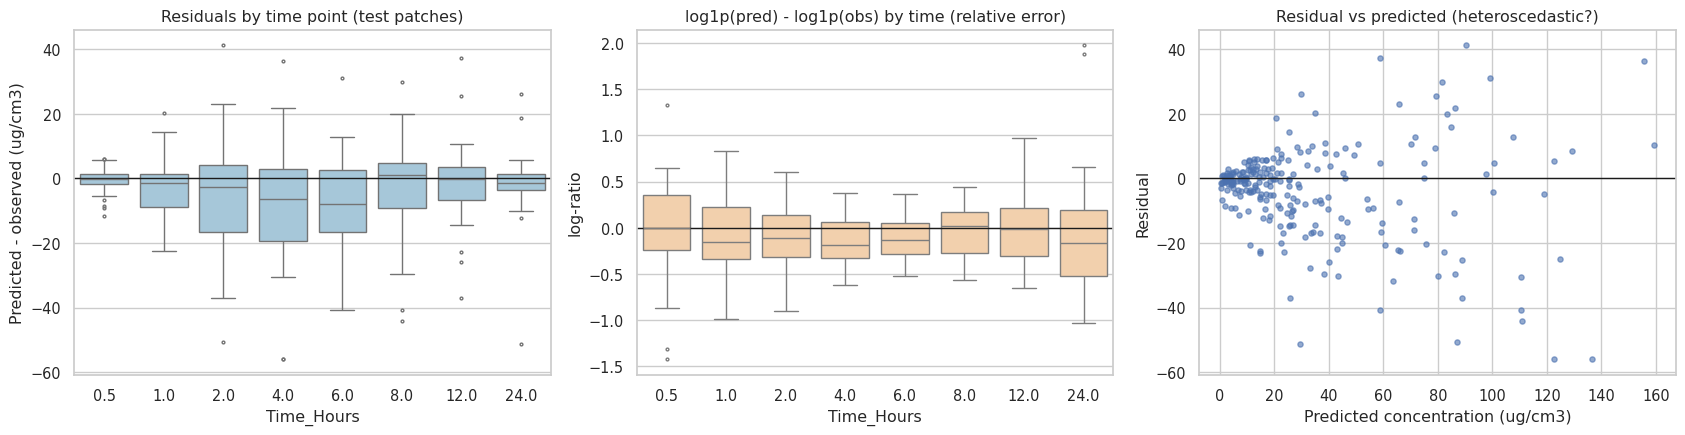

In [29]:
# residual diagnostics
R = Yp_te - Yte
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=pd.DataFrame(R, columns=TIMES).melt(var_name='Time_Hours', value_name='residual'), x='Time_Hours', y='residual', ax=axes[0], color='#9ecae1', fliersize=2)
axes[0].axhline(0, color='k', lw=1); axes[0].set_ylabel('Predicted - observed (ug/cm3)'); axes[0].set_title('Residuals by time point (test patches)')
rl = (np.log1p(Yp_te) - np.log1p(Yte)); sns.boxplot(data=pd.DataFrame(rl, columns=TIMES).melt(var_name='Time_Hours', value_name='log-ratio'), x='Time_Hours', y='log-ratio', ax=axes[1], color='#fdd0a2', fliersize=2)
axes[1].axhline(0, color='k', lw=1); axes[1].set_title('log1p(pred) - log1p(obs) by time (relative error)')
axes[2].scatter(Yp_te.ravel(), R.ravel(), s=14, alpha=.6); axes[2].axhline(0, color='k', lw=1); axes[2].set_xlabel('Predicted concentration (ug/cm3)'); axes[2].set_ylabel('Residual'); axes[2].set_title('Residual vs predicted (heteroscedastic?)')
plt.tight_layout(); savefig('residual_diagnostics'); plt.show()

# is the error mostly a whole-curve offset (patch-level) or point-to-point noise?
RL_all = np.mean([np.log1p(o) - np.log1p(Yall) for o in cv_all_oofs], axis=0)
tot = (RL_all ** 2).mean(); patch_off = (RL_all.mean(1, keepdims=True) ** 2).mean()
print('Out-of-fold log-scale error (all 150 patches): %.0f%% of the squared error is a constant offset shared by all 8 points of a patch' % (100 * patch_off / tot))

**[MODEL]** If most of the error is a *shared offset* within each patch, then the model gets the **shape** of the profile roughly right but the **overall level** of a patch is off by a patch-specific factor. **[ASSUMPTION]** This pattern would be expected if some patch-level determinant of delivery (e.g. true insertion depth, formulation variability, or experimental batch) is not among the recorded features – the data cannot confirm this.

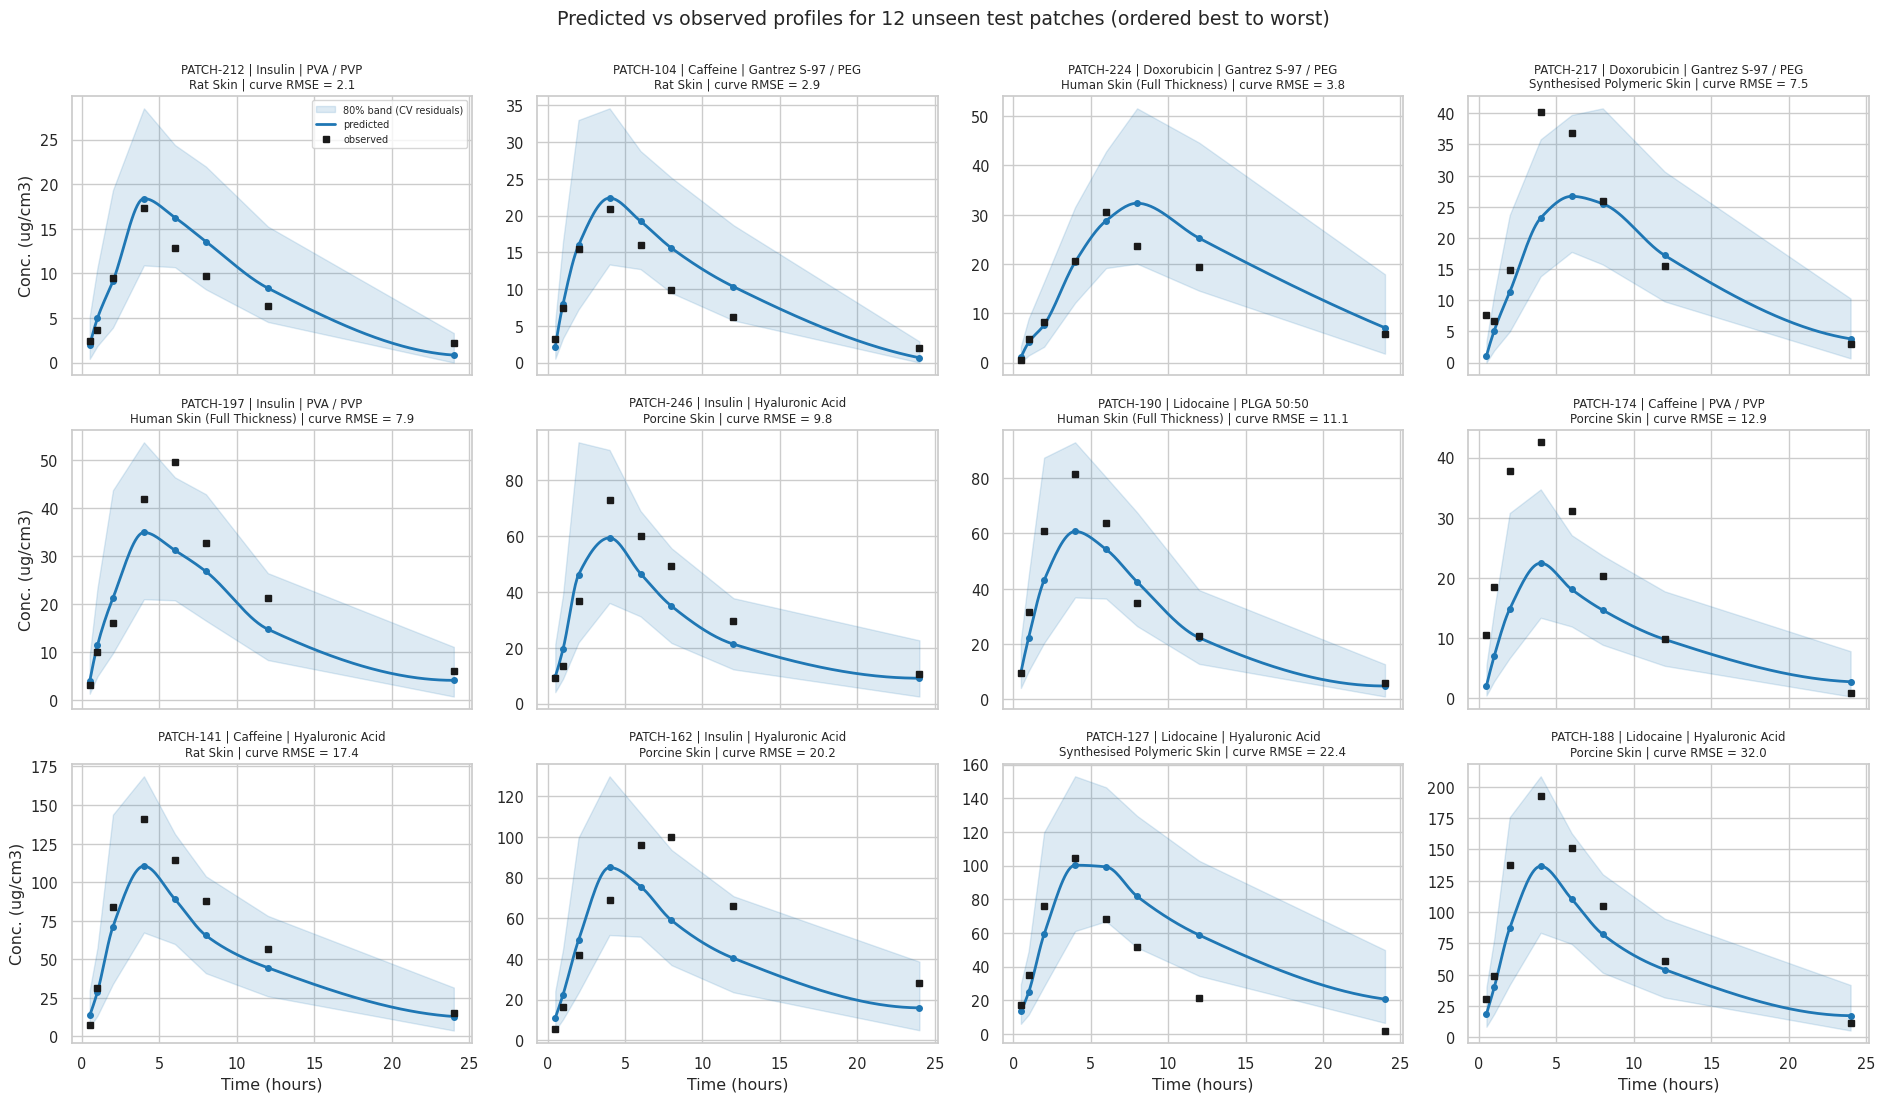

In [30]:
# individual curve-level errors on test patches: pick 12 patches spanning best -> worst curve RMSE
ct = curve_table(Yte, Yp_te, TEST_IDS); order = ct.curve_RMSE.sort_values().index
pick = [order[int(round(i))] for i in np.linspace(0, len(order) - 1, 12)]
fig, axes = plt.subplots(3, 4, figsize=(19, 11), sharex=True)
for ax, pid in zip(axes.ravel(), pick):
    k = list(TEST_IDS).index(pid); tt, cc = dense_curve(Yp_te[k]); l, h = band(Yp_te[k])
    ax.fill_between(TIMES, l, h, color='#1f77b4', alpha=.15, label='80% band (CV residuals)'); ax.plot(tt, cc, '-', color='#1f77b4', lw=2, label='predicted'); ax.plot(TIMES, Yp_te[k], 'o', color='#1f77b4', ms=4)
    ax.plot(TIMES, Yte[k], 's', color='k', ms=5, label='observed')
    r = P.loc[pid]; ax.set_title(f'{pid} | {r.Drug_Name} | {r.MN_Material}\n{r.Skin_Type} | curve RMSE = {ct.loc[pid, "curve_RMSE"]:.1f}', fontsize=8.5)
for ax in axes[-1]: ax.set_xlabel('Time (hours)')
for ax in axes[:, 0]: ax.set_ylabel('Conc. (ug/cm3)')
axes[0, 0].legend(fontsize=7); plt.suptitle('Predicted vs observed profiles for 12 unseen test patches (ordered best to worst)', y=1.0); plt.tight_layout(); savefig('test_curves_grid'); plt.show()

Tmax: exact grid match 70% | within one sampling step 97% | MAE 0.67 h
Reference: always guessing the most common observed Tmax (4 h) gives MAE 1.20 h

Worst 5 test patches by curve RMSE:

,Cmax_obs,Cmax_pred,Tmax_obs,Tmax_pred,AUC_obs,AUC_pred,curve_RMSE,curve_MAE,Cmax_err_%,AUC_err_%,Tmax_err_h,Tmax_step_diff,Drug_Name,Skin_Type,MN_Material
PATCH-188,192.68,136.63,4.0,4.0,1807.48,1441.43,31.99,25.43,-29.09,-20.25,0.0,0,Lidocaine,Porcine Skin,Hyaluronic Acid
PATCH-230,154.90,124.85,8.0,6.0,2593.35,1825.34,28.80,21.18,-19.40,-29.61,-2.0,-1,Caffeine,Porcine Skin,Hyaluronic Acid
PATCH-107,178.46,122.43,4.0,4.0,1519.64,1717.06,26.86,21.09,-31.39,12.99,0.0,0,Caffeine,Porcine Skin,Hyaluronic Acid
PATCH-127,104.41,100.21,4.0,4.0,829.46,1348.69,22.36,18.94,-4.02,62.60,0.0,0,Lidocaine,Synthesised Polymeric Skin,Hyaluronic Acid
PATCH-235,148.97,159.32,6.0,6.0,1670.73,1916.21,21.75,17.18,6.95,14.69,0.0,0,Caffeine,Synthesised Polymeric Skin,PLGA 50:50


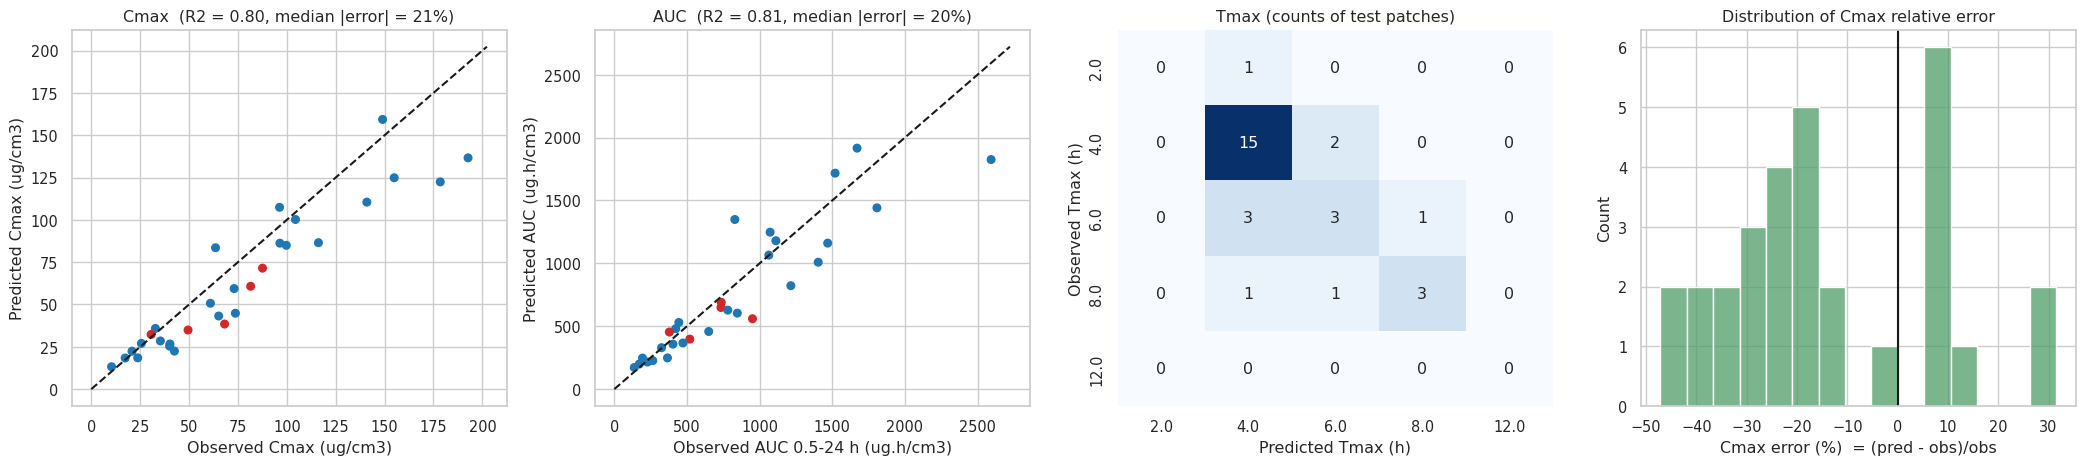

In [31]:
# Cmax / Tmax / AUC agreement on unseen patches (test) 
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
axes[0].scatter(ct.Cmax_obs, ct.Cmax_pred, c=np.where(is_h_te, '#d62728', '#1f77b4'), s=30); lim = [0, max(ct.Cmax_obs.max(), ct.Cmax_pred.max()) * 1.05]; axes[0].plot(lim, lim, 'k--'); axes[0].set_xlabel('Observed Cmax (ug/cm3)'); axes[0].set_ylabel('Predicted Cmax (ug/cm3)')
axes[0].set_title('Cmax  (R2 = %.2f, median |error| = %.0f%%)' % (r2_score(ct.Cmax_obs, ct.Cmax_pred), ct['Cmax_err_%'].abs().median()))
axes[1].scatter(ct.AUC_obs, ct.AUC_pred, c=np.where(is_h_te, '#d62728', '#1f77b4'), s=30); lim = [0, max(ct.AUC_obs.max(), ct.AUC_pred.max()) * 1.05]; axes[1].plot(lim, lim, 'k--'); axes[1].set_xlabel('Observed AUC 0.5-24 h (ug.h/cm3)'); axes[1].set_ylabel('Predicted AUC (ug.h/cm3)')
axes[1].set_title('AUC  (R2 = %.2f, median |error| = %.0f%%)' % (r2_score(ct.AUC_obs, ct.AUC_pred), ct['AUC_err_%'].abs().median()))
cmx = pd.crosstab(ct.Tmax_obs, ct.Tmax_pred).reindex(index=TIMES, columns=TIMES, fill_value=0).loc[[2, 4, 6, 8, 12], [2, 4, 6, 8, 12]]
sns.heatmap(cmx, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2]); axes[2].set_xlabel('Predicted Tmax (h)'); axes[2].set_ylabel('Observed Tmax (h)'); axes[2].set_title('Tmax (counts of test patches)')
sns.histplot(ct['Cmax_err_%'], bins=15, ax=axes[3], color='#4f9d69'); axes[3].axvline(0, color='k'); axes[3].set_xlabel('Cmax error (%)  = (pred - obs)/obs'); axes[3].set_title('Distribution of Cmax relative error')
plt.tight_layout(); savefig('cmax_tmax_auc_agreement'); plt.show()
print('Tmax: exact grid match %.0f%% | within one sampling step %.0f%% | MAE %.2f h' % (100 * (ct.Tmax_step_diff == 0).mean(), 100 * (ct.Tmax_step_diff.abs() <= 1).mean(), ct.Tmax_err_h.abs().mean()))
print('Reference: always guessing the most common observed Tmax (%.0f h) gives MAE %.2f h' % (patch.Tmax_obs.mode()[0], (ct.Tmax_obs - patch.Tmax_obs.mode()[0]).abs().mean()))
print('\nWorst 5 test patches by curve RMSE:'); display(ct.sort_values('curve_RMSE', ascending=False).head(5).join(P[['Drug_Name', 'Skin_Type', 'MN_Material']]).round(2))

**[MODEL] Reading the scores honestly.** The model reproduces the *general* behaviour (rise, peak at several hours, decline) and the dominant dependence on loading, but the Cmax of an individual patch is typically off by a sizeable percentage (see the Cmax panel and the table in Section 11), and many individual patches sit visibly above or below their predicted curve. Tmax is predicted more accurately than the naive reference printed above, mostly within one sampling step. Test-set numbers are based on only 30 patches, hence the wide bootstrap intervals; and the selected model is statistically indistinguishable from plain multi-output linear regression on these 30 patches.

## 13. Human skin: general model (Approach A) vs human-only model (Approach B)

* **Approach A** – general model, `Skin_Type` included as a categorical feature, trained on all other patches.
* **Approach B** – a model trained **only on human-skin patches** (27 in total).
* **Approach C (reference)** – the general model trained **without any human-skin patches** ("zero-shot" transfer from animal and synthetic skin to human skin).

All three are evaluated on the **same** held-out human patches with repeated 5-fold patch-grouped CV over the 27 human patches (training folds for A add all 123 non-human patches). Predictions are always for human patches that were not in that model's training data.

In [32]:
HUMAN_IDS = np.array([i for i in IDS if str(P.loc[i, 'Skin_Type']).startswith('Human')]); NONHUMAN_IDS = np.array([i for i in IDS if i not in set(HUMAN_IDS)])
print('human patches:', len(HUMAN_IDS), '| non-human patches:', len(NONHUMAN_IDS))

def fit_pred(spec, train_ids, test_ids):
    m = fit_model(spec['strategy'], build_model(spec['strategy'], spec['name'], spec['fs'], spec['log'], spec.get('params')), train_ids)
    return predict_profiles(spec['strategy'], m, P.loc[test_ids])

simple = lambda name: {'strategy': FINAL_SPEC['strategy'], 'name': name, 'fs': FINAL_SPEC['fs'], 'log': True}
B_SPECS = {'B: Ridge (default)': simple('Ridge'), 'B: ExtraTrees (default)': simple('ExtraTrees'), 'B: GradientBoosting (default)': simple('GradientBoosting'), 'B: final config re-fitted on human only': FINAL_SPEC}
KEYS = ['A: general model (final config)', 'C: general model without human data'] + list(B_SPECS)
def _human_seed(sd):
    pooled = {k: np.full((len(HUMAN_IDS), 8), np.nan) for k in KEYS}; pos = {p: k for k, p in enumerate(HUMAN_IDS)}
    for tr, te in group_folds(HUMAN_IDS, 5, sd):
        idx = [pos[p] for p in te]
        pooled['A: general model (final config)'][idx] = fit_pred(FINAL_SPEC, np.concatenate([NONHUMAN_IDS, tr]), te)
        pooled['C: general model without human data'][idx] = fit_pred(FINAL_SPEC, NONHUMAN_IDS, te)
        for k, sp in B_SPECS.items(): pooled[k][idx] = fit_pred(sp, tr, te)
    return pooled
t0 = time.time(); H_SEEDS = (0, 1, 2, 3, 4); store = {k: [] for k in KEYS}
for sd in H_SEEDS:
    pooled = cached(f'human_seed_{sd}_{FINAL_KEY[0]}_{FINAL_KEY[1]}', lambda: _human_seed(sd))
    for k in store: store[k].append(pooled[k])
Yh = Ydf.loc[HUMAN_IDS].values
hum_tab = pd.DataFrame({k: pd.DataFrame([evaluate(Yh, o) for o in v]).mean() for k, v in store.items()}).T
hum_tab['R2_sd_over_repeats'] = [pd.Series([r2_score(Yh.ravel(), o.ravel()) for o in v]).std() for v in store.values()]
print(f'Human skin (27 patches), repeated 5-fold group CV x {len(H_SEEDS)}   ({time.time()-t0:.0f}s)')
hum_tab[['R2', 'R2_sd_over_repeats', 'MAE', 'RMSE', 'R2_log1p', 'Cmax_MAE', 'Cmax_medAPE_%', 'Tmax_MAE_h', 'AUC_medAPE_%']].round(3)

human patches: 27 | non-human patches: 123
Human skin (27 patches), repeated 5-fold group CV x 5   (14s)

,R2,R2_sd_over_repeats,MAE,RMSE,R2_log1p,Cmax_MAE,Cmax_medAPE_%,Tmax_MAE_h,AUC_medAPE_%
A: general model (final config),0.754,0.008,8.325,12.810,0.822,11.862,22.480,0.756,19.315
C: general model without human data,0.772,0.000,8.174,12.340,0.816,10.663,18.110,1.037,19.678
B: Ridge (default),0.492,0.048,12.200,18.410,0.641,17.923,29.071,1.185,30.280
B: ExtraTrees (default),0.497,0.053,11.993,18.314,0.662,21.877,32.139,0.667,27.564
B: GradientBoosting (default),0.501,0.032,11.766,18.249,0.653,18.702,30.254,1.319,25.660
B: final config re-fitted on human only,0.089,0.163,15.345,24.587,0.535,23.474,30.883,1.615,29.905


Approach A, human skin: R2 = 0.76, bootstrap 95% interval over patches [0.65, 0.83]
(1s)

approach,A: general + n human,B: human only (Ridge)
n_human_train,,
0,0.791,NaN
5,0.776,-18.745
10,0.747,-0.557
15,0.760,0.270
20,0.773,0.548


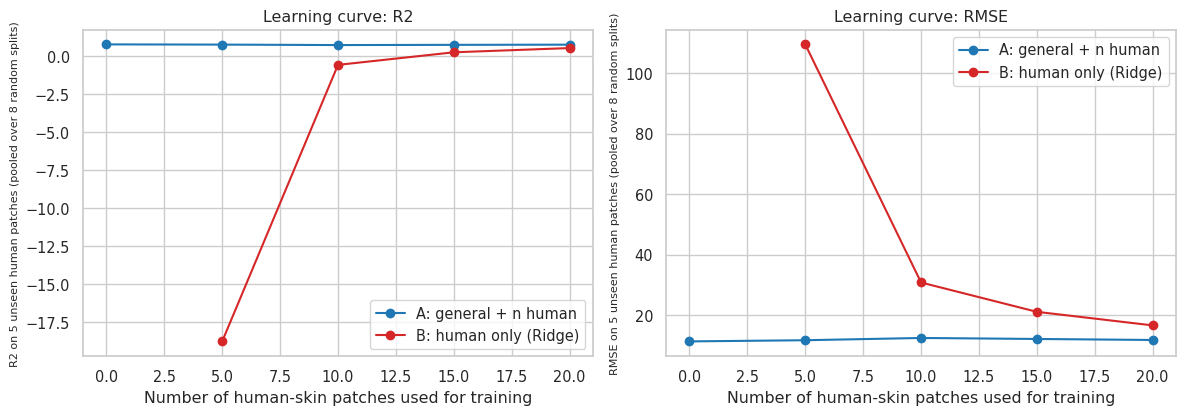

In [33]:
# uncertainty of the human-skin score itself: bootstrap over the 27 patches (A, mean prediction of repeats)
rng = np.random.default_rng(SEED); oA = np.mean(store['A: general model (final config)'], axis=0)
bs = []
for _ in range(2000):
    k = rng.integers(0, len(HUMAN_IDS), len(HUMAN_IDS)); bs.append(r2_score(Yh[k].ravel(), oA[k].ravel()))
print('Approach A, human skin: R2 = %.2f, bootstrap 95%% interval over patches [%.2f, %.2f]' % (r2_score(Yh.ravel(), oA.ravel()), *np.percentile(bs, [2.5, 97.5])))

# learning curve: how does performance on unseen human patches depend on the number of human training patches?
def _learning_curve():
    rng = np.random.default_rng(SEED); LC = []
    SIZES = [5, 10, 15, 20]; N_REP = 8; simple_B = B_SPECS['B: Ridge (default)']
    curves = {'A: general + n human': {s: ([], []) for s in SIZES}, 'B: human only (Ridge)': {s: ([], []) for s in SIZES}}
    C_pred, C_true = [], []
    for rep in range(N_REP):
        perm = rng.permutation(HUMAN_IDS); te = perm[:5]; pool = perm[5:]
        C_pred.append(fit_pred(FINAL_SPEC, NONHUMAN_IDS, te)); C_true.append(Ydf.loc[te].values)
        for s in SIZES:
            tr = pool[:s]
            for key, p in [('A: general + n human', fit_pred(FINAL_SPEC, np.concatenate([NONHUMAN_IDS, tr]), te)), ('B: human only (Ridge)', fit_pred(simple_B, tr, te))]:
                curves[key][s][0].append(p); curves[key][s][1].append(Ydf.loc[te].values)
    lc_rows = [{'n_human_train': 0, 'approach': 'A: general + n human', 'R2': r2_score(np.concatenate(C_true).ravel(), np.concatenate(C_pred).ravel()), 'RMSE': mean_squared_error(np.concatenate(C_true).ravel(), np.concatenate(C_pred).ravel()) ** .5}]
    for key, d in curves.items():
        for s, (pp, tt_) in d.items():
            lc_rows.append({'n_human_train': s, 'approach': key, 'R2': r2_score(np.concatenate(tt_).ravel(), np.concatenate(pp).ravel()), 'RMSE': mean_squared_error(np.concatenate(tt_).ravel(), np.concatenate(pp).ravel()) ** .5})
    lc = pd.DataFrame(lc_rows)
    return lc

t0 = time.time(); N_REP = 8; SIZES = [5, 10, 15, 20]
lc = cached('learning_curve', _learning_curve)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, met in zip(axes, ['R2', 'RMSE']):
    for key, c in [('A: general + n human', '#1f77b4'), ('B: human only (Ridge)', '#d62728')]:
        d = lc[lc.approach == key].sort_values('n_human_train'); ax.plot(d.n_human_train, d[met], '-o', color=c, label=key)
    ax.set_xlabel('Number of human-skin patches used for training'); ax.set_ylabel(met + ' on 5 unseen human patches (pooled over %d random splits)' % N_REP, fontsize=8); ax.legend(); ax.set_title(f'Learning curve: {met}')
plt.tight_layout(); savefig('human_learning_curve'); plt.show()
print(f'({time.time()-t0:.0f}s)'); lc.pivot(index='n_human_train', columns='approach', values='R2').round(3)

In [34]:
# does Skin_Type matter to the general model at all? (ablation with identical group-CV)
spec_noskin = dict(FINAL_SPEC); 
FEATURE_SETS['__final_noskin__'] = (FEATURE_SETS[FINAL_SPEC['fs']][0], [c for c in FEATURE_SETS[FINAL_SPEC['fs']][1] if c != 'Skin_Type']); spec_noskin['fs'] = '__final_noskin__'
m_ns, _ = cv_eval(spec_noskin, IDS, SEEDS)
print('Group-CV over all 150 patches: with Skin_Type  R2 = %.3f, RMSE = %.2f  |  without Skin_Type  R2 = %.3f, RMSE = %.2f' % (cv_all_metrics.R2.mean(), cv_all_metrics.RMSE.mean(), m_ns.R2.mean(), m_ns.RMSE.mean()))

Group-CV over all 150 patches: with Skin_Type  R2 = 0.775, RMSE = 15.59  |  without Skin_Type  R2 = 0.787, RMSE = 15.16

In [35]:
# data-driven summary of the human-skin comparison (computed from the tables above, not hand-written)
nm_A, nm_C = 'A: general model (final config)', 'C: general model without human data'
a, c = hum_tab.loc[nm_A, 'R2'], hum_tab.loc[nm_C, 'R2']
bm = hum_tab.loc[[k for k in hum_tab.index if k.startswith('B:')], 'R2']
lcB = lc[lc.approach == 'B: human only (Ridge)'].set_index('n_human_train').R2; lcA = lc[lc.approach == 'A: general + n human'].set_index('n_human_train').R2
print(f'A  general model, human patches in training      : R2 = {a:.2f}  (CV repeat SD {hum_tab.loc[nm_A, "R2_sd_over_repeats"]:.2f})')
print(f'C  general model, NO human patches in training   : R2 = {c:.2f}')
print(f'B  human-only models                             : R2 = {bm.min():.2f} to {bm.max():.2f}  (best: {bm.idxmax()})')
print()
print('A is', 'at least as good as' if a >= bm.max() - 0.02 else 'worse than', 'the best human-only variant; the gain from adding human patches to the animal/synthetic data (A - C) is %+.2f R2.' % (a - c))
print('Learning curve, human-only Ridge, R2 by number of human training patches:', {int(k): round(v, 2) for k, v in lcB.items()})
print('Learning curve, general model, R2 by number of added human patches      :', {int(k): round(v, 2) for k, v in lcA.items()})
rise = lcB.iloc[-1] - lcB.iloc[0]
print('Human-only model is', 'still improving noticeably' if rise > 0.05 else 'not improving much', 'between %d and %d training patches (change in R2 = %+.2f).' % (lcB.index[0], lcB.index[-1], rise))
print('Sample-size verdict: with 27 human patches (at most 22 for training in each fold) a stand-alone human-only model should be regarded as', 'NOT reliably sufficient.' if (bm.max() < a - 0.02 or rise > 0.05) else 'comparable to the general model, but still very uncertain given the bootstrap interval above.')

A  general model, human patches in training      : R2 = 0.75  (CV repeat SD 0.01)
C  general model, NO human patches in training   : R2 = 0.77
B  human-only models                             : R2 = 0.09 to 0.50  (best: B: GradientBoosting (default))

A is at least as good as the best human-only variant; the gain from adding human patches to the animal/synthetic data (A - C) is -0.02 R2.
Learning curve, human-only Ridge, R2 by number of human training patches: {5: -18.74, 10: -0.56, 15: 0.27, 20: 0.55}
Learning curve, general model, R2 by number of added human patches      : {0: 0.79, 5: 0.78, 10: 0.75, 15: 0.76, 20: 0.77}
Human-only model is still improving noticeably between 5 and 20 training patches (change in R2 = +19.29).
Sample-size verdict: with 27 human patches (at most 22 for training in each fold) a stand-alone human-only model should be regarded as NOT reliably sufficient.

### What can and cannot be concluded about human skin

1. **[MODEL]** The printed comparison above shows which approach predicts *unseen human patches* better in this dataset, and whether a stand-alone human-only model is limited by sample size (learning curve).
2. **[OBSERVED]** The marginal distributions of Cmax / Tmax / AUC overlap across skin types (Section 4), and the skin-type ablation above shows how much the general model relies on `Skin_Type`.
3. **[ASSUMPTION – not supported by this analysis]** That a model trained on porcine, rat or synthetic skin predicts **real human-skin delivery**. The recorded `Skin_Type` and `Skin_Thickness_mm` are the only skin descriptors; barrier properties (stratum corneum, hydration, elasticity), insertion efficiency and clearance are not recorded. Any claim about clinical performance would require independent human-skin experiments on formulations not used for training.
4. The score on 27 human patches carries wide uncertainty (bootstrap interval above); small differences between approaches are not meaningful.

## 14. Scientific interpretation

Interpretation tools used (all computed on **unseen patches** via group-CV or on the fitted model):

* **Grouped permutation importance (CV):** within each held-out fold the values of a feature (or a set of inseparable features) are shuffled across patches and the increase in error is recorded. Drug name / MW / logP / peptide flag are shuffled *together* because they carry the same information.
* **Model coefficients** (the selected model is linear in log-concentration, so its coefficients are directly readable).
* **Partial-dependence / ICE curves:** predicted profiles when one design parameter is varied over its observed range for all 150 patches.
* **Sensitivity table:** change in predicted Cmax / Tmax / AUC when one parameter moves from −1 SD to +1 SD.

**[ASSUMPTION] Importance and partial dependence describe what the model uses to predict, not physical mechanisms.** In an observational dataset with correlated and design-confounded variables they must not be read as causal effects.

(8s)

,Concentration RMSE (ug/cm3),log Cmax RMSE,Tmax MAE (h)
group,,,
Initial drug loading,13.977,0.482,0.019
"Drug identity (name, MW, logP, peptide flag)",7.337,0.181,0.473
MN material / type,3.766,0.060,0.128
Patch area,0.882,0.014,0.079
Needle height,0.348,0.009,-0.016
Applied force,0.062,0.003,0.002
Needle base width,0.048,-0.003,0.034
Needle count,-0.040,-0.002,-0.001
Skin thickness,-0.079,-0.001,0.024


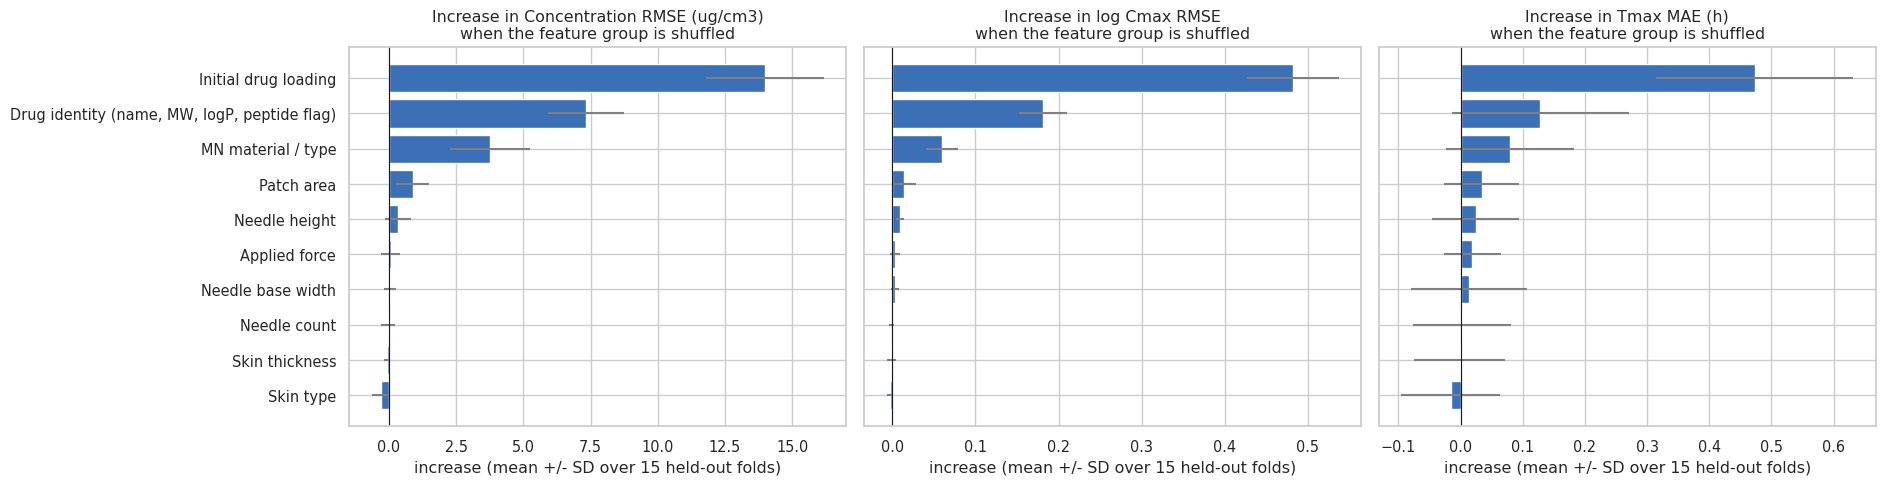

In [36]:
GROUPS = {
    'Drug identity (name, MW, logP, peptide flag)': ['Drug_Name', 'Drug_MW_Da', 'Drug_logP', 'Is_Large_Peptide'],
    'Initial drug loading': ['Initial_Drug_Loading_mg'],
    'Patch area': ['Patch_Area_cm2'],
    'MN material / type': ['MN_Material', 'MN_Type'],
    'Needle count': ['Needle_Count'],
    'Needle height': ['Needle_Height_um'],
    'Needle base width': ['Needle_Base_Width_um'],
    'Applied force': ['Applied_Force_N'],
    'Skin thickness': ['Skin_Thickness_mm'],
    'Skin type': ['Skin_Type'],
}
def _metrics(Yt, Yp):
    cm_t, cm_p = Yt.max(1), Yp.max(1)
    return {'Concentration RMSE (ug/cm3)': mean_squared_error(Yt.ravel(), Yp.ravel()) ** .5,
            'log Cmax RMSE': np.sqrt(np.mean((np.log1p(cm_p) - np.log1p(cm_t)) ** 2)),
            'Tmax MAE (h)': np.mean(np.abs(TIMES_ARR[Yp.argmax(1)] - TIMES_ARR[Yt.argmax(1)]))}

def perm_importance_cv(spec, groups, ids=IDS, seeds=(0, 1, 2), n_repeats=10):
    rng = np.random.default_rng(SEED); rows = []
    for sd in seeds:
        for fold, (tr, te) in enumerate(group_folds(ids, 5, sd)):
            m = fit_model(spec['strategy'], build_model(spec['strategy'], spec['name'], spec['fs'], spec['log'], spec.get('params')), tr)
            Xte = P.loc[te]; Yt = Ydf.loc[te].values; base = _metrics(Yt, predict_profiles(spec['strategy'], m, Xte))
            for g, cols in groups.items():
                for _ in range(n_repeats):
                    perm = rng.permutation(len(te)); Xp = Xte.copy()
                    for c in cols: Xp[c] = Xte[c].values[perm]
                    Xp = add_engineered_features(Xp)
                    mm = _metrics(Yt, predict_profiles(spec['strategy'], m, Xp))
                    rows.append({'seed': sd, 'fold': fold, 'group': g, **{k: mm[k] - base[k] for k in base}})
    return pd.DataFrame(rows)

t0 = time.time(); pi = perm_importance_cv(FINAL_SPEC, GROUPS)
pi_mean = pi.groupby('group').agg(['mean', 'std']); print(f'({time.time()-t0:.0f}s)')
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, met in zip(axes, ['Concentration RMSE (ug/cm3)', 'log Cmax RMSE', 'Tmax MAE (h)']):
    d = pi.groupby(['group', 'seed', 'fold'])[met].mean().groupby('group').agg(['mean', 'std']).sort_values('mean')
    ax.barh(d.index, d['mean'], xerr=d['std'], color='#3b6fb6', ecolor='grey'); ax.axvline(0, color='k', lw=.8)
    ax.set_title('Increase in ' + met + '\nwhen the feature group is shuffled'); ax.set_xlabel('increase (mean +/- SD over 15 held-out folds)')
    if ax is not axes[0]: ax.set_yticklabels([])
plt.tight_layout(); savefig('permutation_importance'); plt.show()
imp_tab = pi.groupby(['group', 'seed', 'fold'])[list(_metrics(Yall[:3], Yall[:3]))].mean().groupby('group').mean().sort_values('Concentration RMSE (ug/cm3)', ascending=False)
imp_tab.round(3)

24 of 26 input columns have non-zero coefficients (Lasso zeroes out the rest).

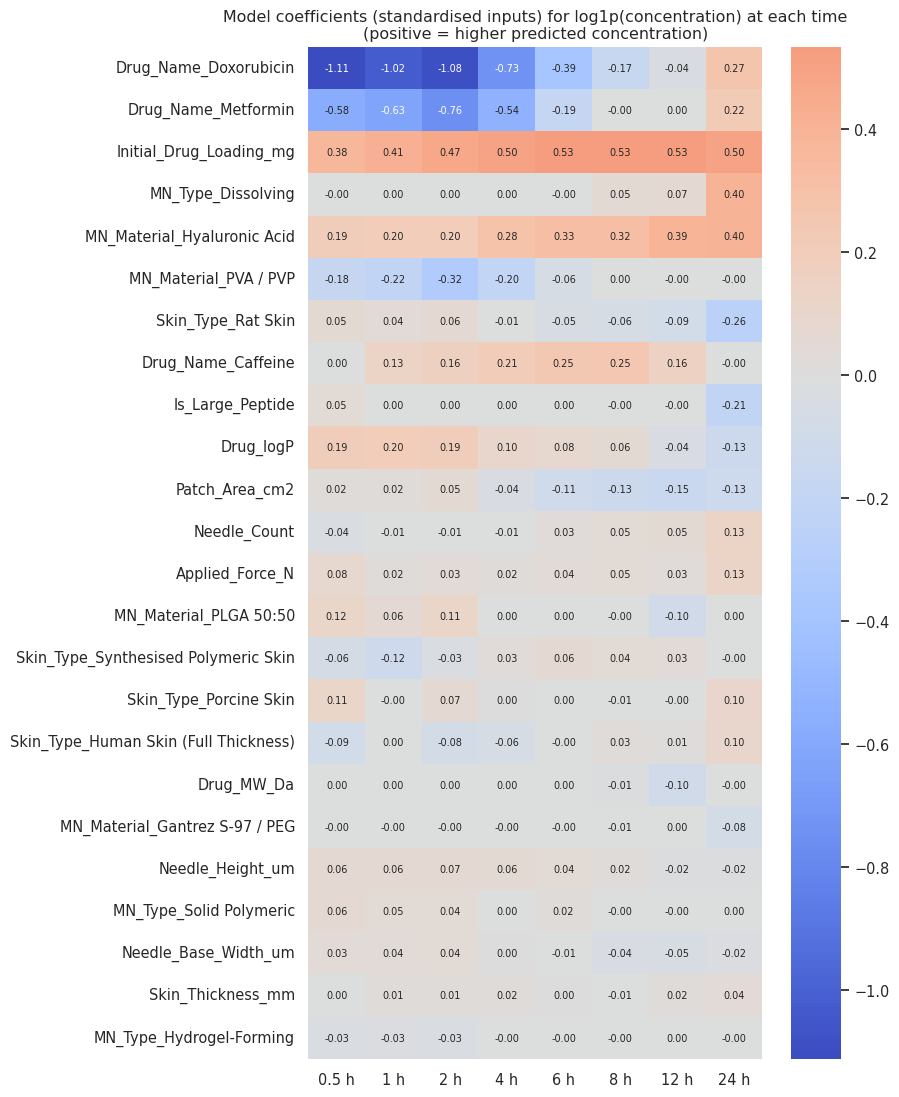

In [37]:
# deployment model = final configuration refitted on all 150 patches (used for interpretation and for the saved model)
final_all = fit_model(FINAL_SPEC['strategy'], build_model(FINAL_SPEC['strategy'], FINAL_SPEC['name'], FINAL_SPEC['fs'], FINAL_SPEC['log'], FINAL_SPEC.get('params')), IDS)
inner = final_all.regressor_ if hasattr(final_all, 'regressor_') else final_all
est = inner.named_steps['model']
if hasattr(est, 'coef_') and np.ndim(est.coef_) == 2:
    names = inner.named_steps['pre'].get_feature_names_out(); coef = pd.DataFrame(est.coef_.T, index=[n.split('__', 1)[-1] for n in names], columns=[f'{t} h' for t in TIMES])
    coef = coef[(coef.abs() > 1e-9).any(axis=1)]
    order = coef.abs().max(axis=1).sort_values(ascending=False).index; coef = coef.loc[order]
    plt.figure(figsize=(9, 0.38 * len(coef) + 2)); sns.heatmap(coef, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
    plt.title('Model coefficients (standardised inputs) for log1p(concentration) at each time\n(positive = higher predicted concentration)'); plt.tight_layout(); savefig('model_coefficients'); plt.show()
    print(f'{len(coef)} of {len(names)} input columns have non-zero coefficients (Lasso zeroes out the rest).')
else:
    print('Final model is not a linear multi-output model; coefficient view skipped.')

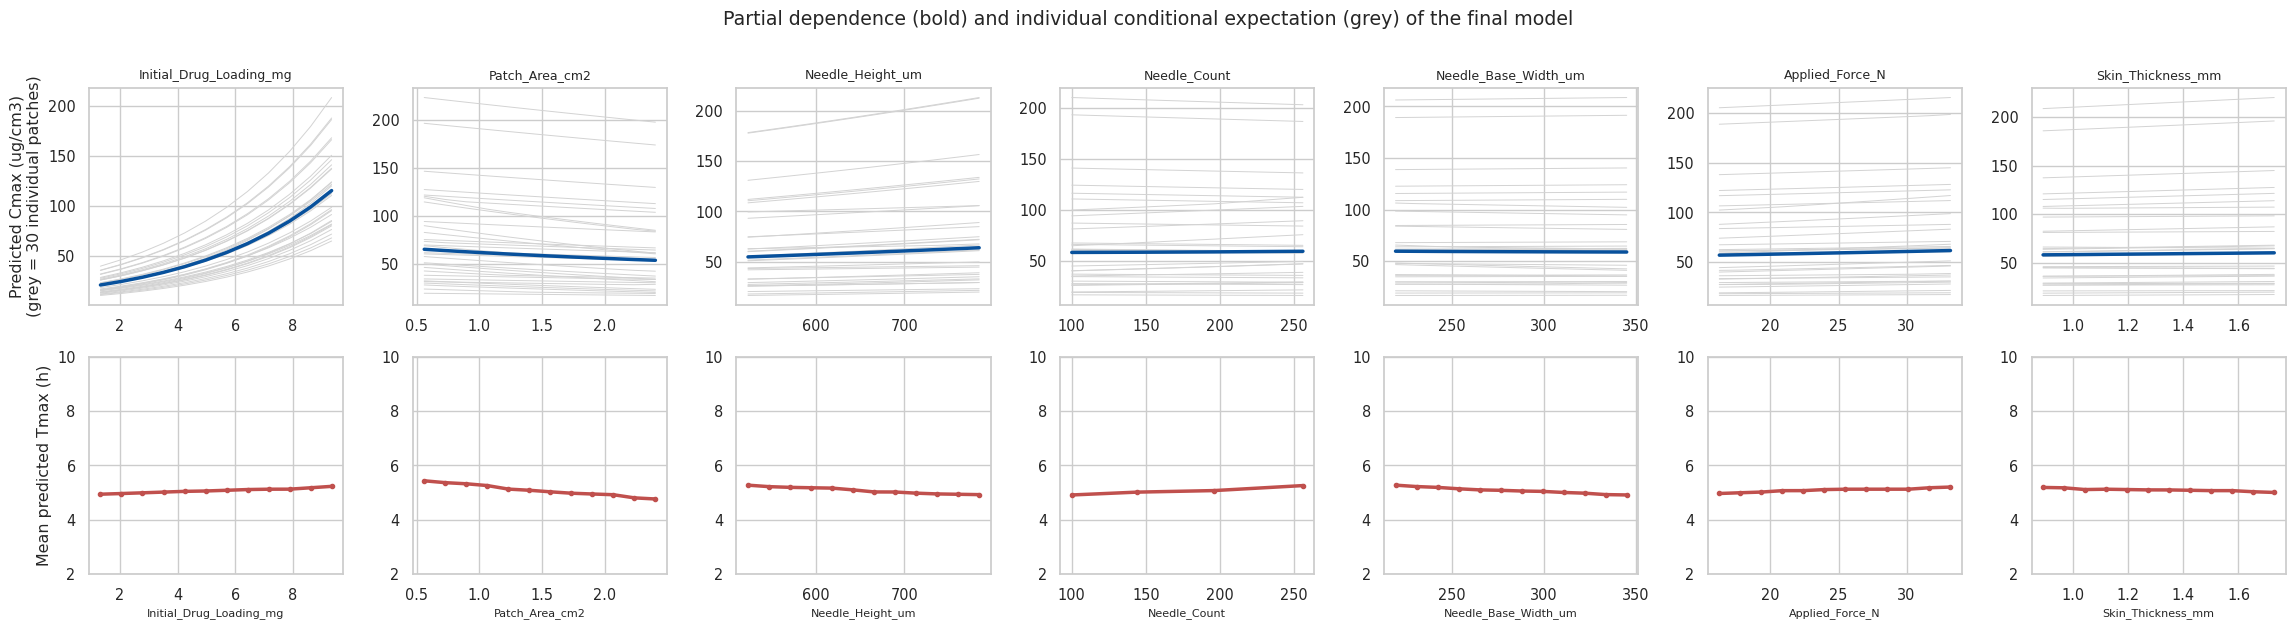

In [38]:
# ---- partial dependence / ICE (patch table with one parameter overridden; all other inputs stay as observed) ----
tgrid = np.linspace(0.5, 24, 241)
def stats_from_pred(pred):                 # pred: (n, 8) -> dense PCHIP curves -> Cmax, Tmax, AUC (trapezoid on the 8 points)
    dense = PchipInterpolator(TIMES_ARR, pred, axis=1)(tgrid)
    return dense.max(1), tgrid[dense.argmax(1)], trapezoid(pred, TIMES_ARR, axis=1)
def predict_table(model, X): return predict_profiles(FINAL_SPEC['strategy'], model, add_engineered_features(X))

PD_FEATS = ['Initial_Drug_Loading_mg', 'Patch_Area_cm2', 'Needle_Height_um', 'Needle_Count', 'Needle_Base_Width_um', 'Applied_Force_N', 'Skin_Thickness_mm']
rng = np.random.default_rng(SEED); ice_ids = rng.choice(len(P), 30, replace=False)
fig, axes = plt.subplots(2, len(PD_FEATS), figsize=(3.3 * len(PD_FEATS), 6.2))
for j, f in enumerate(PD_FEATS):
    grid = np.linspace(P[f].quantile(.05), P[f].quantile(.95), 12)
    if f == 'Needle_Count': grid = np.array([100, 144, 196, 256])
    cm_l, tm_l, au_l = [], [], []
    for v in grid:
        X = P.copy(); X[f] = v; c, t, a = stats_from_pred(predict_table(final_all, X)); cm_l.append(c); tm_l.append(t); au_l.append(a)
    cm_a, tm_a = np.array(cm_l), np.array(tm_l)
    axes[0, j].plot(grid, cm_a[:, ice_ids], color='lightgrey', lw=.7); axes[0, j].plot(grid, cm_a.mean(1), color='#08519c', lw=2.5)
    axes[1, j].plot(grid, tm_a.mean(1), color='#c0504d', lw=2.5, marker='o', ms=3); axes[1, j].set_ylim(2, 10)
    axes[0, j].set_title(f, fontsize=9); axes[1, j].set_xlabel(f, fontsize=8)
axes[0, 0].set_ylabel('Predicted Cmax (ug/cm3)\n(grey = 30 individual patches)'); axes[1, 0].set_ylabel('Mean predicted Tmax (h)')
plt.suptitle('Partial dependence (bold) and individual conditional expectation (grey) of the final model', y=1.01); plt.tight_layout(); savefig('partial_dependence'); plt.show()

,from,to,Cmax change (%),AUC change (%),Tmax change (h)
parameter,,,,,
Initial_Drug_Loading_mg,3.04,7.97,184.26,193.60,0.15
Patch_Area_cm2,0.85,2.10,-12.31,-19.37,-0.42
Needle_Height_um,578.33,744.10,10.28,3.53,-0.24
Needle_Count,119.64,221.75,1.12,8.68,0.20
Needle_Base_Width_um,236.60,318.46,-0.90,-4.90,-0.20
Applied_Force_N,18.59,30.15,5.44,8.92,0.13
Skin_Thickness_mm,1.03,1.57,2.31,3.12,-0.07


mean Cmax  mean Tmax (h)  mean AUC
factor   level                                                          
drug     Caffeine                         78.52           4.30    899.20
         Doxorubicin                      40.26           6.56    580.11
         Insulin                          57.03           4.26    624.18
         Lidocaine                        73.41           4.11    790.40
         Metformin                        43.36           6.75    641.66
material Gantrez S-97 / PEG               56.38           4.82    629.11
         Hyaluronic Acid                  76.71           5.09    963.75
         PLGA 50:50                       56.95           4.74    628.10
         PVA / PVP                        49.46           5.58    638.63
skin     Human Skin (Full Thickness)      57.26           5.35    716.99
         Porcine Skin                     59.15           5.06    724.55
         Rat Skin                         57.70           4.96    666.73
         Synthesised Polymeric Skin       61.50           5.15    736.63

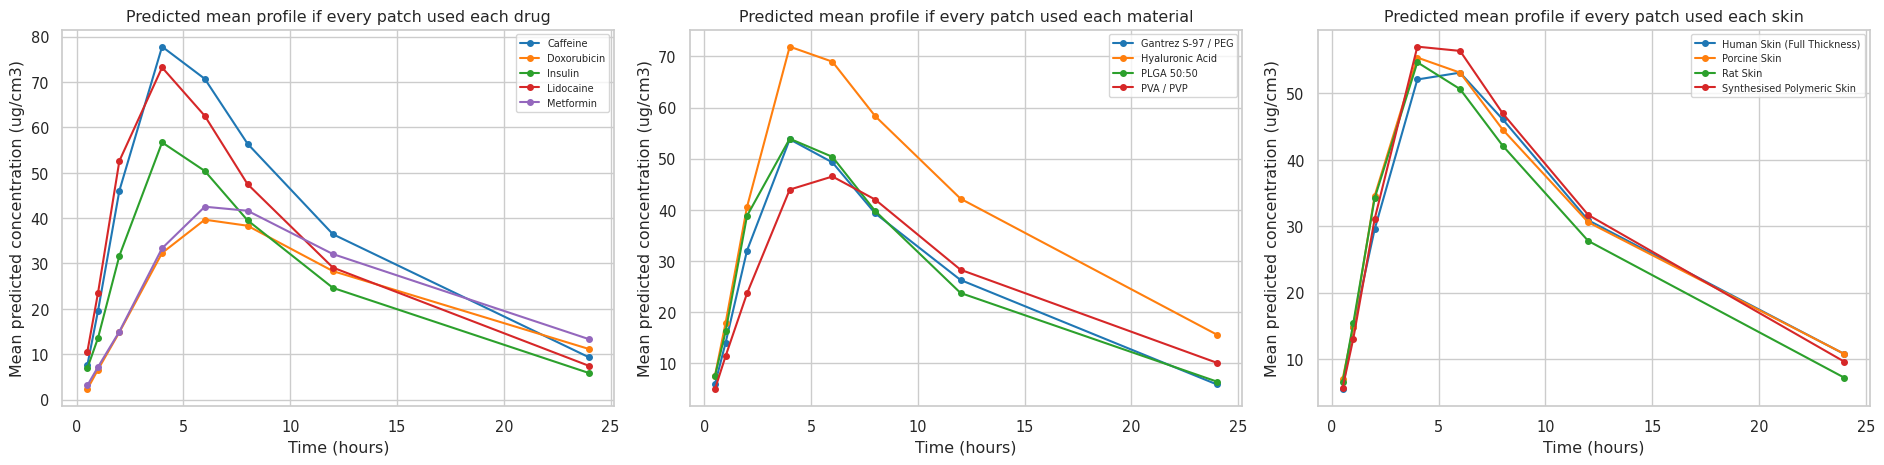

In [39]:
# ---- sensitivity table: -1 SD -> +1 SD for each continuous design parameter ----
rows = []
for f in PD_FEATS:
    mu, sd = P[f].mean(), P[f].std(); res = {}
    for lab, v in [('lo', max(mu - sd, P[f].min())), ('hi', min(mu + sd, P[f].max()))]:
        X = P.copy(); X[f] = v; res[lab] = [x.mean() for x in stats_from_pred(predict_table(final_all, X))]
    rows.append({'parameter': f, 'from': round(max(mu - sd, P[f].min()), 2), 'to': round(min(mu + sd, P[f].max()), 2),
                 'Cmax change (%)': 100 * (res['hi'][0] / res['lo'][0] - 1), 'AUC change (%)': 100 * (res['hi'][2] / res['lo'][2] - 1), 'Tmax change (h)': res['hi'][1] - res['lo'][1]})
sens = pd.DataFrame(rows).set_index('parameter'); display(sens.round(2))

# ---- profile differences between drugs, materials and skin types (all other inputs as observed) ----
def set_category(X, kind, level):
    X = X.copy()
    if kind == 'drug':
        d = raw[raw.Drug_Name == level].iloc[0]; X['Drug_Name'] = level; X['Drug_MW_Da'] = d.Drug_MW_Da; X['Drug_logP'] = d.Drug_logP; X['Is_Large_Peptide'] = d.Is_Large_Peptide
    elif kind == 'material':
        X['MN_Material'] = level; X['MN_Type'] = patch0[patch0.MN_Material == level].MN_Type.iloc[0]
    else: X['Skin_Type'] = level
    return X
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8)); tab = []
for ax, (kind, col) in zip(axes, [('drug', 'Drug_Name'), ('material', 'MN_Material'), ('skin', 'Skin_Type')]):
    for lvl, c in zip(sorted(P[col].unique()), sns.color_palette('tab10')):
        pr = predict_table(final_all, set_category(P, kind, lvl)); cm_, tm_, au_ = stats_from_pred(pr)
        ax.plot(TIMES, pr.mean(0), '-o', color=c, ms=4, label=lvl); tab.append({'factor': kind, 'level': lvl, 'mean Cmax': cm_.mean(), 'mean Tmax (h)': tm_.mean(), 'mean AUC': au_.mean()})
    ax.set_xlabel('Time (hours)'); ax.set_ylabel('Mean predicted concentration (ug/cm3)'); ax.set_title(f'Predicted mean profile if every patch used each {kind}'); ax.legend(fontsize=7)
plt.tight_layout(); savefig('profiles_by_drug_material_skin'); plt.show()
display(pd.DataFrame(tab).set_index(['factor', 'level']).round(2))

In [40]:
# ---- direct look at the observed patch-level data: drug-level Cmax per mg and the confounding of MW / logP ----
drug_tab2 = patch.groupby('Drug_Name').agg(MW=('Drug_MW_Da', 'first'), logP=('Drug_logP', 'first'), n=('Cmax_obs', 'size'), Cmax_per_mg=('Cmax_per_mg', 'median'), Tmax_median=('Tmax_obs', 'median')).sort_values('MW')
display(drug_tab2.round(2))
print('Rank correlation across the five drugs (n = 5, essentially anecdotal):  Cmax/mg vs MW: %.2f | vs logP: %.2f | MW vs logP: %.2f' % (
    stats.spearmanr(drug_tab2.MW, drug_tab2.Cmax_per_mg)[0], stats.spearmanr(drug_tab2.logP, drug_tab2.Cmax_per_mg)[0], stats.spearmanr(drug_tab2.MW, drug_tab2.logP)[0]))

Rank correlation across the five drugs (n = 5, essentially anecdotal):  Cmax/mg vs MW: -0.20 | vs logP: 0.10 | MW vs logP: -0.10

,MW,logP,n,Cmax_per_mg,Tmax_median
Drug_Name,,,,,
Metformin,129.16,-1.40,29,8.52,6.0
Caffeine,194.19,-0.07,28,15.59,4.0
Lidocaine,234.34,2.44,37,14.19,4.0
Doxorubicin,543.52,1.27,28,7.83,6.0
Insulin,5808.00,-1.80,28,10.64,4.0


In [41]:
# ---- optional SHAP view (only if the 'shap' package is installed; NOT executed in the environment that produced this notebook) ----
if HAS_SHAP:
    try:
        from sklearn.ensemble import GradientBoostingRegressor as _GBR
        pre_fs = make_preprocessor(*FEATURE_SETS[FINAL_SPEC['fs']], 'S2', False).fit(P)
        Xs = pre_fs.transform(P); names_s = [n.split('__', 1)[-1] for n in pre_fs.get_feature_names_out()]
        gb = _GBR(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED).fit(Xs, np.log(patch.loc[P.index, 'Cmax_obs']))
        sv = shap.TreeExplainer(gb).shap_values(Xs); shap.summary_plot(sv, Xs, feature_names=names_s, show=False); plt.title('SHAP: drivers of log Cmax (explanatory GBM, fitted on all patches)'); plt.tight_layout(); savefig('shap_logCmax'); plt.show()
    except Exception as e: print('SHAP cell failed:', e)
else:
    print('shap is not installed here - skipping (permutation importance and partial dependence above already cover the same questions).')

shap is not installed here - skipping (permutation importance and partial dependence above already cover the same questions).

### Can the model predict a *new drug*? Leave-one-drug-out test

The final configuration knows the five drugs by name. This test removes **all patches of one drug** from training and predicts them, which is the situation a user faces when typing in an unseen drug's MW and logP. Two feature sets are compared: the selected one and a variant with only the numeric descriptors.

In [42]:
lodo_rows = []
for fs_name, label in [(FINAL_SPEC['fs'], 'final feature set'), ('raw', 'numeric drug descriptors only')]:
    for name in ['Lasso', 'ExtraTrees']:
        sp = {'strategy': 'S2', 'name': name, 'fs': fs_name, 'log': True}
        if name == 'Lasso': sp['params'] = {'alpha': 0.002}
        for drug in sorted(P.Drug_Name.unique()):
            te = P.index[P.Drug_Name == drug].values; tr = P.index[P.Drug_Name != drug].values
            pr = fit_pred(sp, tr, te); e = evaluate(Ydf.loc[te].values, pr)
            lodo_rows.append({'features': label, 'model': name, 'held-out drug': drug, 'R2': e['R2'], 'RMSE': e['RMSE'], 'Cmax_medAPE_%': e['Cmax_medAPE_%']})
lodo = pd.DataFrame(lodo_rows)
display(lodo.pivot_table(index='held-out drug', columns=['features', 'model'], values='R2').round(2))
print('Mean R2 on a completely unseen drug:'); display(lodo.groupby(['features', 'model'])[['R2', 'RMSE', 'Cmax_medAPE_%']].mean().round(2))
print('For comparison, grouped CV on seen drugs (all 150 patches): R2 = %.2f' % cv_all_metrics.R2.mean())

Mean R2 on a completely unseen drug:
For comparison, grouped CV on seen drugs (all 150 patches): R2 = 0.78

features      final feature set        numeric drug descriptors only        
model                ExtraTrees  Lasso                    ExtraTrees   Lasso
held-out drug                                                               
Caffeine                   0.22   0.41                          0.30    0.51
Doxorubicin               -0.37  -0.59                         -0.45   -0.51
Insulin                    0.60 -80.08                          0.54 -148.66
Lidocaine                  0.26   0.23                          0.37   -1.34
Metformin                 -0.15  -0.63                          0.05   -1.72

R2   RMSE  Cmax_medAPE_%
features                      model                                  
final feature set             ExtraTrees   0.11  26.96          50.63
                              Lasso      -16.13  73.48         226.92
numeric drug descriptors only ExtraTrees   0.17  25.96          46.64
                              Lasso      -30.35  96.64         312.20

### Answers to the scientific questions

*(Statements marked [MODEL] refer to the fitted model and the printed tables/plots above; they describe associations in this dataset, not proven mechanisms. Re-check the numbers if you re-run with different data.)*

1. **Which features matter most?** **[MODEL]** Initial drug loading is the dominant predictor of concentration level, followed by drug identity and then microneedle material. Patch area has a small effect; the remaining design parameters contribute little or nothing that the model can use (permutation-importance plot and table).
2. **Loading vs needle geometry?** **[MODEL]** Loading is far stronger: moving loading from −1 SD to +1 SD changes predicted Cmax by roughly a factor of three, whereas the same move in needle height, count or base width changes it by only a few to ~10 % (sensitivity table). **[ASSUMPTION]** This does not show that geometry is physically unimportant – only that, within these ranges and with these data, it carries little detectable signal.
3. **Molecular weight?** **[OBSERVED]** Only five MW values exist and each is welded to a drug, so an MW effect cannot be separated from drug identity. The leave-one-drug-out test shows that the model fails badly on an unseen drug (especially the 5808 Da peptide), i.e. MW is *not* a usable continuous predictor here.
4. **logP?** Same answer as MW – five values, completely confounded with the drug.
5. **Skin thickness?** **[MODEL]** Negligible effect on predicted concentration within the range 0.8–1.8 mm (sensitivity table, permutation importance ≈ 0). **[ASSUMPTION]** Real skin-thickness effects on needle penetration may exist but are not visible here.
6. **Material / type?** **[MODEL]** Hyaluronic-acid dissolving needles give the highest predicted Cmax and AUC when all other inputs are held at their observed values; the other three materials are similar to each other. Because material is confounded with type, and materials were not balanced across drugs, loadings and skins, this is a statement about the dataset, not a ranking of materials in general.
7. **Different drugs?** **[OBSERVED/MODEL]** Metformin and Doxorubicin patches peak later (≈ 6–7 h) than Caffeine, Insulin and Lidocaine patches (≈ 4 h); Caffeine and Lidocaine reach the highest concentration per mg loaded.
8. **Cmax and Tmax?** **[MODEL]** Cmax is governed by loading, drug and material. Tmax is governed almost entirely by drug identity (and a little by material); loading, geometry and skin do not move it appreciably (permutation importance on Tmax error).

**Correlation vs causation.** Every statement above is about statistical associations in an observational (and possibly simulated) dataset. Importance scores are not mechanisms; for example, "drug identity" bundles diffusivity, solubility, charge, size and release kinetics, none of which are separately measured.

## 15. Concentration–time prediction function

The prediction function is written to a stand-alone module (`mn_outputs/mn_predict.py`) so it can be used without this notebook. It

* validates inputs (categories, positive values, **training-range checks**, drug consistency) and returns warnings instead of silently extrapolating,
* predicts the 8 sampled time points with the final model,
* draws a smooth curve through them with shape-preserving PCHIP interpolation (this is an **interpolation of 8 model outputs**, not 200 independent predictions; it never leaves the 0.5–24 h window),
* reports Cmax, Tmax (on the sampled times; PCHIP does not create maxima between nodes) and AUC(0.5–24 h),
* draws an empirical **80 % band** from out-of-fold residuals of the development set (its coverage on the test patches was printed in Section 12),
* optionally overlays observed concentrations.

In [43]:
MODULE_HEADER = '''# mn_predict.py - concentration-time prediction for microneedle patches (generated by the notebook)
import json
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.integrate import trapezoid
'''
MODULE_BODY = r"""
TIME_POINTS = [0.5, 1, 2, 4, 6, 8, 12, 24]
DEFAULT_DIR = Path(__file__).resolve().parent / 'models'
NUMERIC_INPUTS = {'initial_drug_loading_mg': 'Initial_Drug_Loading_mg', 'needle_count': 'Needle_Count', 'needle_height_um': 'Needle_Height_um',
                  'needle_base_width_um': 'Needle_Base_Width_um', 'patch_area_cm2': 'Patch_Area_cm2', 'applied_force_n': 'Applied_Force_N',
                  'skin_thickness_mm': 'Skin_Thickness_mm', 'drug_mw': 'Drug_MW_Da'}

def load_bundle(artifact_dir=DEFAULT_DIR):
    d = Path(artifact_dir)
    return {'model': joblib.load(d / 'final_model_pipeline.joblib'), 'meta': json.loads((d / 'model_metadata.json').read_text())}

def _validate(inp, meta):
    warns = []
    if inp['skin_type'] not in meta['skin_types']:
        raise ValueError('skin_type must be one of %s' % meta['skin_types'])
    if inp['mn_material'] not in meta['material_to_type']:
        raise ValueError('mn_material must be one of %s' % list(meta['material_to_type']))
    for key, col in NUMERIC_INPUTS.items():
        v = inp[key]
        if v is None or not np.isfinite(v) or v <= 0:
            raise ValueError('%s must be a positive number' % key)
        lo, hi = meta['numeric_ranges'][col]
        if v < lo or v > hi:
            warns.append('%s = %g is outside the training range [%g, %g]: the model is not validated there (tree and linear models extrapolate unreliably).' % (key, v, lo, hi))
    if inp['drug_logp'] is None or not np.isfinite(inp['drug_logp']):
        raise ValueError('drug_logp must be a finite number')
    if meta['material_to_type'][inp['mn_material']] != inp['mn_type']:
        warns.append('mn_type "%s" does not match the type seen with material "%s" in the training data ("%s"); the model uses the material.' % (inp['mn_type'], inp['mn_material'], meta['material_to_type'][inp['mn_material']]))
    if inp['drug_name'] in meta['drugs']:
        d = meta['drugs'][inp['drug_name']]
        if abs(inp['drug_mw'] - d['Drug_MW_Da']) / d['Drug_MW_Da'] > 0.02 or abs(inp['drug_logp'] - d['Drug_logP']) > 0.1:
            warns.append('MW/logP differ from the values stored for %s in the training data (%.2f Da, logP %.2f).' % (inp['drug_name'], d['Drug_MW_Da'], d['Drug_logP']))
    else:
        warns.append('Drug "%s" is not one of the %d training drugs %s. Leave-one-drug-out tests showed that predictions for unseen drugs are UNRELIABLE; treat this output as unvalidated.' % (inp['drug_name'], len(meta['drugs']), list(meta['drugs'])))
    if inp['skin_type'].startswith('Human'):
        warns.append('Human skin: only 27 human-skin patches were available for training/validation; no clinical validity is implied.')
    return warns

def _row(inp):
    mw = float(inp['drug_mw'])
    X = pd.DataFrame([{'Drug_Name': inp['drug_name'], 'Skin_Type': inp['skin_type'], 'MN_Material': inp['mn_material'], 'MN_Type': inp['mn_type'],
                       'Skin_Thickness_mm': float(inp['skin_thickness_mm']), 'Patch_Area_cm2': float(inp['patch_area_cm2']), 'Needle_Count': float(inp['needle_count']),
                       'Needle_Height_um': float(inp['needle_height_um']), 'Needle_Base_Width_um': float(inp['needle_base_width_um']),
                       'Applied_Force_N': float(inp['applied_force_n']), 'Initial_Drug_Loading_mg': float(inp['initial_drug_loading_mg']),
                       'Drug_MW_Da': mw, 'Drug_logP': float(inp['drug_logp']), 'Is_Large_Peptide': int(mw > 5000)}])
    return add_engineered_features(X)

def predict8(bundle, X):
    # returns the 8 predicted concentrations (ug/cm3) at TIME_POINTS for a one-row feature table
    model, strat = bundle['model'], bundle['meta']['strategy']
    if strat == 'S1':
        L = pd.concat([X] * 8, ignore_index=True); L['Time_Hours'] = TIME_POINTS
        out = np.asarray(model.predict(L)).reshape(8)
    else:
        out = np.asarray(model.predict(X)).reshape(8)
    return np.clip(out, 0, None)

def _observed(observed):
    if observed is None: return None
    if isinstance(observed, pd.DataFrame):
        return observed['Time_Hours'].to_numpy(float), observed['Skin_Tissue_Conc_ug_cm3'].to_numpy(float)
    if isinstance(observed, dict):
        return np.array(list(observed.keys()), float), np.array(list(observed.values()), float)
    arr = np.asarray(observed, float)
    if arr.shape == (8,): return np.array(TIME_POINTS, float), arr
    raise ValueError('observed must be a dict {time: conc}, a DataFrame, or 8 values at the standard time points')

def plot_profile(res, observed=None, ax=None, title=None, color='#1f77b4', label='Predicted', show_band=True, annotate=True):
    if ax is None: fig, ax = plt.subplots(figsize=(8, 5))
    else: fig = ax.figure
    p = res['profile']; t = np.linspace(0.5, 24, 300)
    ax.plot(t, PchipInterpolator(p.Time_Hours, p.Predicted_ug_cm3)(t), '-', color=color, lw=2.5, label=label)
    ax.plot(p.Time_Hours, p.Predicted_ug_cm3, 'o', color=color, ms=6)
    if show_band:
        ax.fill_between(t, np.clip(PchipInterpolator(p.Time_Hours, p.Lower_80_ug_cm3)(t), 0, None), PchipInterpolator(p.Time_Hours, p.Upper_80_ug_cm3)(t), color=color, alpha=0.15, label='80% band (out-of-fold residuals)')
    ob = _observed(observed)
    if ob is not None: ax.plot(ob[0], ob[1], 's', color='k', ms=6, label='Observed (experiment)')
    s = res['summary']
    if annotate:
        ax.plot([s['Tmax_h']], [s['Cmax_ug_cm3']], '*', color='crimson', ms=16, zorder=5, label='Cmax / Tmax (predicted)')
        ax.annotate('Cmax = %.1f ug/cm3\nTmax = %g h' % (s['Cmax_ug_cm3'], s['Tmax_h']), (s['Tmax_h'], s['Cmax_ug_cm3']), textcoords='offset points', xytext=(14, -4), fontsize=9, color='crimson')
    ax.axvspan(24, 25.5, color='grey', alpha=0.12); ax.set_xlim(0, 25.5); ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (hours)'); ax.set_ylabel('Skin tissue concentration (ug/cm3)')
    ax.set_title(title or 'Predicted concentration-time profile (model range 0.5-24 h)'); ax.legend(fontsize=8, loc='upper right'); ax.grid(alpha=0.3)
    return fig

def predict_mn_profile(drug_name, drug_mw, drug_logp, initial_drug_loading_mg, mn_material, mn_type, needle_count, needle_height_um,
                       needle_base_width_um, patch_area_cm2, applied_force_n, skin_type, skin_thickness_mm,
                       bundle=None, artifact_dir=DEFAULT_DIR, plot=True, observed=None, show_band=True, save_path=None, title=None, verbose=True):
    # Predict the skin-tissue concentration-time profile (0.5-24 h) of a microneedle formulation.
    # Units: MW in Da, loading in mg, height / base width in um, area in cm2, force in N, thickness in mm; output in ug/cm3.
    if bundle is None: bundle = load_bundle(artifact_dir)
    meta = bundle['meta']
    inp = dict(drug_name=drug_name, drug_mw=drug_mw, drug_logp=drug_logp, initial_drug_loading_mg=initial_drug_loading_mg, mn_material=mn_material,
               mn_type=mn_type, needle_count=needle_count, needle_height_um=needle_height_um, needle_base_width_um=needle_base_width_um,
               patch_area_cm2=patch_area_cm2, applied_force_n=applied_force_n, skin_type=skin_type, skin_thickness_mm=skin_thickness_mm)
    warns = _validate(inp, meta)
    pred = predict8(bundle, _row(inp))
    q10, q90 = np.array(meta['resid_q10']), np.array(meta['resid_q90'])
    lo = np.clip(np.expm1(np.log1p(pred) - q90), 0, None); hi = np.expm1(np.log1p(pred) - q10)
    prof = pd.DataFrame({'Time_Hours': TIME_POINTS, 'Predicted_ug_cm3': pred, 'Lower_80_ug_cm3': lo, 'Upper_80_ug_cm3': hi})
    k = int(np.argmax(pred))
    summary = {'Cmax_ug_cm3': float(pred[k]), 'Tmax_h': float(TIME_POINTS[k]), 'AUC_0.5_24h_ug_h_cm3': float(trapezoid(pred, TIME_POINTS))}
    res = {'profile': prof, 'summary': summary, 'warnings': warns, 'inputs': inp, 'figure': None}
    if verbose:
        for w in warns: print('WARNING:', w)
    if plot:
        res['figure'] = plot_profile(res, observed, title=title, show_band=show_band)
        if save_path: res['figure'].savefig(save_path, dpi=150, bbox_inches='tight')
    return res
"""
PREDICT_SRC = MODULE_HEADER + FEATURE_SRC + MODULE_BODY
(OUT / 'mn_predict.py').write_text(PREDICT_SRC)
print('written', OUT / 'mn_predict.py', '|', len(PREDICT_SRC.splitlines()), 'lines')

written mn_outputs/mn_predict.py | 133 lines

In [44]:
# ---- bundles: deployment model (all 150 patches) and the development-only model (never saw the 30 test patches) ----
def clean(v): return float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v)
num_f, cat_f = FEATURE_SETS[FINAL_SPEC['fs']]
META = {
    'description': 'Predicts skin-tissue drug concentration (ug/cm3) at 0.5, 1, 2, 4, 6, 8, 12, 24 h after microneedle application.',
    'strategy': FINAL_SPEC['strategy'], 'model': FINAL_SPEC['name'], 'log1p_target': bool(FINAL_SPEC['log']), 'hyperparameters': {k: clean(v) for k, v in (FINAL_SPEC.get('params') or {}).items()},
    'feature_set': FINAL_SPEC['fs'], 'numeric_features': list(num_f), 'categorical_features': list(cat_f), 'time_points': TIMES, 'seed': SEED,
    'drugs': {d: {'Drug_MW_Da': float(g.Drug_MW_Da.iloc[0]), 'Drug_logP': float(g.Drug_logP.iloc[0]), 'Is_Large_Peptide': int(g.Is_Large_Peptide.iloc[0])} for d, g in raw.groupby('Drug_Name')},
    'material_to_type': patch0.groupby('MN_Material').MN_Type.first().to_dict(), 'skin_types': sorted(P.Skin_Type.unique()),
    'numeric_ranges': {c: [float(P[c].min()), float(P[c].max())] for c in RAW_NUM}, 'resid_q10': [float(x) for x in RESID_Q['q10']], 'resid_q90': [float(x) for x in RESID_Q['q90']],
    'band_definition': '80% band = expm1(log1p(pred) - q90) .. expm1(log1p(pred) - q10); q are quantiles of out-of-fold (log1p(pred) - log1p(obs)) on development patches',
    'trained_on_patches': int(len(IDS)),
    'validation': {'test_30_unseen_patches': {k: float(v) for k, v in test_tab.loc[[i for i in test_tab.index if 'SELECTED' in i][0]].items()},
                   'group_cv_all_150_patches': {k: float(v) for k, v in cv_by_skin.loc['all 150 patches'].items()},
                   'group_cv_human_skin_27_patches': {k: float(v) for k, v in cv_by_skin.loc['Human Skin (Full Thickness)'].items()}},
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__},
    'limitations': ['Trained on 5 drugs only: unseen drugs are not predicted reliably.', 'MN_Type is determined by MN_Material.', 'Human-skin accuracy rests on 27 patches; animal/synthetic skin data cannot establish clinical validity.',
                    'Valid only inside the training ranges and 0.5-24 h.'],
}
BUNDLE = {'model': final_all, 'meta': META}
BUNDLE_DEV = {'model': final_dev_model, 'meta': META}
sys.path.insert(0, str(OUT)); import importlib; mn_predict = importlib.import_module('mn_predict'); importlib.reload(mn_predict)

# consistency test: the stand-alone function must reproduce the pipeline for every patch
KW = lambda pid: dict(drug_name=P.loc[pid, 'Drug_Name'], drug_mw=P.loc[pid, 'Drug_MW_Da'], drug_logp=P.loc[pid, 'Drug_logP'], initial_drug_loading_mg=P.loc[pid, 'Initial_Drug_Loading_mg'],
                      mn_material=P.loc[pid, 'MN_Material'], mn_type=P.loc[pid, 'MN_Type'], needle_count=P.loc[pid, 'Needle_Count'], needle_height_um=P.loc[pid, 'Needle_Height_um'],
                      needle_base_width_um=P.loc[pid, 'Needle_Base_Width_um'], patch_area_cm2=P.loc[pid, 'Patch_Area_cm2'], applied_force_n=P.loc[pid, 'Applied_Force_N'],
                      skin_type=P.loc[pid, 'Skin_Type'], skin_thickness_mm=P.loc[pid, 'Skin_Thickness_mm'])
ref = predict_profiles(FINAL_SPEC['strategy'], final_all, P)
got = np.vstack([mn_predict.predict_mn_profile(**KW(pid), bundle=BUNDLE, plot=False, verbose=False)['profile'].Predicted_ug_cm3.values for pid in P.index])
print('max |function - pipeline| over all 150 patches x 8 times:', float(np.abs(ref - got).max()))
assert np.allclose(ref, got, atol=1e-8)

max |function - pipeline| over all 150 patches x 8 times: 9.947598300641403e-14

## 16. Predictions for new microneedle formulations

### 16a. An unseen human-skin test patch (model trained on the development patches only)
This patch was **not** used for training or tuning of the model below; the observed points are shown for comparison.

{'Cmax_ug_cm3': 38.46066997020441, 'Tmax_h': 8.0, 'AUC_0.5_24h_ug_h_cm3': 559.710935661744}

,Time_Hours,Predicted_ug_cm3,Lower_80_ug_cm3,Upper_80_ug_cm3
0,0.5,3.08,0.95,7.56
1,1.0,7.73,3.19,16.04
2,2.0,14.54,6.54,30.18
3,4.0,26.33,15.76,40.58
4,6.0,36.72,24.56,54.51
5,8.0,38.46,23.94,61.25
6,12.0,23.77,13.71,42.05
7,24.0,16.61,5.13,40.34


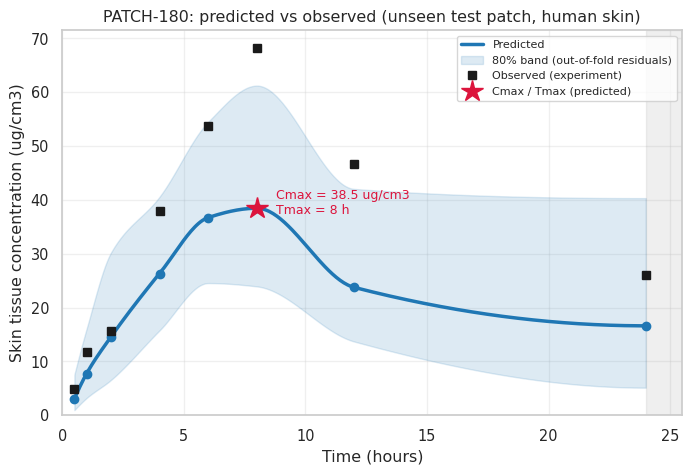

In [45]:
hum_test = [p for p in TEST_IDS if str(P.loc[p, 'Skin_Type']).startswith('Human')]
pid = hum_test[0]
res_a = mn_predict.predict_mn_profile(**KW(pid), bundle=BUNDLE_DEV, observed=Ydf.loc[pid].to_dict(), title=f'{pid}: predicted vs observed (unseen test patch, human skin)', save_path=OUT / 'figures' / 'prediction_unseen_human_test_patch.png')
plt.show()
display(res_a['profile'].round(2)); print(res_a['summary'])

### 16b. A new hypothetical formulation
Lidocaine in a hyaluronic-acid dissolving patch applied to human skin. All inputs lie inside the training ranges.

{'Cmax_ug_cm3': 86.64941295715319, 'Tmax_h': 4.0, 'AUC_0.5_24h_ug_h_cm3': 1029.5940722227233}

,Time_Hours,Predicted_ug_cm3,Lower_80_ug_cm3,Upper_80_ug_cm3
0,0.5,11.03,4.76,24.21
1,1.0,29.35,13.57,58.25
2,2.0,57.95,27.60,117.25
3,4.0,86.65,52.75,132.37
4,6.0,77.61,52.26,114.67
5,8.0,61.63,38.59,97.80
6,12.0,39.98,23.33,70.23
7,24.0,14.11,4.25,34.46


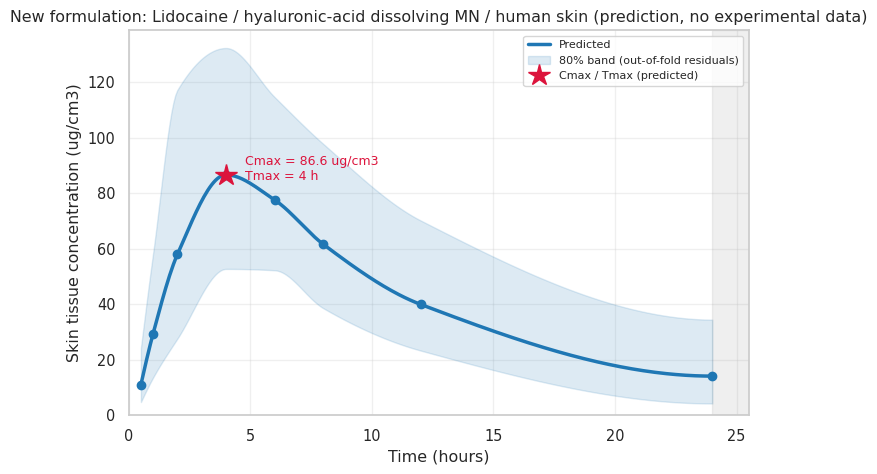

In [46]:
NEW = dict(drug_name='Lidocaine', drug_mw=234.34, drug_logp=2.44, initial_drug_loading_mg=6.0, mn_material='Hyaluronic Acid', mn_type='Dissolving',
           needle_count=196, needle_height_um=650, needle_base_width_um=280, patch_area_cm2=1.5, applied_force_n=25, skin_type='Human Skin (Full Thickness)', skin_thickness_mm=1.25)
res_b = mn_predict.predict_mn_profile(**NEW, bundle=BUNDLE, title='New formulation: Lidocaine / hyaluronic-acid dissolving MN / human skin (prediction, no experimental data)', save_path=OUT / 'figures' / 'prediction_new_formulation.png')
plt.show()
display(res_b['profile'].round(2)); print(res_b['summary'])

### 16c. What-if comparisons (design exploration)
Each curve changes one input of the formulation above. **[MODEL]** These are predictions of what the fitted model associates with the change – not demonstrated causal effects.

,varied,value,Cmax_ug_cm3,Tmax_h,AUC_0.5_24h_ug_h_cm3
0,Initial drug loading (mg),3.0,46.58,4.0,539.09
1,Initial drug loading (mg),6.0,86.65,4.0,1029.59
2,Initial drug loading (mg),9.0,160.45,4.0,1949.63
3,Patch area (cm2),1.0,89.59,4.0,1118.13
4,Patch area (cm2),1.5,86.65,4.0,1029.59
5,Patch area (cm2),2.0,83.81,4.0,950.47
6,Needle height (um),550,80.91,4.0,1006.17
7,Needle height (um),650,86.65,4.0,1029.59
8,Needle height (um),750,92.79,4.0,1055.14
9,Material,Hyaluronic Acid,86.65,4.0,1029.59


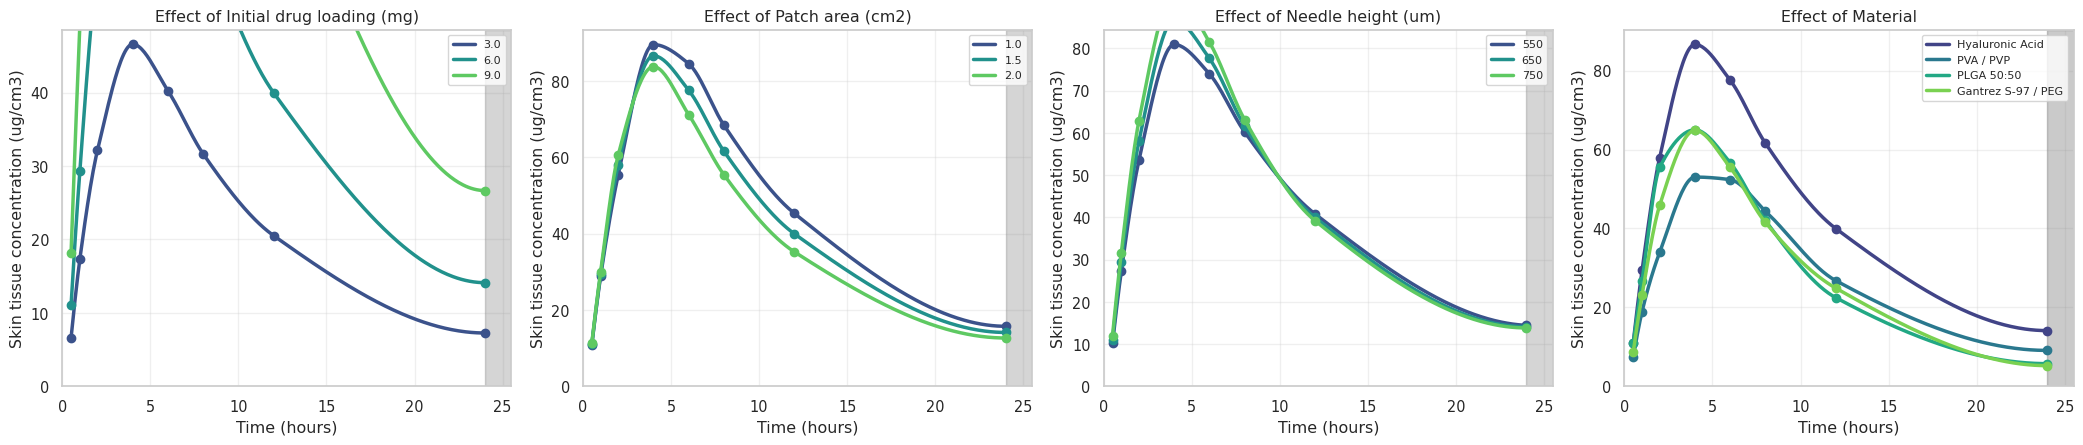

In [47]:
variants = {'Initial drug loading (mg)': ('initial_drug_loading_mg', [3.0, 6.0, 9.0]), 'Patch area (cm2)': ('patch_area_cm2', [1.0, 1.5, 2.0]),
            'Needle height (um)': ('needle_height_um', [550, 650, 750]), 'Material': ('mn_material', ['Hyaluronic Acid', 'PVA / PVP', 'PLGA 50:50', 'Gantrez S-97 / PEG'])}
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6)); rows = []
for ax, (lab, (key, vals)) in zip(axes, variants.items()):
    for v, c in zip(vals, sns.color_palette('viridis', len(vals))):
        kw = dict(NEW); kw[key] = v
        if key == 'mn_material': kw['mn_type'] = META['material_to_type'][v]
        r = mn_predict.predict_mn_profile(**kw, bundle=BUNDLE, plot=False, verbose=False)
        mn_predict.plot_profile(r, ax=ax, color=c, label=str(v), show_band=False, annotate=False, title=f'Effect of {lab}')
        rows.append({'varied': lab, 'value': v, **r['summary']})
plt.tight_layout(); savefig('what_if_comparisons'); plt.show()
display(pd.DataFrame(rows).round(2))

### 16d. Input checks: out-of-range and unseen-drug warnings

In [48]:
bad = dict(NEW); bad['initial_drug_loading_mg'] = 20.0; bad['needle_height_um'] = 1200
_ = mn_predict.predict_mn_profile(**bad, bundle=BUNDLE, plot=False)
print()
new_drug = dict(NEW); new_drug.update(drug_name='Ibuprofen', drug_mw=206.29, drug_logp=3.97)
_ = mn_predict.predict_mn_profile(**new_drug, bundle=BUNDLE, plot=False)
print()
try: mn_predict.predict_mn_profile(**{**NEW, 'skin_type': 'Mouse skin'}, bundle=BUNDLE, plot=False)
except ValueError as e: print('ValueError (as intended):', e)



ValueError (as intended): skin_type must be one of ['Human Skin (Full Thickness)', 'Porcine Skin', 'Rat Skin', 'Synthesised Polymeric Skin']

## 17. Saving the trained model, preprocessing pipeline and reports

* `final_model_pipeline.joblib` – the complete fitted model (preprocessing + estimator + log1p back-transform) trained on all 150 patches.
* `preprocessor.joblib` – the fitted preprocessing step (scaler + one-hot encoder) alone.
* `model_metadata.json` – inputs, ranges, drug table, residual quantiles, validation metrics, library versions.
* `mn_predict.py` – the stand-alone prediction module (Section 15); `reports/*.csv` – performance tables.

In [49]:
MD = OUT / 'models'; RP = OUT / 'reports'; RP.mkdir(exist_ok=True)
joblib.dump(final_all, MD / 'final_model_pipeline.joblib')
inner_all = final_all.regressor_ if hasattr(final_all, 'regressor_') else final_all
joblib.dump(inner_all.named_steps['pre'], MD / 'preprocessor.joblib')
(MD / 'model_metadata.json').write_text(json.dumps(META, indent=2))

for name, df_ in {'model_comparison_default_hyperparameters': cmp_tab, 'tuned_models': tuned_tab.assign(best_params=tuned_tab.best_params.astype(str)), 'test_set_results': test_tab,
                  'cv_all_patches_by_skin_type': cv_by_skin, 'human_skin_approaches': hum_tab, 'human_learning_curve': lc, 'leave_one_drug_out': lodo,
                  'permutation_importance': imp_tab, 'sensitivity_table': sens, 'feature_set_ablation': abl_piv, 'baseline': baseline_tab}.items():
    df_.to_csv(RP / f'{name}.csv')

# reload test: a fresh bundle from disk must reproduce the in-memory predictions
b2 = mn_predict.load_bundle(MD)
chk = [np.abs(mn_predict.predict_mn_profile(**KW(p), bundle=b2, plot=False, verbose=False)['profile'].Predicted_ug_cm3.values - got[list(P.index).index(p)]).max() for p in P.index[:10]]
print('max difference after reloading from disk:', max(chk)); assert max(chk) < 1e-9
for f in sorted(OUT.rglob('*')):
    if f.is_file() and f.suffix in ('.joblib', '.json', '.py', '.csv'): print(f'{str(f):70s} {f.stat().st_size/1024:8.1f} KB')

max difference after reloading from disk: 0.0
mn_outputs/cache/abl_raw+DrugName+MN_Type_S1_ExtraTrees.joblib              0.2 KB
mn_outputs/cache/abl_raw+DrugName+MN_Type_S1_Ridge.joblib                   0.2 KB
mn_outputs/cache/abl_raw+DrugName+MN_Type_S2_ExtraTrees.joblib              0.2 KB
mn_outputs/cache/abl_raw+DrugName+MN_Type_S2_GradientBoosting.joblib        0.2 KB
mn_outputs/cache/abl_raw+DrugName+MN_Type_S2_Ridge.joblib                   0.2 KB
mn_outputs/cache/abl_raw+ratios+interactions_S1_ExtraTrees.joblib           0.2 KB
mn_outputs/cache/abl_raw+ratios+interactions_S1_Ridge.joblib                0.2 KB
mn_outputs/cache/abl_raw+ratios+interactions_S2_ExtraTrees.joblib           0.2 KB
mn_outputs/cache/abl_raw+ratios+interactions_S2_GradientBoosting.joblib      0.2 KB
mn_outputs/cache/abl_raw+ratios+interactions_S2_Ridge.joblib                0.2 KB
mn_outputs/cache/abl_raw+ratios_S1_ExtraTrees.joblib                        0.2 KB
mn_outputs/cache/abl_raw+ratios_S1_Ridge

## Summary of what was and was not established

In [50]:
best_cv = cand.iloc[0]
tf = test_tab.loc[[i for i in test_tab.index if 'SELECTED' in i][0]]; tb = test_tab.loc['Baseline: S2 LinearRegression']
print('VALIDATION  all splits grouped by Patch_ID; 120 development patches for comparison/tuning (5-fold x 3 repeats), 30 untouched test patches.')
print(f'SELECTED    {FINAL_KEY[0]} {FINAL_KEY[1]} (log1p target, feature set "{FINAL_SPEC["fs"]}") - lowest dev-CV RMSE {best_cv.RMSE:.2f} (R2 {best_cv.R2:.3f}).')
print(f'TEST (n=30) R2 {tf.R2:.3f}, MAE {tf.MAE:.2f}, RMSE {tf.RMSE:.2f} ug/cm3 | Cmax median abs error {tf["Cmax_medAPE_%"]:.0f}% | Tmax MAE {tf.Tmax_MAE_h:.2f} h | AUC median abs error {tf["AUC_medAPE_%"]:.0f}%')
print(f'            plain multi-output linear regression baseline on the same test patches: R2 {tb.R2:.3f}, RMSE {tb.RMSE:.2f}  -> difference to selected model {tf.R2 - tb.R2:+.3f} R2 (not a meaningful gap with 30 patches).')
print(f'HUMAN SKIN  group-CV over all patches (27 human): R2 {cv_by_skin.loc["Human Skin (Full Thickness)", "R2"]:.2f}, Cmax median abs error {cv_by_skin.loc["Human Skin (Full Thickness)", "Cmax_medAPE_%"]:.0f}%.')
print(f'NEW DRUG    leave-one-drug-out mean R2: ' + ', '.join(f'{k[1]} ({k[0]}) {v:.2f}' for k, v in lodo.groupby(['features', 'model']).R2.mean().items()))
print('Best linear/trees ordering and all other numbers: see reports/*.csv')

VALIDATION  all splits grouped by Patch_ID; 120 development patches for comparison/tuning (5-fold x 3 repeats), 30 untouched test patches.
SELECTED    S2 Lasso (log1p target, feature set "raw+DrugName+MN_Type") - lowest dev-CV RMSE 15.89 (R2 0.747).
TEST (n=30) R2 0.841, MAE 9.86, RMSE 14.93 ug/cm3 | Cmax median abs error 21% | Tmax MAE 0.67 h | AUC median abs error 20%
            plain multi-output linear regression baseline on the same test patches: R2 0.844, RMSE 14.78  -> difference to selected model -0.003 R2 (not a meaningful gap with 30 patches).
HUMAN SKIN  group-CV over all patches (27 human): R2 0.73, Cmax median abs error 22%.
NEW DRUG    leave-one-drug-out mean R2: ExtraTrees (final feature set) 0.11, Lasso (final feature set) -16.13, ExtraTrees (numeric drug descriptors only) 0.17, Lasso (numeric drug descriptors only) -30.35
Best linear/trees ordering and all other numbers: see reports/*.csv